# Project A — Phase A1: EEG Seizure Detection as Image (CHB-MIT)

**Objective:** Build an end-to-end, clinically rigorous seizure detection pipeline on the **CHB-MIT Scalp EEG** dataset (23 unique patients, 256 Hz, bipolar montage), progressing from raw EDF signals to time-frequency image representations (`STFT` and `CWT`), classical baseline modeling (`Band Power + XGBoost`), deep learning (`SimpleCNN` vs. pretrained `ResNet18` via `timm`), input representation ablation, and dual-level evaluation (`Window-based` vs. `Event-based`).

### Pipeline Roadmap
1. **Step 0:** Environment, Imports & Global Configuration
2. **Step 1:** CHB-MIT Dataset Audit & Clean Manifest Generation
3. **Step 2:** Zero-Leakage Patient-Level Data Splitting (`GroupKFold` / `LOSO`)
4. **Step 3:** Signal Preprocessing, Windowing & Optimized Storage
5. **Step 4:** Classical Baseline — Band Power Features + `XGBoost`
6. **Step 5:** Signal-to-Image Transformation (`STFT` Spectrograms & `CWT` Scalograms)
7. **Step 6:** Deep Learning Modeling (`SimpleCNN` vs. Pretrained `ResNet18` via `timm`)
8. **Step 7:** Ablation Study #1 (`STFT` vs. `CWT` vs. Early Channel Fusion)
9. **Step 8:** Dual-Level Evaluation (Window-based vs. Event-based) & Error Analysis

> **Engineering Note:** This notebook serves as a structured blueprint. Complete each code cell following its `# TODO` instructions. Once a block is verified on a single patient (`chb01`), refactor reusable logic into `src/` modules before scaling to all 23 subjects.

---
## Step 0: Environment, Imports & Global Configuration

Set up core paths, reproducibility seeds, hardware device detection (`cpu` / `cuda`), and centralized hyperparameters so every experiment (baseline, CNN, ResNet18, and ablations) shares identical settings.

In [1]:
# TODO: Set up environment, imports, and global configuration
# 1. Fix Ubuntu SOCKS proxy env var if needed (replace 'socks://' with 'socks5://' for HuggingFace/timm)
# 2. Import core libraries: pathlib, re, os, json, random, numpy, pandas, scipy, pywt, mne, h5py, torch, timm, xgboost, sklearn, matplotlib, seaborn
# 3. Define global paths:
#    - RAW_DATA_DIR (e.g., Path("/media/zahraamini/OS1/PC/Zahraamini_ai/GitHub/eeg-seizure-detection-data"))
#    - PROCESSED_DATA_DIR (for manifests, splits.csv, cached HDF5 datasets, and OOF predictions)
# 4. Set deterministic random seeds (random, numpy, torch) for reproducibility
# 5. Detect device automatically: device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# 6. Define global constants: FS = 256, WINDOW_SEC = 4.0, STANDARD_18_CHANNELS list

In [2]:
import os
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import mne
import torch

In [3]:
# ---------------------------------------------------------
# 1. Proxy fix for Ubuntu (needed later for timm/HuggingFace)
# ---------------------------------------------------------
for key, val in list(os.environ.items()):
    if "proxy" in key.lower() and val.startswith("socks://"):
        os.environ[key] = val.replace("socks://", "socks5://", 1)

In [ ]:
# ---------------------------------------------------------
# 2. Centralized Paths & Dataset Scope (ONLY place to edit!)
# ---------------------------------------------------------
def find_project_root(marker: str = "pyproject.toml") -> Path:
    """Walk upward from current working directory until repo root is found."""
    cwd = Path.cwd().resolve()
    for parent in [cwd, *cwd.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(
        f"Could not locate '{marker}' starting from {cwd}. Check repo root."
    )


def resolve_path(path_value: str | Path, root: Path) -> Path:
    """Resolve relative paths against PROJECT_ROOT (not notebook cwd)."""
    p = Path(path_value).expanduser()
    return p.resolve() if p.is_absolute() else (root / p).resolve()


def display_path(path: Path, root: Path) -> str:
    """Return relative path if inside repo, otherwise safe external label."""
    try:
        return str(path.relative_to(root))
    except ValueError:
        return f"<external>/{path.name}"


PROJECT_ROOT = find_project_root("pyproject.toml")
DATA_DIR = PROJECT_ROOT / "data"

# Defaults to <repo>/data/raw & <repo>/data/processed (supports Colab/Kaggle env override)
RAW_DATA_DIR = resolve_path(
    os.environ.get("EEG_RAW_DATA_DIR") or (DATA_DIR / "raw"),
    PROJECT_ROOT,
)
PROCESSED_DATA_DIR = resolve_path(
    os.environ.get("EEG_PROCESSED_DATA_DIR") or (DATA_DIR / "processed"),
    PROJECT_ROOT,
)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Set to ["chb01"] for single-patient dev, or None to process ALL available chb* folders
SELECTED_CASES = ["chb01"]# ---------------------------------------------------------
# 2. Centralized Paths & Dataset Scope (ONLY place to edit!)
# ---------------------------------------------------------
def find_project_root(marker: str = "pyproject.toml") -> Path:
    """Walk upward from current working directory until repo root is found."""
    cwd = Path.cwd().resolve()
    for parent in [cwd, *cwd.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(
        f"Could not locate '{marker}' starting from {cwd}. Check repo root."
    )


def resolve_path(path_value: str | Path, root: Path) -> Path:
    """Resolve relative paths against PROJECT_ROOT (not notebook cwd)."""
    p = Path(path_value).expanduser()
    return p.resolve() if p.is_absolute() else (root / p).resolve()


def display_path(path: Path, root: Path) -> str:
    """Return relative path if inside repo, otherwise safe external label."""
    try:
        return str(path.relative_to(root))
    except ValueError:
        return f"<external>/{path.name}"


PROJECT_ROOT = find_project_root("pyproject.toml")
DATA_DIR = PROJECT_ROOT / "data"

# Defaults to <repo>/data/raw & <repo>/data/processed (supports Colab/Kaggle env override)
RAW_DATA_DIR = resolve_path(
    os.environ.get("EEG_RAW_DATA_DIR") or (DATA_DIR / "raw"),
    PROJECT_ROOT,
)
PROCESSED_DATA_DIR = resolve_path(
    os.environ.get("EEG_PROCESSED_DATA_DIR") or (DATA_DIR / "processed"),
    PROJECT_ROOT,
)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Set to ["chb01"] for single-patient dev, or None to process ALL available chb* folders
SELECTED_CASES = ["chb01"]

# Print clean paths (safe for GitHub outputs even when using external paths)
print(f"PROJECT_ROOT      : {PROJECT_ROOT.name}")
print(f"RAW_DATA_DIR      : {display_path(RAW_DATA_DIR, PROJECT_ROOT)} (exists={RAW_DATA_DIR.exists()})")
print(f"PROCESSED_DATA_DIR: {display_path(PROCESSED_DATA_DIR, PROJECT_ROOT)} (exists={PROCESSED_DATA_DIR.exists()})")

# Print clean paths (safe for GitHub outputs even when using external paths)
print(f"PROJECT_ROOT      : {PROJECT_ROOT.name}")
print(f"RAW_DATA_DIR      : {display_path(RAW_DATA_DIR, PROJECT_ROOT)} (exists={RAW_DATA_DIR.exists()})")
print(f"PROCESSED_DATA_DIR: {display_path(PROCESSED_DATA_DIR, PROJECT_ROOT)} (exists={PROCESSED_DATA_DIR.exists()})")

PROJECT_ROOT      : eeg-seizure-detection
RAW_DATA_DIR      : data/raw (exists=True)
PROCESSED_DATA_DIR: data/processed (exists=True)


In [5]:
# ---------------------------------------------------------
# 3. Reproducibility & Global EEG Constants
# ---------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

FS = 256                 # Standard CHB-MIT sampling rate (Hz)
WINDOW_SEC = 4.0         # Window duration in seconds
STANDARD_18_CHANNELS = [
    "FP1-F7", "F7-T7", "T7-P7", "P7-O1",
    "FP1-F3", "F3-C3", "C3-P3", "P3-O1",
    "FP2-F4", "F4-C4", "C4-P4", "P4-O2",
    "FP2-F8", "F8-T8", "T8-P8", "P8-O2",
    "FZ-CZ", "CZ-PZ",
]

print(f"RAW_DATA_DIR      : {RAW_DATA_DIR} (exists={RAW_DATA_DIR.exists()})")
print(f"PROCESSED_DATA_DIR: {PROCESSED_DATA_DIR}")
print(f"SELECTED_CASES    : {SELECTED_CASES if SELECTED_CASES else 'ALL AVAILABLE'}")
print(f"DEVICE            : {DEVICE}")

RAW_DATA_DIR      : /media/zahraamini/OS1/PC/Zahraamini_ai/GitHub/eeg-seizure-detection/data/raw (exists=True)
PROCESSED_DATA_DIR: /media/zahraamini/OS1/PC/Zahraamini_ai/GitHub/eeg-seizure-detection/data/processed
SELECTED_CASES    : ['chb01']
DEVICE            : cpu


---
## Step 1: CHB-MIT Dataset Audit & Clean Manifest Generation

Before any modeling, audit all structural inconsistencies in CHB-MIT and compile clean reference tables so downstream preprocessing and evaluation run deterministically without hidden bugs.

### 1.1. Parse `chbXX-summary.txt` Files

- Extract all `.edf` filenames, recording start/end times, sampling rate (`256 Hz`), and all seizure intervals (`Seizure Start Time` and `Seizure End Time` in seconds relative to file start).
- Handle files containing **multiple seizures** (some recordings contain 2 to 5 consecutive seizures).
- Handle inconsistent text formatting across patient folders (e.g., `Seizure Start Time:` vs. `Seizure 1 Start Time:`).

In [6]:
# TODO [1.1]: Write a robust parser for all `chbXX-summary.txt` files
# 1. Discover all patient folders (e.g., chb01 ... chb24) under RAW_DATA_DIR
# 2. For each `*-summary.txt`, parse:
#    - case_id (e.g., "chb01")
#    - filename (e.g., "chb01_03.edf")
#    - number of seizures in file
#    - each seizure's start_sec, end_sec, and duration_sec
#    - whether the EDF file exists locally (useful during single-patient dry runs)
# 3. Verify regex handles both "Seizure Start Time:" and "Seizure N Start Time:"
# 4. Store raw parsed results in intermediate DataFrames and print summary counts

In [7]:
# =========================================================
# Step 1.1: Generalizable Parser for chbXX-summary.txt
# =========================================================

# 1. Pre-compiled Regex patterns (fast & handles all CHB-MIT formatting quirks)
RE_SAMPLING_RATE = re.compile(r"^Data Sampling Rate:\s*(\d+)\s*Hz", re.IGNORECASE)
RE_FILE_NAME     = re.compile(r"^File Name:\s*(.+)$", re.IGNORECASE)
RE_START_TIME    = re.compile(r"^File Start Time:\s*(.+)$", re.IGNORECASE)
RE_END_TIME      = re.compile(r"^File End Time:\s*(.+)$", re.IGNORECASE)
RE_NUM_SEIZURES  = re.compile(r"^Number of Seizures in File:\s*(\d+)", re.IGNORECASE)

# Handles BOTH "Seizure Start Time: 2996 seconds" AND "Seizure 1 Start Time: 2996 seconds"
RE_SEIZURE_START = re.compile(r"^Seizure(?:\s+\d+)?\s+Start\s+Time:\s*(\d+)\s*seconds", re.IGNORECASE)
RE_SEIZURE_END   = re.compile(r"^Seizure(?:\s+\d+)?\s+End\s+Time:\s*(\d+)\s*seconds", re.IGNORECASE)


def discover_case_dirs(raw_data_dir: Path, selected_cases: list[str] | None = None) -> list[Path]:
    """
    Find all valid CHB-MIT case folders (chb01 .. chb24) under `raw_data_dir`.
    If `selected_cases` is provided, filter strictly to those folders.
    """
    case_dirs = sorted(
        p for p in raw_data_dir.iterdir()
        if p.is_dir() and re.fullmatch(r"chb\d{2}", p.name)
    )
    if selected_cases is not None:
        selected_set = set(selected_cases)
        case_dirs = [p for p in case_dirs if p.name in selected_set]
        missing = selected_set - {p.name for p in case_dirs}
        if missing:
            raise FileNotFoundError(f"Requested cases not found in {raw_data_dir}: {sorted(missing)}")
    return case_dirs

In [8]:
def parse_summary_file(case_dir: Path) -> tuple[list[dict], list[dict]]:
    """
    Parse a single `chbXX-summary.txt` file into:
      - file_records: one dict per EDF recording listed in summary
      - seizure_records: one dict per individual seizure event (handles 0, 1, or multiple seizures/file)
    """
    case_id = case_dir.name
    summary_path = case_dir / f"{case_id}-summary.txt"
    if not summary_path.exists():
        raise FileNotFoundError(f"Summary file missing: {summary_path}")

    file_records: list[dict] = []
    seizure_records: list[dict] = []

    sampling_rate = None
    current_file: dict | None = None
    pending_start_sec: int | None = None
    seizure_counter = 0

    def finalize_current_file():
        """Validate and save the current file block before moving to the next file."""
        nonlocal current_file, pending_start_sec, seizure_counter
        if current_file is None:
            return
        if pending_start_sec is not None:
            raise ValueError(f"Unpaired Seizure Start Time in {case_id}/{current_file['filename']}")
        declared = current_file["n_seizures"]
        if declared is not None and seizure_counter != declared:
            raise ValueError(
                f"Mismatch in {case_id}/{current_file['filename']}: "
                f"summary declared {declared} seizures, but parsed {seizure_counter}."
            )
        file_records.append(current_file)
        current_file = None
        seizure_counter = 0

    with open(summary_path, "r", encoding="utf-8", errors="ignore") as f:
        for raw_line in f:
            line = raw_line.strip()
            if not line:
                continue

            # Global sampling rate (appears at top of most summary files; may be absent in chb24)
            if m := RE_SAMPLING_RATE.match(line):
                sampling_rate = int(m.group(1))
                continue

            # Start of a new EDF file block
            if m := RE_FILE_NAME.match(line):
                finalize_current_file()
                filename = m.group(1).strip()
                edf_path = case_dir / filename
                current_file = {
                    "case_id": case_id,
                    "filename": filename,
                    "rel_path": f"{case_id}/{filename}",   # Portable relative path!
                    "sampling_rate_summary": sampling_rate,
                    "file_start_time": None,
                    "file_end_time": None,
                    "n_seizures": 0,
                    "exists_locally": edf_path.exists(),
                }
                continue

            # Ignore header lines (like channel lists) until the first File Name block begins
            if current_file is None:
                continue

            if m := RE_START_TIME.match(line):
                current_file["file_start_time"] = m.group(1).strip()
            elif m := RE_END_TIME.match(line):
                current_file["file_end_time"] = m.group(1).strip()
            elif m := RE_NUM_SEIZURES.match(line):
                current_file["n_seizures"] = int(m.group(1))
            elif m := RE_SEIZURE_START.match(line):
                pending_start_sec = int(m.group(1))
            elif m := RE_SEIZURE_END.match(line):
                if pending_start_sec is None:
                    raise ValueError(f"Seizure End Time without Start Time in {case_id}/{current_file['filename']}")
                end_sec = int(m.group(1))
                if end_sec <= pending_start_sec:
                    raise ValueError(f"Invalid seizure interval ({pending_start_sec} -> {end_sec}) in {current_file['filename']}")
                seizure_counter += 1
                seizure_records.append({
                    "case_id": case_id,
                    "filename": current_file["filename"],
                    "rel_path": current_file["rel_path"],
                    "seizure_idx": seizure_counter,        # 1-based index within this EDF file
                    "start_sec": pending_start_sec,
                    "end_sec": end_sec,
                    "duration_sec": end_sec - pending_start_sec,
                    "exists_locally": current_file["exists_locally"],
                })
                pending_start_sec = None

    # Save the last file block at EOF
    finalize_current_file()
    return file_records, seizure_records

In [9]:
def parse_all_summaries(raw_data_dir: Path, selected_cases: list[str] | None = None) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Run summary parsing across all discovered CHB-MIT case folders."""
    case_dirs = discover_case_dirs(raw_data_dir, selected_cases)
    all_files, all_seizures = [], []

    for case_dir in case_dirs:
        f_recs, s_recs = parse_summary_file(case_dir)
        all_files.extend(f_recs)
        all_seizures.extend(s_recs)

    files_df = pd.DataFrame(all_files)
    seizures_df = pd.DataFrame(all_seizures)
    return files_df, seizures_df

In [10]:
# --- Execute Step 1.1 ---
files_df, seizures_df = parse_all_summaries(RAW_DATA_DIR, SELECTED_CASES)

print(f"Cases parsed             : {files_df['case_id'].nunique()} ({sorted(files_df['case_id'].unique())})")
print(f"Total EDF files in summary: {len(files_df)} (locally available: {files_df['exists_locally'].sum()})")
print(f"Files with >= 1 seizure  : {(files_df['n_seizures'] > 0).sum()}")
print(f"Total seizure events     : {len(seizures_df)} (locally available: {seizures_df['exists_locally'].sum()})")

display(files_df.head(6))
display(seizures_df)

Cases parsed             : 1 (['chb01'])
Total EDF files in summary: 42 (locally available: 42)
Files with >= 1 seizure  : 7
Total seizure events     : 7 (locally available: 7)


,case_id,filename,rel_path,sampling_rate_summary,file_start_time,file_end_time,n_seizures,exists_locally
0,chb01,chb01_01.edf,chb01/chb01_01.edf,256,11:42:54,12:42:54,0,True
1,chb01,chb01_02.edf,chb01/chb01_02.edf,256,12:42:57,13:42:57,0,True
2,chb01,chb01_03.edf,chb01/chb01_03.edf,256,13:43:04,14:43:04,1,True
3,chb01,chb01_04.edf,chb01/chb01_04.edf,256,14:43:12,15:43:12,1,True
4,chb01,chb01_05.edf,chb01/chb01_05.edf,256,15:43:19,16:43:19,0,True
5,chb01,chb01_06.edf,chb01/chb01_06.edf,256,16:43:26,17:43:26,0,True


,case_id,filename,rel_path,seizure_idx,start_sec,end_sec,duration_sec,exists_locally
0,chb01,chb01_03.edf,chb01/chb01_03.edf,1,2996,3036,40,True
1,chb01,chb01_04.edf,chb01/chb01_04.edf,1,1467,1494,27,True
2,chb01,chb01_15.edf,chb01/chb01_15.edf,1,1732,1772,40,True
3,chb01,chb01_16.edf,chb01/chb01_16.edf,1,1015,1066,51,True
4,chb01,chb01_18.edf,chb01/chb01_18.edf,1,1720,1810,90,True
5,chb01,chb01_21.edf,chb01/chb01_21.edf,1,327,420,93,True
6,chb01,chb01_26.edf,chb01/chb01_26.edf,1,1862,1963,101,True


### 1.2. Resolve Patient Identity Trap (`subject_id`)

- Maintain two distinct columns: `case_id` (`chb01`–`chb24`) and `subject_id` (23 unique physical patients).
- **Critical CHB-MIT trap:** `chb01` and `chb21` are recordings from the **same individual** taken ~1.5 years apart. Map both to the same `subject_id` so they can never be split across train and test sets.

In [11]:
# TODO [1.2]: Map `case_id` -> unique `subject_id`
# 1. Create a mapping function where `chb21` is mapped to `chb01` (same subject_id)
# 2. Add `subject_id` column to both the files table and seizures table
# 3. Assert that if both chb01 and chb21 are present, they share the exact same subject_id
# 4. Print the number of unique case_ids vs. unique subject_ids

In [12]:
# =========================================================
# Step 1.2: Map case_id -> unique physical subject_id
# =========================================================

# Known duplicate subject in CHB-MIT: chb21 is the same individual as chb01
CASE_TO_SUBJECT_MAP = {
    "chb21": "chb01",
}

def map_case_to_subject(case_id: str) -> str:
    """Return canonical physical subject_id for a given CHB-MIT case folder."""
    return CASE_TO_SUBJECT_MAP.get(case_id, case_id)

In [13]:
# Insert `subject_id` as the first column in both DataFrames
files_df.insert(0, "subject_id", files_df["case_id"].map(map_case_to_subject))
if not seizures_df.empty:
    seizures_df.insert(0, "subject_id", seizures_df["case_id"].map(map_case_to_subject))

In [14]:
# Automated safety assertion: if both chb01 and chb21 exist, they MUST share one subject_id
present_cases = set(files_df["case_id"].unique())
if {"chb01", "chb21"}.issubset(present_cases):
    subj_01 = files_df.loc[files_df["case_id"] == "chb01", "subject_id"].iloc[0]
    subj_21 = files_df.loc[files_df["case_id"] == "chb21", "subject_id"].iloc[0]
    assert subj_01 == subj_21, "Data leakage risk: chb01 and chb21 must share the same subject_id!"

In [15]:
print(f"Unique case_ids   : {files_df['case_id'].nunique()}")
print(f"Unique subject_ids: {files_df['subject_id'].nunique()}")

Unique case_ids   : 1
Unique subject_ids: 1


### 1.3. Channel Harmonization (18 Common Bipolar Channels)

- Scan EDF headers across recordings to inspect channel counts and names (files vary from 23 to 28+ channels and include dummy `-`, `ECG`, or `VNS` channels).
- Enforce a fixed, ordered list of **18 common bipolar channels**:
  `FP1-F7`, `F7-T7`, `T7-P7`, `P7-O1`, `FP1-F3`, `F3-C3`, `C3-P3`, `P3-O1`, `FP2-F4`, `F4-C4`, `C4-P4`, `P4-O2`, `FP2-F8`, `F8-T8`, `T8-P8`, `P8-O2`, `FZ-CZ`, `CZ-PZ`
- Handle the duplicated `T8-P8` channel (which `MNE` auto-renames to `T8-P8-0` and `T8-P8-1`).
- Flag files missing any of the 18 channels or having non-256 Hz sampling rates (`is_valid=False`) and log exactly how many files/seizures are excluded.

In [16]:
# TODO [1.3]: Scan EDF headers (without preloading full signal) and validate the 18 standard channels
# 1. Loop over all available EDF files using `mne.io.read_raw_edf(path, preload=False, verbose=False)`
# 2. Extract: sampling frequency (`sfreq`), recording duration (`raw.times[-1]`), and channel names (`raw.ch_names`)
# 3. Check if all 18 STANDARD_18_CHANNELS exist (accounting for `T8-P8` vs `T8-P8-0`)
# 4. Record `is_valid`, `missing_channels`, `n_channels_raw`, `sfreq`, and `duration_sec`
# 5. Print a clean audit summary: valid vs. invalid files and any affected seizure events

In [17]:
# =========================================================
# Step 1.3: Audit EDF Headers & Harmonize 18 Standard Channels
# =========================================================

def resolve_standard_channels(
    raw_ch_names: list[str],
    target_channels: list[str] = STANDARD_18_CHANNELS,
) -> tuple[list[str], list[str]]:
    """
    Match the 18 standard bipolar channels against an EDF file's channel names.
    Handles MNE's automatic deduplication suffix (e.g., 'T8-P8' -> 'T8-P8-0').
    Returns:
        matched_names: exact channel names to pass to MNE `raw.pick(...)` in canonical order
        missing_names: list of any standard channels absent from this EDF file
    """
    ch_set = set(raw_ch_names)
    matched_names = []
    missing_names = []

    for ch in target_channels:
        if ch in ch_set:
            matched_names.append(ch)
        elif f"{ch}-0" in ch_set:
            matched_names.append(f"{ch}-0")
        else:
            missing_names.append(ch)

    return matched_names, missing_names


def audit_edf_headers(files_df: pd.DataFrame, raw_data_dir: Path, expected_fs: int = FS) -> pd.DataFrame:
    """
    Inspect EDF headers (preload=False) for all locally available files.
    Adds exact sampling rate, duration, channel count, resolved 18-channel picks, and `is_valid`.
    """
    audit_rows = []

    for row in files_df.itertuples(index=False):
        edf_path = raw_data_dir / row.rel_path

        if not row.exists_locally or not edf_path.exists():
            audit_rows.append({
                "sfreq_edf": np.nan,
                "duration_sec": np.nan,
                "n_channels_raw": np.nan,
                "matched_channels": "",
                "missing_channels": "",
                "is_valid": False,
                "invalid_reason": "file_not_downloaded",
            })
            continue

        try:
            # preload=False reads ONLY the lightweight EDF header (fast & low RAM)
            # verbose="ERROR" suppresses MNE's repetitive duplicate-channel warning for T8-P8
            raw = mne.io.read_raw_edf(edf_path, preload=False, verbose="ERROR")
            sfreq = float(raw.info["sfreq"])
            duration_sec = float(raw.n_times / sfreq)
            n_channels_raw = len(raw.ch_names)

            matched, missing = resolve_standard_channels(raw.ch_names, STANDARD_18_CHANNELS)

            reasons = []
            if int(round(sfreq)) != expected_fs:
                reasons.append(f"unexpected_fs_{sfreq}")
            if missing:
                reasons.append(f"missing_{len(missing)}_channels")

            is_valid = len(reasons) == 0
            audit_rows.append({
                "sfreq_edf": sfreq,
                "duration_sec": round(duration_sec, 2),
                "n_channels_raw": n_channels_raw,
                "matched_channels": "|".join(matched) if is_valid else "",
                "missing_channels": "|".join(missing),
                "is_valid": is_valid,
                "invalid_reason": ";".join(reasons),
            })
        except Exception as exc:
            audit_rows.append({
                "sfreq_edf": np.nan,
                "duration_sec": np.nan,
                "n_channels_raw": np.nan,
                "matched_channels": "",
                "missing_channels": "",
                "is_valid": False,
                "invalid_reason": f"read_error: {exc}",
            })

    audit_df = pd.DataFrame(audit_rows)
    return pd.concat([files_df.reset_index(drop=True), audit_df], axis=1)


# --- Execute Step 1.3 ---
files_manifest_df = audit_edf_headers(files_df, RAW_DATA_DIR, expected_fs=FS)

# Sync `is_valid` and `duration_sec` to seizures_df so invalid files' seizures are flagged too
if not seizures_df.empty:
    seizures_manifest_df = seizures_df.merge(
        files_manifest_df[["rel_path", "duration_sec", "is_valid"]].rename(
            columns={"duration_sec": "file_duration_sec"}
        ),
        on="rel_path",
        how="left",
    )
    # Sanity check: seizure end_sec must not exceed actual EDF recording duration
    valid_seiz = seizures_manifest_df[seizures_manifest_df["is_valid"]]
    assert (valid_seiz["end_sec"] <= valid_seiz["file_duration_sec"] + 1.0).all(), (
        "Found seizure end_sec exceeding EDF duration!"
    )
else:
    seizures_manifest_df = seizures_df.copy()

# --- Audit Summary ---
n_total = len(files_manifest_df)
n_valid = int(files_manifest_df["is_valid"].sum())
n_invalid = n_total - n_valid

print(f"Total EDF files audited  : {n_total}")
print(f"Valid EDF files (18ch)   : {n_valid}")
print(f"Invalid / excluded files : {n_invalid}")
if n_invalid > 0:
    print("\nBreakdown of invalid files:")
    display(files_manifest_df[~files_manifest_df["is_valid"]][
        ["subject_id", "filename", "n_seizures", "invalid_reason", "missing_channels"]
    ])

print("\nRaw channel count distribution across valid files:")
print(files_manifest_df.loc[files_manifest_df["is_valid"], "n_channels_raw"].value_counts().to_dict())

# Inspect the resolved 18 channel names of the first valid file
first_valid_chs = files_manifest_df.loc[files_manifest_df["is_valid"], "matched_channels"].iloc[0].split("|")
print(f"\nSample resolved 18 channels ({len(first_valid_chs)}): {first_valid_chs}")

Total EDF files audited  : 42
Valid EDF files (18ch)   : 42
Invalid / excluded files : 0

Raw channel count distribution across valid files:
{23: 42}

Sample resolved 18 channels (18): ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ']


### 1.4. Save Reference Manifests

Export two clean, version-controlled CSV tables to `data/processed/`:
1. `files_manifest.csv`: All valid recordings with `subject_id`, `case_id`, `filename`, `filepath`, `sfreq`, `duration_sec`, `n_seizures`, `is_valid`.
2. `seizures_manifest.csv`: Every seizure event with `subject_id`, `case_id`, `filename`, `seizure_idx`, `start_sec`, `end_sec`, `duration_sec`.

In [18]:
# TODO [1.4]: Export `files_manifest.csv` and `seizures_manifest.csv`
# 1. Create PROCESSED_DATA_DIR if it does not exist
# 2. Save `files_manifest.csv` and `seizures_manifest.csv`
# 3. Display total recording hours, total seizure duration (minutes), and overall class imbalance ratio
# 4. Display the first few rows of both tables for visual verification

In [19]:
# =========================================================
# Step 1.4: Export Reference Manifests & Imbalance Audit
# =========================================================

files_manifest_path = PROCESSED_DATA_DIR / "files_manifest.csv"
seizures_manifest_path = PROCESSED_DATA_DIR / "seizures_manifest.csv"

files_manifest_df.to_csv(files_manifest_path, index=False)
seizures_manifest_df.to_csv(seizures_manifest_path, index=False)

# Compute dataset-level clinical statistics on valid files
valid_files = files_manifest_df[files_manifest_df["is_valid"]]
valid_seizures = seizures_manifest_df[seizures_manifest_df["is_valid"]] if not seizures_manifest_df.empty else seizures_manifest_df

total_rec_sec = valid_files["duration_sec"].sum()
total_seiz_sec = valid_seizures["duration_sec"].sum() if not valid_seizures.empty else 0.0
non_seiz_sec = total_rec_sec - total_seiz_sec
imbalance_ratio = non_seiz_sec / max(total_seiz_sec, 1e-6)

print(f"Saved: {files_manifest_path}")
print(f"Saved: {seizures_manifest_path}")
print("-" * 55)
print(f"Valid subjects           : {valid_files['subject_id'].nunique()}")
print(f"Valid recordings         : {len(valid_files)}")
print(f"Total recording duration : {total_rec_sec / 3600:.2f} hours ({total_rec_sec:,.0f} sec)")
print(f"Total seizure events     : {len(valid_seizures)}")
print(f"Total seizure duration   : {total_seiz_sec / 60:.2f} minutes ({total_seiz_sec:,.0f} sec)")
print(f"Seizure prevalence       : {100 * total_seiz_sec / total_rec_sec:.3f}%")
print(f"True imbalance ratio     : 1 : {imbalance_ratio:.1f} (ictal : interictal)")
print("-" * 55)

display(valid_files[["subject_id", "case_id", "filename", "duration_sec", "n_channels_raw", "n_seizures", "is_valid"]].head(6))
display(valid_seizures[["subject_id", "filename", "seizure_idx", "start_sec", "end_sec", "duration_sec", "file_duration_sec", "is_valid"]])

Saved: /media/zahraamini/OS1/PC/Zahraamini_ai/GitHub/eeg-seizure-detection/data/processed/files_manifest.csv
Saved: /media/zahraamini/OS1/PC/Zahraamini_ai/GitHub/eeg-seizure-detection/data/processed/seizures_manifest.csv
-------------------------------------------------------
Valid subjects           : 1
Valid recordings         : 42
Total recording duration : 40.55 hours (145,988 sec)
Total seizure events     : 7
Total seizure duration   : 7.37 minutes (442 sec)
Seizure prevalence       : 0.303%
True imbalance ratio     : 1 : 329.3 (ictal : interictal)
-------------------------------------------------------


,subject_id,case_id,filename,duration_sec,n_channels_raw,n_seizures,is_valid
0,chb01,chb01,chb01_01.edf,3600.0,23,0,True
1,chb01,chb01,chb01_02.edf,3600.0,23,0,True
2,chb01,chb01,chb01_03.edf,3600.0,23,1,True
3,chb01,chb01,chb01_04.edf,3600.0,23,1,True
4,chb01,chb01,chb01_05.edf,3600.0,23,0,True
5,chb01,chb01,chb01_06.edf,3600.0,23,0,True


,subject_id,filename,seizure_idx,start_sec,end_sec,duration_sec,file_duration_sec,is_valid
0,chb01,chb01_03.edf,1,2996,3036,40,3600.0,True
1,chb01,chb01_04.edf,1,1467,1494,27,3600.0,True
2,chb01,chb01_15.edf,1,1732,1772,40,3600.0,True
3,chb01,chb01_16.edf,1,1015,1066,51,3600.0,True
4,chb01,chb01_18.edf,1,1720,1810,90,3600.0,True
5,chb01,chb01_21.edf,1,327,420,93,3600.0,True
6,chb01,chb01_26.edf,1,1862,1963,101,2325.0,True


---
## Step 2: Zero-Leakage Patient-Level Data Splitting

The scientific validity of all Phase A1 results depends on strict patient-level isolation. Splits must be locked **before** normalization, resampling, model training, or threshold tuning.

### 2.1. Separate Single-Patient Dry Run from True Multi-Patient Evaluation

- **Single-Patient Development Mode (Dry Run / Debugging Only):** Split by `filename` (e.g., hold out 1–2 seizure EDFs for test) purely to verify code, tensor shapes, and loss convergence. **Never report these metrics as generalizable performance.**
- **Full Multi-Patient Evaluation (23 Subjects):** Use **5-fold `GroupKFold`** grouped by `subject_id` for fast iteration and ablations, and **Leave-One-Subject-Out (`LOSO`)** for final benchmark reporting.

In [20]:
# TODO [2.1]: Implement patient-level split generator (and single-patient dry-run fallback)
# 1. Check the number of unique `subject_id`s in `files_manifest.csv`
# 2. If n_subjects == 1 (Dry Run mode):
#    - Split recordings by `filename` ensuring both train and test contain at least one seizure file
#    - Print a clear WARNING banner that metrics are for debugging only
# 3. If n_subjects > 1 (Real evaluation mode):
#    - Generate 5-fold GroupKFold (or StratifiedGroupKFold based on seizure count) grouped strictly by `subject_id`
#    - Optionally implement a helper to generate LOSO splits (23 folds)

In [21]:
# =========================================================
# Step 2.1: Zero-Leakage Split Generator (Patient-Level + Dry-Run Fallback)
# =========================================================
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut, StratifiedKFold

# Load the clean manifest from Step 1 (keeps Step 2 self-contained)
files_manifest_df = pd.read_csv(PROCESSED_DATA_DIR / "files_manifest.csv")
valid_files_df = files_manifest_df[files_manifest_df["is_valid"]].reset_index(drop=True)

# Strategy for multi-patient mode: "group_kfold" (5-fold) or "loso" (Leave-One-Subject-Out)
PATIENT_SPLIT_STRATEGY = "group_kfold"
N_FOLDS_MULTI = 5


def build_outer_splits(
    valid_df: pd.DataFrame,
    strategy: str = "group_kfold",
    n_folds: int = 5,
    seed: int = SEED,
) -> tuple[list[dict], str]:
    """
    Build outer (train_val vs. test) folds.
    - If >= 3 unique subjects exist: splits strictly at `subject_id` level (zero patient leakage).
    - If < 3 unique subjects exist: falls back to recording-level (`rel_path`) Dry-Run mode for debugging.
    """
    unique_subjects = sorted(valid_df["subject_id"].unique())
    n_subjects = len(unique_subjects)
    outer_folds: list[dict] = []

    if n_subjects < 3:
        split_mode = "dry_run_file_level"
        print("=" * 72)
        print(f"WARNING: Only {n_subjects} subject(s) found -> Running in DRY-RUN (file-level) mode.")
        print("Use this ONLY to debug code & pipeline end-to-end. NEVER report these metrics!")
        print("=" * 72)

        has_seizure = (valid_df["n_seizures"] > 0).astype(int)
        n_seiz_files = int(has_seizure.sum())
        assert n_seiz_files >= 3, (
            f"Need at least 3 seizure EDF files for train/val/test dry run (found {n_seiz_files})."
        )

        # Ensure enough seizure files remain after holding out test so both train & val get >= 1 seizure
        n_dry_folds = min(3, n_seiz_files // 2)
        skf = StratifiedKFold(n_splits=n_dry_folds, shuffle=True, random_state=seed)

        for fold_idx, (tv_idx, test_idx) in enumerate(skf.split(valid_df, has_seizure)):
            outer_folds.append({
                "fold": fold_idx,
                "unit_col": "rel_path",
                "train_val_units": valid_df.iloc[tv_idx]["rel_path"].tolist(),
                "test_units": valid_df.iloc[test_idx]["rel_path"].tolist(),
            })
        return outer_folds, split_mode

    # --- Real Multi-Patient Evaluation Mode ---
    subj_summary = (
        valid_df.groupby("subject_id", as_index=False)
        .agg(n_files=("rel_path", "count"), n_seizures=("n_seizures", "sum"))
    )

    if strategy == "loso":
        split_mode = "patient_level_loso"
        splitter = LeaveOneGroupOut()
        split_iter = splitter.split(subj_summary, groups=subj_summary["subject_id"])
    elif strategy == "group_kfold":
        split_mode = "patient_level_group_kfold"
        actual_folds = min(n_folds, n_subjects)
        # Shuffle subject order deterministically before GroupKFold
        subj_summary = subj_summary.sample(frac=1.0, random_state=seed).reset_index(drop=True)
        splitter = GroupKFold(n_splits=actual_folds)
        split_iter = splitter.split(subj_summary, groups=subj_summary["subject_id"])
    else:
        raise ValueError(f"Unknown strategy: {strategy}. Choose 'group_kfold' or 'loso'.")

    for fold_idx, (tv_idx, test_idx) in enumerate(split_iter):
        outer_folds.append({
            "fold": fold_idx,
            "unit_col": "subject_id",
            "train_val_units": subj_summary.iloc[tv_idx]["subject_id"].tolist(),
            "test_units": subj_summary.iloc[test_idx]["subject_id"].tolist(),
        })

    return outer_folds, split_mode

In [22]:
# --- Execute Step 2.1 ---
outer_folds, SPLIT_MODE = build_outer_splits(
    valid_files_df,
    strategy=PATIENT_SPLIT_STRATEGY,
    n_folds=N_FOLDS_MULTI,
    seed=SEED,
)

print(f"Split mode : {SPLIT_MODE}")
print(f"Total folds: {len(outer_folds)}")
for f in outer_folds:
    print(
        f"  Fold {f['fold']}: {len(f['train_val_units'])} train_val {f['unit_col']}s | "
        f"{len(f['test_units'])} test {f['unit_col']}s"
    )

Use this ONLY to debug code & pipeline end-to-end. NEVER report these metrics!
Split mode : dry_run_file_level
Total folds: 3
  Fold 0: 28 train_val rel_paths | 14 test rel_paths
  Fold 1: 28 train_val rel_paths | 14 test rel_paths
  Fold 2: 28 train_val rel_paths | 14 test rel_paths


### 2.2. Patient-Level Validation Split

- Inside every training fold, hold out **2–3 complete subjects** as the **Validation** set for early stopping, checkpoint selection, and threshold tuning.
- Never randomly split windows from training patients into train and validation.

In [23]:
# TODO [2.2]: Carve out patient-level validation subjects inside each fold
# 1. For each fold, take the non-test subjects and assign ~15-20% of subjects (at least 2-3 patients in full dataset) as `val`
# 2. Ensure the validation subjects collectively contain seizure events (otherwise val AUPRC cannot be computed)
# 3. Assign remaining training subjects as `train`
# 4. Construct a unified `splits_df` with columns: [`fold`, `subject_id`, `role`] (or `filename` in dry-run mode)

In [24]:
# =========================================================
# Step 2.2: Carve Out Patient-Level (or File-Level) Validation Split
# =========================================================
from sklearn.model_selection import StratifiedShuffleSplit

VAL_RATIO = 0.20  # ~20% of train_val units (~3-4 patients in 23-subject dataset)


def assign_train_val_test(
    valid_df: pd.DataFrame,
    outer_folds: list[dict],
    split_mode: str,
    val_ratio: float = 0.20,
    seed: int = SEED,
) -> pd.DataFrame:
    """
    Split each fold's `train_val_units` into strictly disjoint `train` and `val` sets,
    guaranteeing that `val` contains >= 1 seizure event.
    Returns a unified recording-level DataFrame (`splits_df`).
    """
    split_records = []

    for f in outer_folds:
        fold_idx = f["fold"]
        unit_col = f["unit_col"]
        tv_units = list(f["train_val_units"])
        test_units = list(f["test_units"])

        tv_df = valid_df[valid_df[unit_col].isin(tv_units)].copy()

        if unit_col == "rel_path":
            # Dry-run mode: stratified split on files so val gets >=1 seizure & non-seizure files
            y_has_seiz = (tv_df["n_seizures"] > 0).astype(int).values
            n_tv_seiz = int(y_has_seiz.sum())
            # Pick a test_size that guarantees at least 1 seizure file in val and >=1 in train
            effective_val_ratio = max(val_ratio, 1.0 / n_tv_seiz + 0.01)
            sss = StratifiedShuffleSplit(
                n_splits=1, test_size=min(effective_val_ratio, 0.4), random_state=seed + fold_idx
            )
            tr_idx, va_idx = next(sss.split(tv_df, y_has_seiz))
            train_units = tv_df.iloc[tr_idx]["rel_path"].tolist()
            val_units = tv_df.iloc[va_idx]["rel_path"].tolist()
        else:
            # Patient-level mode: hold out complete subjects as validation
            subj_seiz = tv_df.groupby("subject_id")["n_seizures"].sum()
            n_val_subjs = max(1, int(round(len(tv_units) * val_ratio)))
            if len(tv_units) >= 10:
                n_val_subjs = max(2, n_val_subjs)  # At least 2-3 patients in full dataset

            rng = np.random.default_rng(seed + fold_idx)
            # Retry deterministic draw until val subjects have >=1 seizure and train has >=1 seizure
            val_units, train_units = None, None
            for _ in range(50):
                perm = rng.permutation(tv_units).tolist()
                cand_val = perm[:n_val_subjs]
                cand_train = perm[n_val_subjs:]
                if subj_seiz.loc[cand_val].sum() > 0 and subj_seiz.loc[cand_train].sum() > 0:
                    val_units, train_units = cand_val, cand_train
                    break
            if val_units is None:
                raise RuntimeError(f"Could not find seizure-bearing val split for fold {fold_idx}.")

        # Expand assignments to recording-level rows (unified schema for all downstream steps)
        unit_to_role = {}
        for u in train_units:
            unit_to_role[u] = "train"
        for u in val_units:
            unit_to_role[u] = "val"
        for u in test_units:
            unit_to_role[u] = "test"

        for row in valid_df.itertuples(index=False):
            unit_val = getattr(row, unit_col)
            split_records.append({
                "fold": fold_idx,
                "subject_id": row.subject_id,
                "case_id": row.case_id,
                "filename": row.filename,
                "rel_path": row.rel_path,
                "n_seizures": int(row.n_seizures),
                "duration_sec": float(row.duration_sec),
                "role": unit_to_role[unit_val],
                "split_mode": split_mode,
            })

    return pd.DataFrame(split_records)

In [25]:
# --- Execute Step 2.2 ---
splits_df = assign_train_val_test(
    valid_files_df,
    outer_folds,
    split_mode=SPLIT_MODE,
    val_ratio=VAL_RATIO,
    seed=SEED,
)

display(splits_df.head(10))

,fold,subject_id,case_id,filename,rel_path,n_seizures,duration_sec,role,split_mode
0,0,chb01,chb01,chb01_01.edf,chb01/chb01_01.edf,0,3600.0,train,dry_run_file_level
1,0,chb01,chb01,chb01_02.edf,chb01/chb01_02.edf,0,3600.0,train,dry_run_file_level
2,0,chb01,chb01,chb01_03.edf,chb01/chb01_03.edf,1,3600.0,test,dry_run_file_level
3,0,chb01,chb01,chb01_04.edf,chb01/chb01_04.edf,1,3600.0,test,dry_run_file_level
4,0,chb01,chb01,chb01_05.edf,chb01/chb01_05.edf,0,3600.0,train,dry_run_file_level
5,0,chb01,chb01,chb01_06.edf,chb01/chb01_06.edf,0,3600.0,train,dry_run_file_level
6,0,chb01,chb01,chb01_07.edf,chb01/chb01_07.edf,0,3600.0,train,dry_run_file_level
7,0,chb01,chb01,chb01_08.edf,chb01/chb01_08.edf,0,3600.0,train,dry_run_file_level
8,0,chb01,chb01,chb01_09.edf,chb01/chb01_09.edf,0,3600.0,val,dry_run_file_level
9,0,chb01,chb01,chb01_10.edf,chb01/chb01_10.edf,0,3600.0,val,dry_run_file_level


### 2.3. Lock `splits.csv` & Automated Leakage Assertions

- Persist `splits.csv` to disk so `XGBoost`, `SimpleCNN`, `ResNet18`, and every ablation run on the exact same folds.
- Add automated assertions verifying zero overlap of `subject_id` across `train`, `val`, and `test` in every fold.

In [26]:
# TODO [2.3]: Save `splits.csv` and run automated zero-leakage assertions
# 1. For each fold in `splits_df`:
#    - Assert set(train_subjects).isdisjoint(val_subjects)
#    - Assert set(train_subjects).isdisjoint(test_subjects)
#    - Assert set(val_subjects).isdisjoint(test_subjects)
#    - Verify each split (`train`, `val`, `test`) has > 0 seizure events
# 2. Save `splits.csv` to PROCESSED_DATA_DIR
# 3. Print a per-fold summary table (number of subjects, files, and seizures per role)

In [27]:
# =========================================================
# Step 2.3: Automated Zero-Leakage Assertions & Save splits.csv
# =========================================================

all_valid_rel_paths = set(valid_files_df["rel_path"])
is_patient_mode = SPLIT_MODE.startswith("patient_level")

summary_rows = []

for fold_idx, fdf in splits_df.groupby("fold"):
    role_files = {r: set(fdf.loc[fdf["role"] == r, "rel_path"]) for r in ("train", "val", "test")}
    role_subjs = {r: set(fdf.loc[fdf["role"] == r, "subject_id"]) for r in ("train", "val", "test")}

    # 1. File-level zero overlap (ALWAYS required)
    assert role_files["train"].isdisjoint(role_files["val"]),  f"Fold {fold_idx}: file leak train<->val!"
    assert role_files["train"].isdisjoint(role_files["test"]), f"Fold {fold_idx}: file leak train<->test!"
    assert role_files["val"].isdisjoint(role_files["test"]),   f"Fold {fold_idx}: file leak val<->test!"

    # 2. Exact coverage of all valid files
    union_files = role_files["train"] | role_files["val"] | role_files["test"]
    assert union_files == all_valid_rel_paths, f"Fold {fold_idx}: missing or extra files!"

    # 3. Strict patient-level zero overlap (enforced in multi-patient mode)
    if is_patient_mode:
        assert role_subjs["train"].isdisjoint(role_subjs["val"]),  f"Fold {fold_idx}: PATIENT LEAK train<->val!"
        assert role_subjs["train"].isdisjoint(role_subjs["test"]), f"Fold {fold_idx}: PATIENT LEAK train<->test!"
        assert role_subjs["val"].isdisjoint(role_subjs["test"]),   f"Fold {fold_idx}: PATIENT LEAK val<->test!"

    # 4. Every split must contain at least 1 seizure event
    for role in ("train", "val", "test"):
        sub = fdf[fdf["role"] == role]
        n_seiz = int(sub["n_seizures"].sum())
        assert n_seiz > 0, f"Fold {fold_idx} ({role}) has 0 seizures!"
        summary_rows.append({
            "fold": fold_idx,
            "role": role,
            "n_subjects": sub["subject_id"].nunique(),
            "n_files": len(sub),
            "n_seizure_files": int((sub["n_seizures"] > 0).sum()),
            "n_seizures": n_seiz,
            "hours": round(sub["duration_sec"].sum() / 3600.0, 2),
        })

In [28]:
# Lock splits to disk
splits_path = PROCESSED_DATA_DIR / "splits.csv"
splits_df.to_csv(splits_path, index=False)

print(f"ALL ZERO-LEAKAGE ASSERTIONS PASSED! (mode={SPLIT_MODE})")
print(f"Saved locked splits to: {splits_path}\n")

fold_summary_df = pd.DataFrame(summary_rows)
display(fold_summary_df)

ALL ZERO-LEAKAGE ASSERTIONS PASSED! (mode=dry_run_file_level)
Saved locked splits to: /media/zahraamini/OS1/PC/Zahraamini_ai/GitHub/eeg-seizure-detection/data/processed/splits.csv



,fold,role,n_subjects,n_files,n_seizure_files,n_seizures,hours
0,0,train,1,22,4,4,21.65
1,0,val,1,6,1,1,5.74
2,0,test,1,14,2,2,13.17
3,1,train,1,22,4,4,21.17
4,1,val,1,6,1,1,5.65
5,1,test,1,14,2,2,13.74
6,2,train,1,20,3,3,18.91
7,2,val,1,8,1,1,8.00
8,2,test,1,14,3,3,13.65


---
## Step 3: Signal Preprocessing, Windowing & Optimized Storage

Convert raw multi-hour EDF recordings into filtered, normalized, fixed-length 4-second EEG epochs stored efficiently on disk without creating disk I/O bottlenecks.

### 3.1. Signal Filtering with `MNE-Python`

- Load EDF with `mne.io.read_raw_edf(..., preload=True)` and pick the exact 18 ordered bipolar channels.
- Apply **Notch Filter** at **60 Hz and 120 Hz** (US powerline frequency + 1st harmonic; CHB-MIT was recorded in Boston).
- Apply linear-phase FIR **Bandpass Filter (`0.5–40.0 Hz`)** (`fir_design="firwin"`) to remove DC drift (`< 0.5 Hz`) and broadband EMG muscle artifacts (`> 40 Hz`).
- Convert units from Volts to microvolts (`* 1e6`) and inspect/handle extreme non-physiological amplitude spikes (e.g., optional clipping at $\pm 500\,\mu	ext{V}$).
- Visually verify PSD before and after filtering on a sample recording.

In [29]:
# TODO [3.1]: Implement `load_and_filter_edf(edf_path, standard_channels)`
# 1. Load raw EDF using MNE and pick/reorder the exact 18 standard channels (handling T8-P8-0 vs T8-P8)
# 2. Apply notch filter at [60.0, 120.0] Hz (`fir_design="firwin"`)
# 3. Apply bandpass filter [0.5, 40.0] Hz (`fir_design="firwin"`)
# 4. Convert signal array to microvolts (`raw.get_data() * 1e6`) in float32
# 5. Plot side-by-side PSD before vs. after filtering on one sample seizure EDF to confirm 60/120 Hz removal

In [30]:
# =========================================================
# Step 3.1: Signal Filtering with MNE-Python & PSD Audit
# =========================================================
import matplotlib.pyplot as plt
%matplotlib inline

# Load clean manifests from Step 1
files_manifest_df = pd.read_csv(PROCESSED_DATA_DIR / "files_manifest.csv")
seizures_manifest_df = pd.read_csv(PROCESSED_DATA_DIR / "seizures_manifest.csv")
valid_files_df = files_manifest_df[files_manifest_df["is_valid"]].reset_index(drop=True)

NOTCH_FREQS = [60.0, 120.0]   # US powerline (Boston) + 1st harmonic
BANDPASS_LOW = 0.5            # Remove DC drift & slow sweat/baseline wander
BANDPASS_HIGH = 40.0          # Suppress broadband EMG muscle artifacts

In [31]:
def load_and_filter_edf(
    edf_path: Path,
    matched_channels: list[str],
    notch_freqs: list[float] = NOTCH_FREQS,
    l_freq: float = BANDPASS_LOW,
    h_freq: float = BANDPASS_HIGH,
    return_raw: bool = False,
):
    """
    Load an EDF file, pick & canonically reorder the 18 bipolar channels,
    apply Notch (60/120 Hz) + linear-phase FIR Bandpass (0.5-40 Hz),
    and return signal in microvolts with shape (18, n_times), dtype float32.
    """
    raw = mne.io.read_raw_edf(edf_path, preload=True, verbose="ERROR")

    # CRITICAL: pick() selects channels, reorder_channels() enforces exact 18-ch canonical order
    raw.pick(matched_channels)
    raw.reorder_channels(matched_channels)

    # Filter in-place (FIR zero-phase linear filter -> no phase distortion)
    raw.notch_filter(freqs=notch_freqs, fir_design="firwin", verbose="ERROR")
    raw.filter(l_freq=l_freq, h_freq=h_freq, fir_design="firwin", verbose="ERROR")

    # Convert Volts -> microvolts (µV) in float32
    data_uv = (raw.get_data() * 1e6).astype(np.float32)

    if return_raw:
        return data_uv, raw
    return data_uv

Sample file : chb01/chb01_03.edf
Signal shape: (18, 921600) | dtype: float32
Channel order verified: 18 channels | first=FP1-F7, last=CZ-PZ
Plotting power spectral density (dB=True).


/tmp/ipykernel_16689/2226009528.py:16: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_before.compute_psd(fmax=128.0, verbose="ERROR").plot(axes=axes[0], show=False)


Plotting power spectral density (dB=True).


/tmp/ipykernel_16689/2226009528.py:19: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw_after.compute_psd(fmax=128.0, verbose="ERROR").plot(axes=axes[1], show=False)


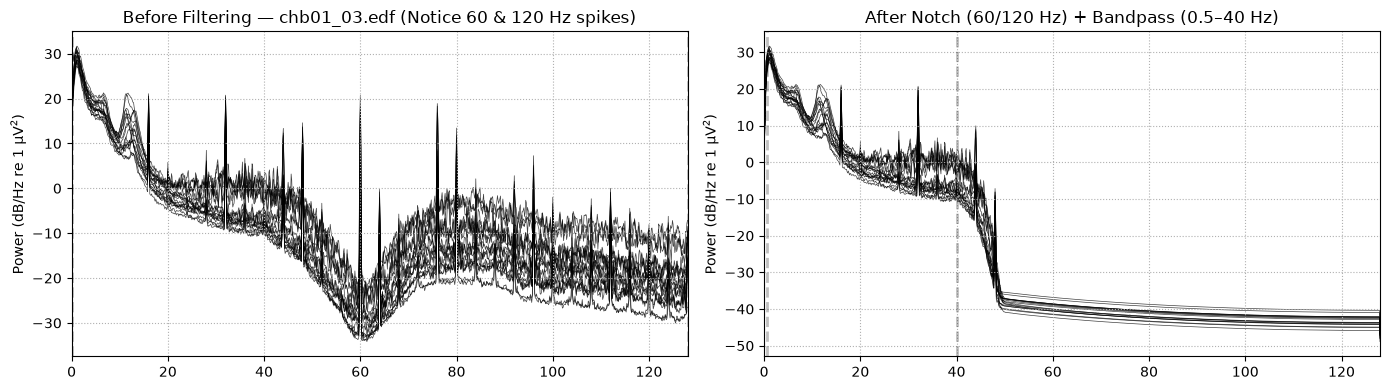

In [32]:
# --- Visual Verification: PSD Before vs. After Filtering on 1 Seizure Recording ---
sample_row = valid_files_df[valid_files_df["n_seizures"] > 0].iloc[0]
sample_path = RAW_DATA_DIR / sample_row["rel_path"]
sample_chs = sample_row["matched_channels"].split("|")

raw_before = mne.io.read_raw_edf(sample_path, preload=True, verbose="ERROR")
raw_before.pick(sample_chs).reorder_channels(sample_chs)

sample_data_uv, raw_after = load_and_filter_edf(sample_path, sample_chs, return_raw=True)

print(f"Sample file : {sample_row['rel_path']}")
print(f"Signal shape: {sample_data_uv.shape} | dtype: {sample_data_uv.dtype}")
print(f"Channel order verified: {len(raw_after.ch_names)} channels | first={raw_after.ch_names[0]}, last={raw_after.ch_names[-1]}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
raw_before.compute_psd(fmax=128.0, verbose="ERROR").plot(axes=axes[0], show=False)
axes[0].set_title(f"Before Filtering — {sample_row['filename']} (Notice 60 & 120 Hz spikes)")

raw_after.compute_psd(fmax=128.0, verbose="ERROR").plot(axes=axes[1], show=False)
axes[1].set_title(f"After Notch (60/120 Hz) + Bandpass (0.5–40 Hz)")
plt.tight_layout()
plt.show()

### 3.2. Windowing (Epoching) & Imbalance Strategy

- **Window length:** `4 seconds` ($4 	imes 256 = 1024$ samples).
- **Training set windowing (asymmetric overlap & controlled subsampling):**
  - **Ictal (seizure) intervals:** Sliding step of `1 second` (**75% overlap**) to quadruple positive samples.
  - **Interictal (non-seizure) intervals:** Sliding step of `4 seconds` (`0% overlap`) + controlled subsampling of long background hours to reach a manageable ratio (e.g., `1:10` to `1:20`).
  - **Ambiguous boundaries:** Exclude boundary windows with partial seizure overlap (e.g., `10%–50%`) during training (and optionally a `1–2 min` pre/post-ictal buffer) to keep class boundaries sharp.
- **Validation & Test set windowing (strictly preserve real distribution):**
  - **Never subsample or alter class balance** — keep the true ~`1:300` ratio so `AUPRC` and `FAR/h` remain clinically realistic.
  - Use uniform sliding windows across the entire recording (`window = 4 s`, `step = 2 s` or `4 s`).
  - Label a window `1` if $\ge 50\%$ of its duration falls within `[start_sec, end_sec]`, else `0`.
  - **Mandatory temporal metadata per window:** `(subject_id, filename, window_start_sec, window_end_sec, label)` — required for Event-based evaluation in Step 8.

In [33]:
# TODO [3.2]: Implement window extraction and labeling functions
# 1. Write `extract_windows_from_file(data_18ch, fs, seizure_intervals, mode="eval", ...)`:
#    - Support `mode="train"` (1s step inside seizures, 4s step outside, drop ambiguous 10-50% boundary windows, optional background subsampling)
#    - Support `mode="eval"` (uniform 4s window with 2s or 4s step across the ENTIRE recording, no subsampling)
# 2. For every window, compute exact overlap with seizure_intervals to assign binary label (0 or 1)
# 3. Return:
#    - windows array of shape (N_windows, 18, 1024), dtype float32
#    - metadata DataFrame with columns: [subject_id, filename, window_start_sec, window_end_sec, label]
# 4. Sanity-check window counts and positive/negative ratio on one seizure file

In [34]:
# =========================================================
# Step 3.2: Windowing (Epoching) & Seizure Overlap Labeling
# =========================================================

EVAL_STEP_SEC = 4.0         # Uniform non-overlapping 4s grid for Val/Test (preserves true ~1:330 ratio)
TRAIN_ICTAL_STEP_SEC = 1.0  # 75% overlap (1s step) ONLY on ictal segments for training augmentation
SEIZURE_OVERLAP_THRESH = 0.50  # Window labeled 1 if >= 50% lies inside a seizure interval


def compute_overlap_ratio(
    w_start: float,
    w_end: float,
    seizure_intervals: list[tuple[float, float]],
) -> float:
    """Fraction of [w_start, w_end] that overlaps any ground-truth seizure interval."""
    if not seizure_intervals:
        return 0.0
    overlap_sec = sum(
        max(0.0, min(w_end, s_end) - max(w_start, s_start))
        for s_start, s_end in seizure_intervals
    )
    return float(overlap_sec / (w_end - w_start))

In [35]:
def extract_windows_from_file(
    data_18ch: np.ndarray,
    fs: int,
    subject_id: str,
    case_id: str,
    filename: str,
    rel_path: str,
    seizure_intervals: list[tuple[float, float]],
    window_sec: float = WINDOW_SEC,
    eval_step_sec: float = EVAL_STEP_SEC,
    train_ictal_step_sec: float = TRAIN_ICTAL_STEP_SEC,
    overlap_thresh: float = SEIZURE_OVERLAP_THRESH,
) -> tuple[np.ndarray, pd.DataFrame]:
    """
    Extract fixed-length windows from one filtered recording:
      1. Uniform `eval_grid` windows covering the entire file (`is_eval_grid=True`).
      2. Extra 1s-shifted ictal windows (`is_train_aug=True`) to boost positive samples in Train folds.
    """
    n_channels, n_times = data_18ch.shape
    win_samples = int(round(window_sec * fs))
    eval_step_samples = int(round(eval_step_sec * fs))

    windows_list = []
    meta_rows = []
    seen_start_samples = set()

    def add_window(start_sample: int, is_eval_grid: bool, is_train_aug: bool):
        end_sample = start_sample + win_samples
        if start_sample < 0 or end_sample > n_times:
            return
        w_start = start_sample / fs
        w_end = end_sample / fs
        ov_ratio = compute_overlap_ratio(w_start, w_end, seizure_intervals)
        label = int(ov_ratio >= overlap_thresh)
        is_ambiguous = (0.0 < ov_ratio < overlap_thresh)

        # For extra train-only ictal augmentation, keep strictly positive windows
        if is_train_aug and label != 1:
            return

        windows_list.append(data_18ch[:, start_sample:end_sample])
        meta_rows.append({
            "subject_id": subject_id,
            "case_id": case_id,
            "filename": filename,
            "rel_path": rel_path,
            "window_start_sec": round(w_start, 3),
            "window_end_sec": round(w_end, 3),
            "overlap_ratio": round(ov_ratio, 4),
            "label": label,
            "is_eval_grid": is_eval_grid,
            "is_train_aug": is_train_aug,
            "is_ambiguous_boundary": is_ambiguous,
        })
        seen_start_samples.add(start_sample)

    # 1. Uniform evaluation grid across the ENTIRE recording
    for s_idx in range(0, n_times - win_samples + 1, eval_step_samples):
        add_window(s_idx, is_eval_grid=True, is_train_aug=False)

    # 2. High-overlap (1s step) ictal augmentation windows around seizures
    if seizure_intervals and train_ictal_step_sec < eval_step_sec:
        aug_step_samples = int(round(train_ictal_step_sec * fs))
        for s_start, s_end in seizure_intervals:
            scan_start = max(0, int((s_start - window_sec) * fs))
            scan_end = min(n_times - win_samples, int(s_end * fs))
            # Align to 1-second boundaries
            scan_start = (scan_start // aug_step_samples) * aug_step_samples
            for s_idx in range(scan_start, scan_end + 1, aug_step_samples):
                if s_idx not in seen_start_samples:
                    add_window(s_idx, is_eval_grid=False, is_train_aug=True)

    windows_arr = np.stack(windows_list, axis=0)  # Shape: (N_windows, 18, 1024)
    meta_df = pd.DataFrame(meta_rows)
    return windows_arr, meta_df

In [36]:
# --- Sanity check on the sample seizure file from Step 3.1 ---
sample_seiz_intervals = list(
    seizures_manifest_df.loc[
        seizures_manifest_df["rel_path"] == sample_row["rel_path"], ["start_sec", "end_sec"]
    ].itertuples(index=False, name=None)
)

test_wins, test_meta = extract_windows_from_file(
    sample_data_uv, FS,
    sample_row["subject_id"], sample_row["case_id"],
    sample_row["filename"], sample_row["rel_path"],
    sample_seiz_intervals,
)

eval_meta = test_meta[test_meta["is_eval_grid"]]
print(f"File: {sample_row['filename']} | Seizures: {sample_seiz_intervals}")
print(f"Eval-grid windows : {len(eval_meta)} (positive={eval_meta['label'].sum()}, ambiguous={eval_meta['is_ambiguous_boundary'].sum()})")
print(f"Extra train ictal : {test_meta['is_train_aug'].sum()} (total positives available for train={test_meta['label'].sum()})")
print(f"Output array shape: {test_wins.shape}")

File: chb01_03.edf | Seizures: [(2996, 3036)]
Eval-grid windows : 900 (positive=10, ambiguous=0)
Extra train ictal : 31 (total positives available for train=41)
Output array shape: (931, 18, 1024)


### 3.3. Leakage-Free Normalization

- Apply **per-channel Z-score normalization** (independently per channel) to reduce electrode impedance and amplitude variability across subjects.
- Ensure normalization statistics do not leak future/test information (e.g., per-window channel Z-score or causal/recording-level statistics applied consistently in train and test).
- Guard against division by zero on flat/disconnected channels (`std + 1e-8`).

In [37]:
# TODO [3.3]: Implement leakage-free channel-wise Z-score normalization
# 1. Write `normalize_windows(windows, eps=1e-8)` operating per channel along the time axis (axis=-1)
#    (Or implement per-recording channel normalization if preferred — document your choice clearly)
# 2. Handle flat/dead channels safely so no NaN or Inf values are produced
# 3. Assert `np.isfinite(windows_norm).all()` and verify mean ~ 0, std ~ 1 on active channels

In [38]:
# =========================================================
# Step 3.3: Leakage-Free Per-Recording Robust Normalization
# =========================================================

CLIP_ZSCORE = 20.0  # Suppress extreme non-physiological electrode-pop spikes


def robust_normalize_recording(
    data_18ch: np.ndarray,
    clip_val: float = CLIP_ZSCORE,
    eps: float = 1e-6,
) -> np.ndarray:
    """
    Apply per-channel robust Z-score normalization independently on a single EDF recording:
        z = (x - median) / (1.4826 * MAD)
    Preserves true seizure amplitude surges relative to the recording's background baseline
    while removing inter-patient impedance shifts and preventing cross-recording leakage.
    """
    # Compute median and MAD independently for each of the 18 channels
    medians = np.median(data_18ch, axis=1, keepdims=True)
    abs_dev = np.abs(data_18ch - medians)
    mads = np.median(abs_dev, axis=1, keepdims=True)
    scales = 1.4826 * mads

    # Fallback to std if MAD is ~0 (e.g., sparse/quantized channel); zero out completely flat channels
    flat_mad = scales < eps
    if np.any(flat_mad):
        stds = np.std(data_18ch, axis=1, keepdims=True)
        scales = np.where(flat_mad, stds, scales)

    dead_ch = scales < eps
    safe_scales = np.where(dead_ch, 1.0, scales)

    normed = (data_18ch - medians) / safe_scales
    normed = np.where(dead_ch, 0.0, normed)

    if clip_val is not None:
        normed = np.clip(normed, -clip_val, clip_val)

    return normed.astype(np.float32)

In [39]:
# --- Verify normalization on the sample seizure file ---
sample_norm = robust_normalize_recording(sample_data_uv)
assert np.isfinite(sample_norm).all(), "NaN or Inf found after normalization!"

# Check that background median ~ 0, robust scale ~ 1, while seizure retains higher amplitude!
s_start, s_end = sample_seiz_intervals[0]
bg_std = np.std(sample_norm[:, : int(min(600, s_start) * FS)])
seiz_std = np.std(sample_norm[:, int(s_start * FS) : int(s_end * FS)])

print(f"Finite check passed | min={sample_norm.min():.2f}, max={sample_norm.max():.2f}")
print(f"Background std : {bg_std:.3f} | Seizure std : {seiz_std:.3f} (Amplitude surge preserved: {seiz_std / bg_std:.2f}x)")

Finite check passed | min=-20.00, max=18.44
Background std : 1.177 | Seizure std : 3.041 (Amplitude surge preserved: 2.58x)


### 3.4. Efficient Disk Storage (`HDF5`)

- Save preprocessed signal windows as compact **`HDF5 (.h5)`** (or `numpy memmap`) tensors of shape `(N, 18, 1024)` in `float32`, paired with a `windows_metadata.parquet` (or `.csv`) file.
- **Avoid saving thousands of individual `.png` image files**, which creates severe filesystem and DataLoader I/O bottlenecks.

In [40]:
# TODO [3.4]: Build and save the preprocessed HDF5 dataset + window metadata table
# 1. Iterate over valid EDF files from `files_manifest.csv`
# 2. Run load_and_filter_edf -> extract_windows -> normalize_windows
# 3. Store raw preprocessed windows in `PROCESSED_DATA_DIR / "eeg_windows.h5"` (e.g., grouped by filename or as chunked datasets)
# 4. Save aligned window metadata to `PROCESSED_DATA_DIR / "windows_metadata.parquet"`
# 5. Verify disk size, read speed, and exact alignment between HDF5 indices and metadata rows

In [41]:
# =========================================================
# Step 3.4: Build & Save Preprocessed HDF5 Dataset + Metadata
# =========================================================
import time
import h5py
from tqdm.auto import tqdm

HDF5_PATH = PROCESSED_DATA_DIR / "eeg_windows.h5"
META_PATH = PROCESSED_DATA_DIR / "windows_metadata.csv"
STORAGE_DTYPE = np.float16  # Cuts disk footprint by 50% (~1.3 GB for chb01) with negligible precision loss

# Pre-group seizure intervals by rel_path for fast O(1) lookup
seizure_map: dict[str, list[tuple[float, float]]] = {}
if not seizures_manifest_df.empty:
    valid_seiz = seizures_manifest_df[seizures_manifest_df["is_valid"]]
    for rel_path, grp in valid_seiz.groupby("rel_path"):
        seizure_map[rel_path] = list(grp[["start_sec", "end_sec"]].itertuples(index=False, name=None))
PROCESSED_DATA_DIR
t0 = time.perf_counter()
win_samples = int(round(WINDOW_SEC * FS))
all_meta_dfs = []
total_written = 0

with h5py.File(HDF5_PATH, "w") as h5f:
    # Create an expandable, chunked dataset: (N_windows, 18, 1024)
    dset = h5f.create_dataset(
        "windows",
        shape=(0, len(STANDARD_18_CHANNELS), win_samples),
        maxshape=(None, len(STANDARD_18_CHANNELS), win_samples),
        chunks=(64, len(STANDARD_18_CHANNELS), win_samples),
        dtype=STORAGE_DTYPE,
    )
    # Store dataset-level attributes for full self-documentation
    h5f.attrs["fs"] = FS
    h5f.attrs["window_sec"] = WINDOW_SEC
    h5f.attrs["channels"] = "|".join(STANDARD_18_CHANNELS)
    h5f.attrs["normalization"] = "per_recording_robust_zscore_clipped_20"

    for row in tqdm(valid_files_df.itertuples(index=False), total=len(valid_files_df), desc="Building HDF5"):
        edf_path = RAW_DATA_DIR / row.rel_path
        matched_chs = row.matched_channels.split("|")
        seiz_intervals = seizure_map.get(row.rel_path, [])

        # 1. Load & filter (60/120 Hz notch + 0.5-40 Hz bandpass)
        data_uv = load_and_filter_edf(edf_path, matched_chs)

        # 2. Leakage-free per-recording robust Z-score normalization
        data_norm = robust_normalize_recording(data_uv)

        # 3. Extract eval-grid + train-aug windows
        win_arr, meta_df = extract_windows_from_file(
            data_norm, FS,
            row.subject_id, row.case_id, row.filename, row.rel_path,
            seiz_intervals,
        )

        # 4. Append directly to HDF5 & assign exact global `h5_idx`
        n_new = len(win_arr)
        dset.resize(total_written + n_new, axis=0)
        dset[total_written : total_written + n_new] = win_arr.astype(STORAGE_DTYPE)

        meta_df.insert(0, "h5_idx", np.arange(total_written, total_written + n_new, dtype=np.int64))
        all_meta_dfs.append(meta_df)
        total_written += n_new

windows_meta_df = pd.concat(all_meta_dfs, ignore_index=True)
windows_meta_df.to_csv(META_PATH, index=False)

elapsed = time.perf_counter() - t0
file_size_mb = HDF5_PATH.stat().st_size / (1024 ** 2)

Building HDF5:   0%|          | 0/42 [00:00<?, ?it/s]

In [42]:
# --- Final Verification ---
with h5py.File(HDF5_PATH, "r") as h5f:
    h5_shape = h5f["windows"].shape
    sample_check = h5f["windows"][0].astype(np.float32)

assert h5_shape[0] == len(windows_meta_df), "Row count mismatch between HDF5 and metadata!"
assert np.isfinite(sample_check).all(), "Non-finite values found in HDF5!"

eval_only = windows_meta_df[windows_meta_df["is_eval_grid"]]
print("-" * 60)
print(f"Finished in {elapsed:.1f}s | HDF5 size: {file_size_mb:.1f} MB")
print(f"HDF5 tensor shape        : {h5_shape} (dtype={STORAGE_DTYPE.__name__})")
print(f"Total stored windows     : {len(windows_meta_df):,}")
print(f"  - Eval-grid windows    : {len(eval_only):,} (positives={eval_only['label'].sum():,})")
print(f"  - Extra train ictal    : {int(windows_meta_df['is_train_aug'].sum()):,}")
print(f"Saved metadata to        : {META_PATH}")
print("-" * 60)
display(windows_meta_df.head(5))

------------------------------------------------------------
Finished in 47.1s | HDF5 size: 1296.0 MB
HDF5 tensor shape        : (36833, 18, 1024) (dtype=float16)
Total stored windows     : 36,833
  - Eval-grid windows    : 36,496 (positives=112)
  - Extra train ictal    : 337
Saved metadata to        : /media/zahraamini/OS1/PC/Zahraamini_ai/GitHub/eeg-seizure-detection/data/processed/windows_metadata.csv
------------------------------------------------------------


,h5_idx,subject_id,case_id,filename,rel_path,window_start_sec,window_end_sec,overlap_ratio,label,is_eval_grid,is_train_aug,is_ambiguous_boundary
0,0,chb01,chb01,chb01_01.edf,chb01/chb01_01.edf,0.0,4.0,0.0,0,True,False,False
1,1,chb01,chb01,chb01_01.edf,chb01/chb01_01.edf,4.0,8.0,0.0,0,True,False,False
2,2,chb01,chb01,chb01_01.edf,chb01/chb01_01.edf,8.0,12.0,0.0,0,True,False,False
3,3,chb01,chb01,chb01_01.edf,chb01/chb01_01.edf,12.0,16.0,0.0,0,True,False,False
4,4,chb01,chb01,chb01_01.edf,chb01/chb01_01.edf,16.0,20.0,0.0,0,True,False,False


---
## Step 4: Classical Baseline — Band Power Features + `XGBoost`

Establish a strong, fast, tabular baseline on the exact same patient splits (`splits.csv`). Any deep learning model built later must beat this floor to justify its complexity.

### 4.1. Extract Frequency-Domain & Time-Domain Features (18 Channels)

For each 4-second window `(18, 1024)`:
- Compute Power Spectral Density (PSD) per channel using `scipy.signal.welch` (`nperseg=256`, `noverlap=128`, `window='hann'`).
- Integrate PSD across the **5 standard EEG frequency bands** to obtain both **Absolute Power** and **Relative Power** (band power / total power in `0.5–40 Hz`):
  - `Delta (0.5–4 Hz)`, `Theta (4–8 Hz)`, `Alpha (8–13 Hz)`, `Beta (13–30 Hz)`, `Low Gamma (30–40 Hz)` $
ightarrow 18 	imes 10 = 180$ features.
- Add **2 high-signal time-domain features** per channel:
  - **Line Length** ($\sum |x_t - x_{t-1}|$) — one of the strongest classical seizure biomarkers.
  - **Standard Deviation / RMS** $
ightarrow +36$ features (**216 features total**).
- Check for and handle any `NaN` or `Inf` values (e.g., flat channels).

In [43]:
# TODO [4.1]: Implement `extract_band_power_features(windows, fs=256)`
# 1. Define BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}
# 2. Compute Welch PSD across all 18 channels (`scipy.signal.welch`)
# 3. Integrate PSD per band using `np.trapezoid` (or `scipy.integrate.simpson`) for Absolute & Relative Power
# 4. Compute Line Length (`np.sum(np.abs(np.diff(window, axis=-1)), axis=-1)`) and Std/RMS per channel
# 5. Assemble a feature matrix of shape (N_windows, 216) with descriptive column names (e.g., `FP1-F7_theta_rel`)
# 6. Assert zero NaN/Inf values and cache features to `PROCESSED_DATA_DIR / "xgb_features.parquet"`

In [44]:
# =========================================================
# Step 4.1: Vectorized Band Power + Time-Domain Feature Extraction
# =========================================================
import json
import time
import h5py
from scipy import signal
from tqdm.auto import tqdm

HDF5_PATH = PROCESSED_DATA_DIR / "eeg_windows.h5"
META_PATH = PROCESSED_DATA_DIR / "windows_metadata.csv"
XGB_FEAT_PATH = PROCESSED_DATA_DIR / "xgb_features.npy"
XGB_FEAT_NAMES_PATH = PROCESSED_DATA_DIR / "xgb_feature_names.json"

# Standard clinical EEG frequency bands (Hz)
EEG_BANDS = [
    ("delta", 0.5, 4.0),
    ("theta", 4.0, 8.0),
    ("alpha", 8.0, 13.0),
    ("beta",  13.0, 30.0),
    ("gamma", 30.0, 40.0),
]

# Compatible with both NumPy 1.x (trapz) and NumPy 2.x (trapezoid)
# _trapz = getattr(np, "trapezoid", np.trapz)
_trapz = getattr(np, "trapezoid", None) or np.trapz


def build_feature_names(channels: list[str] = STANDARD_18_CHANNELS) -> list[str]:
    """Generate ordered feature names matching the (N, 18, 12) -> (N, 216) reshape."""
    feat_types = (
        [f"{b}_log_abs" for b, _, _ in EEG_BANDS]
        + [f"{b}_rel" for b, _, _ in EEG_BANDS]
        + ["line_length", "std"]
    )
    return [f"{ch}__{ft}" for ch in channels for ft in feat_types]


def extract_features_batch(batch_windows: np.ndarray, fs: int = FS) -> np.ndarray:
    """
    Vectorized feature extraction on a batch of windows with shape (B, 18, 1024).
    Returns float32 matrix of shape (B, 216).
    """
    x = batch_windows.astype(np.float32, copy=False)
    B, C, T = x.shape

    # 1. Welch PSD across all windows & channels simultaneously
    # nperseg=256 (1.0s) -> 1 Hz frequency resolution, 50% overlap (7 Welch segments per 4s window)
    freqs, psd = signal.welch(
        x, fs=fs, window="hann", nperseg=256, noverlap=128, axis=-1
    )

    total_mask = (freqs >= 0.5) & (freqs <= 40.0)
    total_power = _trapz(psd[:, :, total_mask], freqs[total_mask], axis=-1)  # (B, C)

    log_abs_list = []
    rel_list = []
    for idx, (_, f_lo, f_hi) in enumerate(EEG_BANDS):
        if idx < len(EEG_BANDS) - 1:
            mask = (freqs >= f_lo) & (freqs < f_hi)
        else:
            mask = (freqs >= f_lo) & (freqs <= f_hi)
        band_power = _trapz(psd[:, :, mask], freqs[mask], axis=-1)           # (B, C)
        log_abs_list.append(np.log10(band_power + 1e-12))
        rel_list.append(band_power / (total_power + 1e-12))

    # 2. High-signal time-domain features
    line_length = np.mean(np.abs(np.diff(x, axis=-1)), axis=-1)              # (B, C)
    std_val = np.std(x, axis=-1)                                             # (B, C)

    # Stack along feature axis -> (B, C, 12), then flatten channel-major -> (B, C*12)
    feats_3d = np.stack(log_abs_list + rel_list + [line_length, std_val], axis=-1)
    return feats_3d.reshape(B, -1).astype(np.float32)


# --- Execute Step 4.1 in streaming chunks ---
t0 = time.perf_counter()
feature_names = build_feature_names(STANDARD_18_CHANNELS)
BATCH_SIZE = 1024

with h5py.File(HDF5_PATH, "r") as h5f:
    dset = h5f["windows"]
    n_total = dset.shape[0]
    X_features = np.empty((n_total, len(feature_names)), dtype=np.float32)

    for start in tqdm(range(0, n_total, BATCH_SIZE), desc="Extracting Band Power features"):
        end = min(start + BATCH_SIZE, n_total)
        X_features[start:end] = extract_features_batch(dset[start:end], fs=FS)

assert np.isfinite(X_features).all(), "NaN or Inf detected in extracted features!"

np.save(XGB_FEAT_PATH, X_features)
with open(XGB_FEAT_NAMES_PATH, "w", encoding="utf-8") as f:
    json.dump(feature_names, f, indent=2)

elapsed = time.perf_counter() - t0
print(f"Done in {elapsed:.1f}s | Feature matrix shape: {X_features.shape} ({X_features.nbytes / 1e6:.1f} MB)")
print(f"Saved features to: {XGB_FEAT_PATH}")
print(f"Sample feature names: {feature_names[:6]} ... {feature_names[-2:]}")

Extracting Band Power features:   0%|          | 0/36 [00:00<?, ?it/s]

Done in 22.8s | Feature matrix shape: (36833, 216) (31.8 MB)
Saved features to: /media/zahraamini/OS1/PC/Zahraamini_ai/GitHub/eeg-seizure-detection/data/processed/xgb_features.npy
Sample feature names: ['FP1-F7__delta_log_abs', 'FP1-F7__theta_log_abs', 'FP1-F7__alpha_log_abs', 'FP1-F7__beta_log_abs', 'FP1-F7__gamma_log_abs', 'FP1-F7__delta_rel'] ... ['CZ-PZ__line_length', 'CZ-PZ__std']


### 4.2. Train & Tune `XGBoost` on Locked Splits

- Train across the exact folds defined in `splits.csv`.
- Set `scale_pos_weight = n_neg / n_pos` computed strictly on each fold's training set.
- Optimize with `eval_metric="aucpr"` and Early Stopping monitored on the **patient-level Validation set**.
- Save out-of-fold validation and test probabilities to `oof_preds_xgb.parquet` for both window-based and event-based evaluation.

In [45]:
# TODO [4.2]: Train XGBoost across folds and log metrics
# 1. Loop over each fold in `splits.csv`:
#    - Slice X_train, y_train, X_val, y_val, X_test, y_test using `windows_metadata`
#    - Compute `scale_pos_weight = (y_train == 0).sum() / max(1, (y_train == 1).sum())`
#    - Initialize `xgb.XGBClassifier(..., eval_metric="aucpr", early_stopping_rounds=50, n_jobs=-1)`
#    - Fit on (X_train, y_train) with `eval_set=[(X_val, y_val)]`
#    - Predict probabilities (`predict_proba[:, 1]`) on val and test sets
# 2. Collect predictions alongside window metadata (`subject_id`, `filename`, `window_start_sec`, `window_end_sec`, `label`, `prob`)
# 3. Save to `PROCESSED_DATA_DIR / "oof_preds_xgb.parquet"`
# 4. Log fold AUROC / AUPRC (and optionally send to W&B / MLflow)

In [46]:
# =========================================================
# Step 4.2: Train XGBoost Baseline Across All Locked Folds
# =========================================================
import xgboost as xgb
from sklearn.metrics import roc_auc_score, average_precision_score

# Load locked metadata, splits, and extracted features
windows_meta_df = pd.read_csv(PROCESSED_DATA_DIR / "windows_metadata.csv")
splits_df = pd.read_csv(PROCESSED_DATA_DIR / "splits.csv")
X_features = np.load(PROCESSED_DATA_DIR / "xgb_features.npy")
with open(PROCESSED_DATA_DIR / "xgb_feature_names.json", "r", encoding="utf-8") as f:
    feature_names = json.load(f)

# Optional controlled negative subsampling in TRAIN ONLY (e.g., 30:1 keeps 23-patient runs fast; set None for all)
TRAIN_MAX_NEG_POS_RATIO = 30


def get_fold_window_indices(
    meta_df: pd.DataFrame,
    splits_df: pd.DataFrame,
    fold_idx: int,
    max_neg_pos_ratio: int | None = TRAIN_MAX_NEG_POS_RATIO,
    seed: int = SEED,
) -> dict[str, np.ndarray]:
    """
    Return exact `h5_idx` arrays for train, val, and test in `fold_idx`.
    - Train: includes `is_train_aug` positives, drops `is_ambiguous_boundary`, optional neg subsampling.
    - Val & Test: strictly `is_eval_grid == True` ONLY (preserves true ~1:330 clinical distribution).
    """
    fold_role_map = (
        splits_df.loc[splits_df["fold"] == fold_idx]
        .set_index("rel_path")["role"]
        .to_dict()
    )
    roles = meta_df["rel_path"].map(fold_role_map)

    # --- Train indices ---
    train_mask = (roles == "train") & (~meta_df["is_ambiguous_boundary"])
    train_df = meta_df.loc[train_mask]
    pos_idx = train_df.loc[train_df["label"] == 1, "h5_idx"].values
    neg_idx = train_df.loc[train_df["label"] == 0, "h5_idx"].values

    if max_neg_pos_ratio is not None and len(neg_idx) > len(pos_idx) * max_neg_pos_ratio:
        rng = np.random.default_rng(seed + fold_idx)
        neg_idx = rng.choice(neg_idx, size=len(pos_idx) * max_neg_pos_ratio, replace=False)

    train_idx = np.sort(np.concatenate([pos_idx, neg_idx]))

    # --- Val & Test indices (strictly uniform eval grid, ZERO augmentation or subsampling) ---
    val_idx = meta_df.loc[(roles == "val") & (meta_df["is_eval_grid"]), "h5_idx"].values
    test_idx = meta_df.loc[(roles == "test") & (meta_df["is_eval_grid"]), "h5_idx"].values

    return {"train": train_idx, "val": val_idx, "test": test_idx}


# --- Run XGBoost across all folds ---
oof_records = []
fold_metrics = []
xgb_models = {}

for fold_idx in sorted(splits_df["fold"].unique()):
    idxs = get_fold_window_indices(windows_meta_df, splits_df, fold_idx)
    tr_idx, va_idx, te_idx = idxs["train"], idxs["val"], idxs["test"]

    X_tr, y_tr = X_features[tr_idx], windows_meta_df.loc[tr_idx, "label"].values
    X_va, y_va = X_features[va_idx], windows_meta_df.loc[va_idx, "label"].values
    X_te, y_te = X_features[te_idx], windows_meta_df.loc[te_idx, "label"].values

    scale_pos_weight = float((y_tr == 0).sum() / max(1, (y_tr == 1).sum()))

    model = xgb.XGBClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.7,
        min_child_weight=5,
        reg_lambda=2.0,
        scale_pos_weight=scale_pos_weight,
        tree_method="hist",
        eval_metric="aucpr",
        early_stopping_rounds=50,
        random_state=SEED + fold_idx,
        n_jobs=-1,
    )

    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        verbose=False,
    )
    xgb_models[fold_idx] = model

    val_probs = model.predict_proba(X_va)[:, 1]
    test_probs = model.predict_proba(X_te)[:, 1]

    val_auroc = roc_auc_score(y_va, val_probs)
    val_auprc = average_precision_score(y_va, val_probs)
    test_auroc = roc_auc_score(y_te, test_probs)
    test_auprc = average_precision_score(y_te, test_probs)

    fold_metrics.append({
        "fold": fold_idx,
        "best_iter": int(model.best_iteration),
        "train_pos": int(y_tr.sum()),
        "train_neg": int((y_tr == 0).sum()),
        "val_auroc": round(val_auroc, 4),
        "val_auprc": round(val_auprc, 4),
        "test_auroc": round(test_auroc, 4),
        "test_auprc": round(test_auprc, 4),
    })

    # Store OOF predictions for BOTH val (for threshold/post-proc tuning) and test (for final eval)
    meta_cols = ["h5_idx", "subject_id", "case_id", "filename", "rel_path", "window_start_sec", "window_end_sec", "label"]
    for role_name, r_idx, r_probs in [("val", va_idx, val_probs), ("test", te_idx, test_probs)]:
        part = windows_meta_df.loc[r_idx, meta_cols].copy()
        part.insert(0, "role", role_name)
        part.insert(0, "fold", fold_idx)
        part["prob"] = r_probs.astype(np.float32)
        oof_records.append(part)

oof_xgb_df = pd.concat(oof_records, ignore_index=True)
OOF_XGB_PATH = PROCESSED_DATA_DIR / "oof_preds_xgb.csv"
oof_xgb_df.to_csv(OOF_XGB_PATH, index=False)

fold_metrics_df = pd.DataFrame(fold_metrics)
display(fold_metrics_df)

# Pooled test metrics across all folds (every eval-grid window appears in test exactly once)
test_oof = oof_xgb_df[oof_xgb_df["role"] == "test"]
print("-" * 60)
print(f"Saved OOF predictions to : {OOF_XGB_PATH} ({len(oof_xgb_df):,} rows)")
print(f"Pooled Test AUROC (XGB)  : {roc_auc_score(test_oof['label'], test_oof['prob']):.4f}")
print(f"Pooled Test AUPRC (XGB)  : {average_precision_score(test_oof['label'], test_oof['prob']):.4f}")
print("-" * 60)



,fold,best_iter,train_pos,train_neg,val_auroc,val_auprc,test_auroc,test_auprc
0,0,17,286,8580,1.0000,0.9922,0.9972,0.4524
1,1,24,204,6120,0.9985,0.9403,0.9966,0.7300
2,2,10,160,4800,0.9039,0.5435,0.9973,0.8233


------------------------------------------------------------
Saved OOF predictions to : /media/zahraamini/OS1/PC/Zahraamini_ai/GitHub/eeg-seizure-detection/data/processed/oof_preds_xgb.csv (53,942 rows)
Pooled Test AUROC (XGB)  : 0.9716
Pooled Test AUPRC (XGB)  : 0.6470
------------------------------------------------------------


### 4.3. Baseline Sanity Check & Feature Importance

- Inspect top-20 feature importances (`gain`) to confirm the model relies on physiologically meaningful seizure cues (e.g., Line Length, Theta/Delta/Beta shifts) rather than artifacts.

In [47]:
# TODO [4.3]: Plot top-20 XGBoost feature importances (by gain) and summarize baseline window metrics
# 1. Extract feature importance scores from the trained XGBoost model(s)
# 2. Plot a clean horizontal bar chart of the top 20 features
# 3. Print quick validation & test AUROC and AUPRC to establish the baseline floor

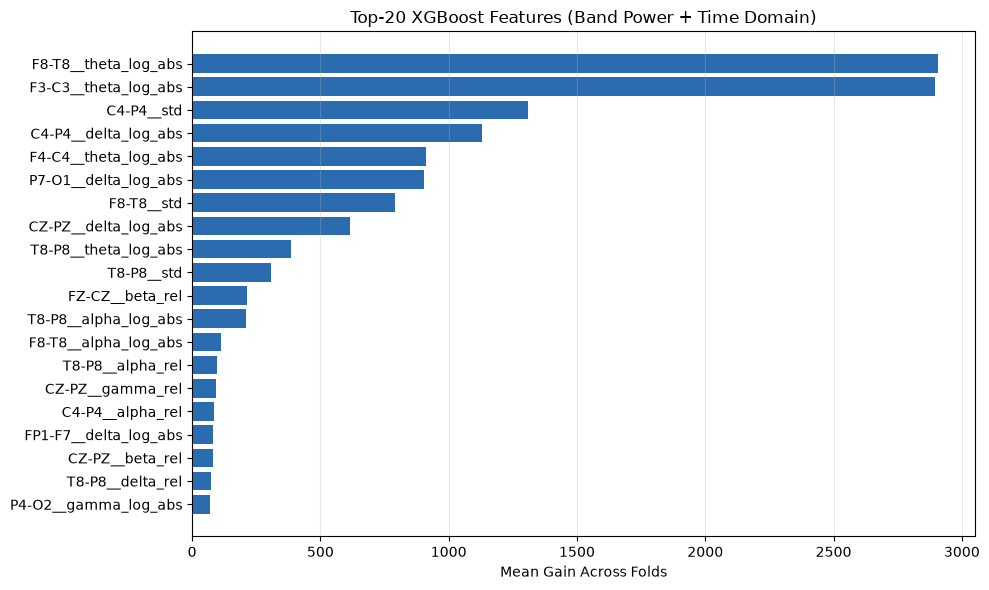

,feat_type,mean_gain
10,theta_log_abs,7253.002425
4,delta_log_abs,2906.389894
9,std,2588.980844
1,alpha_rel,517.570302
0,alpha_log_abs,466.234751
3,beta_rel,432.988522
7,gamma_rel,386.982534
6,gamma_log_abs,348.078995
11,theta_rel,194.019579
2,beta_log_abs,191.625848


In [48]:
# =========================================================
# Step 4.3: Feature Importance (Gain) & Baseline Sanity Check
# =========================================================

gain_accum = np.zeros(len(feature_names), dtype=np.float64)

for fold_idx, model in xgb_models.items():
    score_dict = model.get_booster().get_score(importance_type="gain")
    for k, v in score_dict.items():
        feat_idx = int(k[1:])  # XGBoost names numpy columns as "f0", "f1", ...
        gain_accum[feat_idx] += v

gain_mean = gain_accum / len(xgb_models)
imp_df = (
    pd.DataFrame({"feature": feature_names, "mean_gain": gain_mean})
    .sort_values("mean_gain", ascending=False)
    .reset_index(drop=True)
)

top_k = 20
top_imp = imp_df.head(top_k).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_imp["feature"], top_imp["mean_gain"], color="#2b6cb0")
ax.set_xlabel("Mean Gain Across Folds")
ax.set_title(f"Top-{top_k} XGBoost Features (Band Power + Time Domain)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Breakdown by feature type (which frequency band / time feature contributes most?)
imp_df["feat_type"] = imp_df["feature"].str.split("__").str[1]
type_summary = (
    imp_df.groupby("feat_type", as_index=False)["mean_gain"]
    .sum()
    .sort_values("mean_gain", ascending=False)
)
display(type_summary)


---
## Step 5: Signal-to-Image Transformation (`STFT` Spectrograms & `CWT` Scalograms)

Convert each preprocessed EEG window `(18, 1024)` into a multi-channel 2D time-frequency tensor `(18, H, W)` suitable for 2D CNNs.

### 5.1. Practical `STFT` Spectrograms (`scipy.signal.stft`)

- **Core parameters (`fs = 256 Hz`):**
  - Window function: `window="hann"` (minimizes spectral leakage).
  - Segment length: `nperseg=128` (`0.5 s` window $
ightarrow$ `2 Hz` frequency resolution, strong temporal resolution). Optionally compare with `nperseg=256` (`1.0 s` $
ightarrow$ `1 Hz` resolution).
  - Overlap: `noverlap=96` (`75%` overlap for smooth temporal continuity).
- Crop frequency axis to **`[0.5, 40.0] Hz`**.
- Apply log power compression (dB scale): $S_{	ext{dB}} = 10 \log_{10}(|Z|^2 + 10^{-10})$.
- Resize to a uniform spatial shape (e.g., `64x64` or `128x128`) using bilinear interpolation.

In [49]:
# TODO [5.1]: Implement `compute_stft_tensor(window_18ch, fs=256, out_size=(64, 64))`
# 1. Run `scipy.signal.stft(window_18ch, fs=fs, window="hann", nperseg=128, noverlap=96, axis=-1)`
# 2. Filter frequency bins to `0.5 <= freqs <= 40.0`
# 3. Compute log-power spectrum: `10.0 * np.log10(np.abs(Zxx)**2 + 1e-10)`
# 4. Resize the (18, F, T) array to `(18, 64, 64)` (e.g., via `torch.nn.functional.interpolate`)
# 5. Benchmark execution time per window and verify output shape and finite values

In [50]:
# =========================================================
# Step 5.1: Practical STFT Spectrograms (scipy.signal.stft)
# =========================================================
import time
import h5py
import torch
import torch.nn.functional as F
from scipy import signal

HDF5_PATH = PROCESSED_DATA_DIR / "eeg_windows.h5"
IMG_SIZE = (64, 64)  # Unified (H=freq, W=time) target size for STFT, CWT, and Fusion

# STFT config: 1.0s window -> 1 Hz freq resolution (critical for Delta/Theta), 87.5% overlap -> 33 time frames
STFT_NPERSEG = 256
STFT_NOVERLAP = 224
STFT_FMIN, STFT_FMAX = 0.5, 40.0


def compute_stft_tensor(
    window_18ch: np.ndarray,
    fs: int = FS,
    nperseg: int = STFT_NPERSEG,
    noverlap: int = STFT_NOVERLAP,
    fmin: float = STFT_FMIN,
    fmax: float = STFT_FMAX,
    out_size: tuple[int, int] = IMG_SIZE,
) -> np.ndarray:
    """
    Convert a preprocessed EEG window of shape (18, 1024) into an STFT log-power
    image tensor of shape (18, H, W), dtype float32.
    Frequency axis: index 0 = low freq (~1 Hz) -> index -1 = high freq (40 Hz).
    """
    x = window_18ch.astype(np.float32, copy=False)

    freqs, _, Zxx = signal.stft(
        x,
        fs=fs,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        axis=-1,
    )
    freq_mask = (freqs >= fmin) & (freqs <= fmax)
    power = np.abs(Zxx[:, freq_mask, :]) ** 2
    spec_db = 10.0 * np.log10(power + 1e-10)  # Shape: (18, 40, 33)

    # Bilinear resize to (18, 64, 64)
    t = torch.from_numpy(spec_db).unsqueeze(0)  # (1, 18, F, T)
    t_resized = F.interpolate(t, size=out_size, mode="bilinear", align_corners=False)
    return t_resized.squeeze(0).numpy().astype(np.float32)


# --- Benchmark & Sanity Check on 50 windows ---
with h5py.File(HDF5_PATH, "r") as h5f:
    sample_batch = h5f["windows"][:50].astype(np.float32)

t0 = time.perf_counter()
stft_samples = [compute_stft_tensor(w) for w in sample_batch]
ms_per_win = (time.perf_counter() - t0) / len(sample_batch) * 1000.0

stft_ex = stft_samples[0]
assert stft_ex.shape == (len(STANDARD_18_CHANNELS), *IMG_SIZE), f"Bad STFT shape: {stft_ex.shape}"
assert np.isfinite(stft_ex).all(), "Non-finite values in STFT!"

print(f"STFT shape      : {stft_ex.shape} | dtype: {stft_ex.dtype}")
print(f"Value range (dB): min={stft_ex.min():.2f}, max={stft_ex.max():.2f}, mean={stft_ex.mean():.2f}")
print(f"Speed (CPU)     : {ms_per_win:.2f} ms / window (~{1000.0 / ms_per_win:.0f} windows/sec)")

STFT shape      : (18, 64, 64) | dtype: float32
Value range (dB): min=-70.85, max=13.40, mean=-23.35
Speed (CPU)     : 3.16 ms / window (~316 windows/sec)


### 5.2. Practical `CWT` Scalograms (`PyWavelets`)

- **Mother wavelet:** Complex Morlet (`cmor1.5-1.0`) — gold standard for oscillatory EEG bursts because it captures both low-frequency rhythms (high frequency resolution) and fast spikes (high time resolution).
- **Log-spaced frequency grid:** `np.geomspace(0.5, 40.0, num=64)` so Delta/Theta/Alpha bands receive generous pixel resolution.
- Convert frequencies to wavelet scales via `pywt.frequency2scale(wavelet, freqs / fs)` and run `pywt.cwt`.
- Apply magnitude + log compression: $\log(1 + |C|)$, then resize time axis to match STFT `(18, 64, 64)`.

In [51]:
# TODO [5.2]: Implement `compute_cwt_tensor(window_18ch, fs=256, n_freqs=64, out_size=(64, 64))`
# 1. Build log-spaced frequencies: `freqs = np.geomspace(0.5, 40.0, num=n_freqs)`
# 2. Compute scales: `scales = pywt.frequency2scale("cmor1.5-1.0", freqs / fs)`
# 3. Compute CWT across all 18 channels using `pywt.cwt`
# 4. Apply `np.log1p(np.abs(coefs))` and resize to `(18, 64, 64)`
# 5. Benchmark execution time per window and verify output shape and finite values

In [ ]:
# =========================================================
# Step 5.2: Practical CWT Scalograms (PyWavelets - Complex Morlet)
# =========================================================
import pywt

CWT_WAVELET = "cmor1.5-1.0"   # Bandwidth=1.5, Center Freq=1.0 (gold standard for oscillatory EEG)
CWT_N_FREQS = IMG_SIZE[0]     # 64 log-spaced frequencies directly matching H=64
CWT_FREQS = np.geomspace(STFT_FMIN, STFT_FMAX, num=CWT_N_FREQS)
CWT_SCALES = pywt.frequency2scale(CWT_WAVELET, CWT_FREQS / FS)


def compute_cwt_tensor(
    window_18ch: np.ndarray,
    fs: int = FS,
    scales: np.ndarray = CWT_SCALES,
    wavelet: str = CWT_WAVELET,
    out_size: tuple[int, int] = IMG_SIZE,
) -> np.ndarray:
    """
    Convert a preprocessed EEG window of shape (18, 1024) into a CWT scalogram
    image tensor of shape (18, H, W), dtype float32.
    Uses log-spaced frequencies (giving high pixel resolution to Delta/Theta) and
    area-based downsampling along time to prevent aliasing fast spikes.
    """
    x = window_18ch.astype(np.float32, copy=False)

    # method="fft" is much faster; output shape is (n_freqs, 18, 1024)
    coefs, _ = pywt.cwt(
        x,
        scales=scales,# ---------------------------------------------------------
# 2. Centralized Paths & Dataset Scope (ONLY place to edit!)
# ---------------------------------------------------------
def find_project_root(marker: str = "pyproject.toml") -> Path:
    """Walk upward from current working directory until repo root is found."""
    cwd = Path.cwd().resolve()
    for parent in [cwd, *cwd.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(
        f"Could not locate '{marker}' starting from {cwd}. Check repo root."
    )


def resolve_path(path_value: str | Path, root: Path) -> Path:
    """Resolve relative paths against PROJECT_ROOT (not notebook cwd)."""
    p = Path(path_value).expanduser()
    return p.resolve() if p.is_absolute() else (root / p).resolve()


def display_path(path: Path, root: Path) -> str:
    """Return relative path if inside repo, otherwise safe external label."""
    try:
        return str(path.relative_to(root))
    except ValueError:
        return f"<external>/{path.name}"


PROJECT_ROOT = find_project_root("pyproject.toml")
DATA_DIR = PROJECT_ROOT / "data"

# Defaults to <repo>/data/raw & <repo>/data/processed (supports Colab/Kaggle env override)
RAW_DATA_DIR = resolve_path(
    os.environ.get("EEG_RAW_DATA_DIR") or (DATA_DIR / "raw"),
    PROJECT_ROOT,
)
PROCESSED_DATA_DIR = resolve_path(
    os.environ.get("EEG_PROCESSED_DATA_DIR") or (DATA_DIR / "processed"),
    PROJECT_ROOT,
)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Set to ["chb01"] for single-patient dev, or None to process ALL available chb* folders
SELECTED_CASES = ["chb01"]

# Print clean paths (safe for GitHub outputs even when using external paths)
print(f"PROJECT_ROOT      : {PROJECT_ROOT.name}")
print(f"RAW_DATA_DIR      : {display_path(RAW_DATA_DIR, PROJECT_ROOT)} (exists={RAW_DATA_DIR.exists()})")
print(f"PROCESSED_DATA_DIR: {display_path(PROCESSED_DATA_DIR, PROJECT_ROOT)} (exists={PROCESSED_DATA_DIR.exists()})")
        wavelet=wavelet,
        sampling_period=1.0 / fs,
        method="fft",
        axis=-1,
    )

    # Magnitude + log compression, then transpose (F, C, T) -> (C, F, T)
    scalogram = np.log1p(np.abs(coefs)).transpose(1, 0, 2).astype(np.float32)

    # Area downsampling from (18, 64, 1024) -> (18, 64, 64) preserves local energy without aliasing
    t = torch.from_numpy(scalogram).unsqueeze(0)  # (1, 18, F, T)
    t_resized = F.interpolate(t, size=out_size, mode="area")
    return t_resized.squeeze(0).numpy().astype(np.float32)


# --- Benchmark & Sanity Check on 20 windows ---
t0 = time.perf_counter()
cwt_samples = [compute_cwt_tensor(w) for w in sample_batch[:20]]
ms_per_win_cwt = (time.perf_counter() - t0) / 20.0 * 1000.0

cwt_ex = cwt_samples[0]
assert cwt_ex.shape == (len(STANDARD_18_CHANNELS), *IMG_SIZE), f"Bad CWT shape: {cwt_ex.shape}"
assert np.isfinite(cwt_ex).all(), "Non-finite values in CWT!"

print(f"CWT shape       : {cwt_ex.shape} | dtype: {cwt_ex.dtype}")
print(f"Value range     : min={cwt_ex.min():.2f}, max={cwt_ex.max():.2f}, mean={cwt_ex.mean():.2f}")
print(f"Speed (CPU)     : {ms_per_win_cwt:.2f} ms / window (~{1000.0 / ms_per_win_cwt:.1f} windows/sec)")
print(f"CWT/STFT ratio  : CWT is ~{ms_per_win_cwt / ms_per_win:.1f}x slower than STFT")

CWT shape       : (18, 64, 64) | dtype: float32
Value range     : min=0.01, max=3.17, mean=0.91
Speed (CPU)     : 77.86 ms / window (~12.8 windows/sec)
CWT/STFT ratio  : CWT is ~24.6x slower than STFT


### 5.3. Compute Caching, Scale Alignment & Visual Verification

- **Compute strategy:** `STFT` is fast enough to compute on-the-fly in the PyTorch `Dataset` (or via `torchaudio` on GPU). `CWT` is CPU-heavy — precompute and cache `float16` CWT tensors once in `HDF5`.
- **Scale alignment:** Normalize STFT and CWT images independently (e.g., Z-score per image or using train-set stats) so neither representation dominates when concatenated in Ablation Exp C.
- **Visual QA:** Plot random Ictal vs. Interictal STFT and CWT images side-by-side to ensure axes are not flipped and frequency cropping is accurate.

In [53]:
# TODO [5.3]: Cache CWT tensors (if needed), implement normalization, and run visual QA
# 1. Implement a shared normalization function for STFT and CWT tensors (mean ~ 0, std ~ 1)
# 2. Optionally precompute and cache CWT tensors in `PROCESSED_DATA_DIR / "cwt_cache.h5"` (float16)
# 3. Plot a grid comparing random Interictal vs. Ictal samples (raw signal, STFT, and CWT) for the most active channel
# 4. Verify frequency axis orientation (low freq at bottom, high freq at top) and dynamic range

Fold 0 Train STFT stats -> mean=-27.711, std=10.535
Fold 0 Train CWT  stats -> mean=0.819,  std=0.607


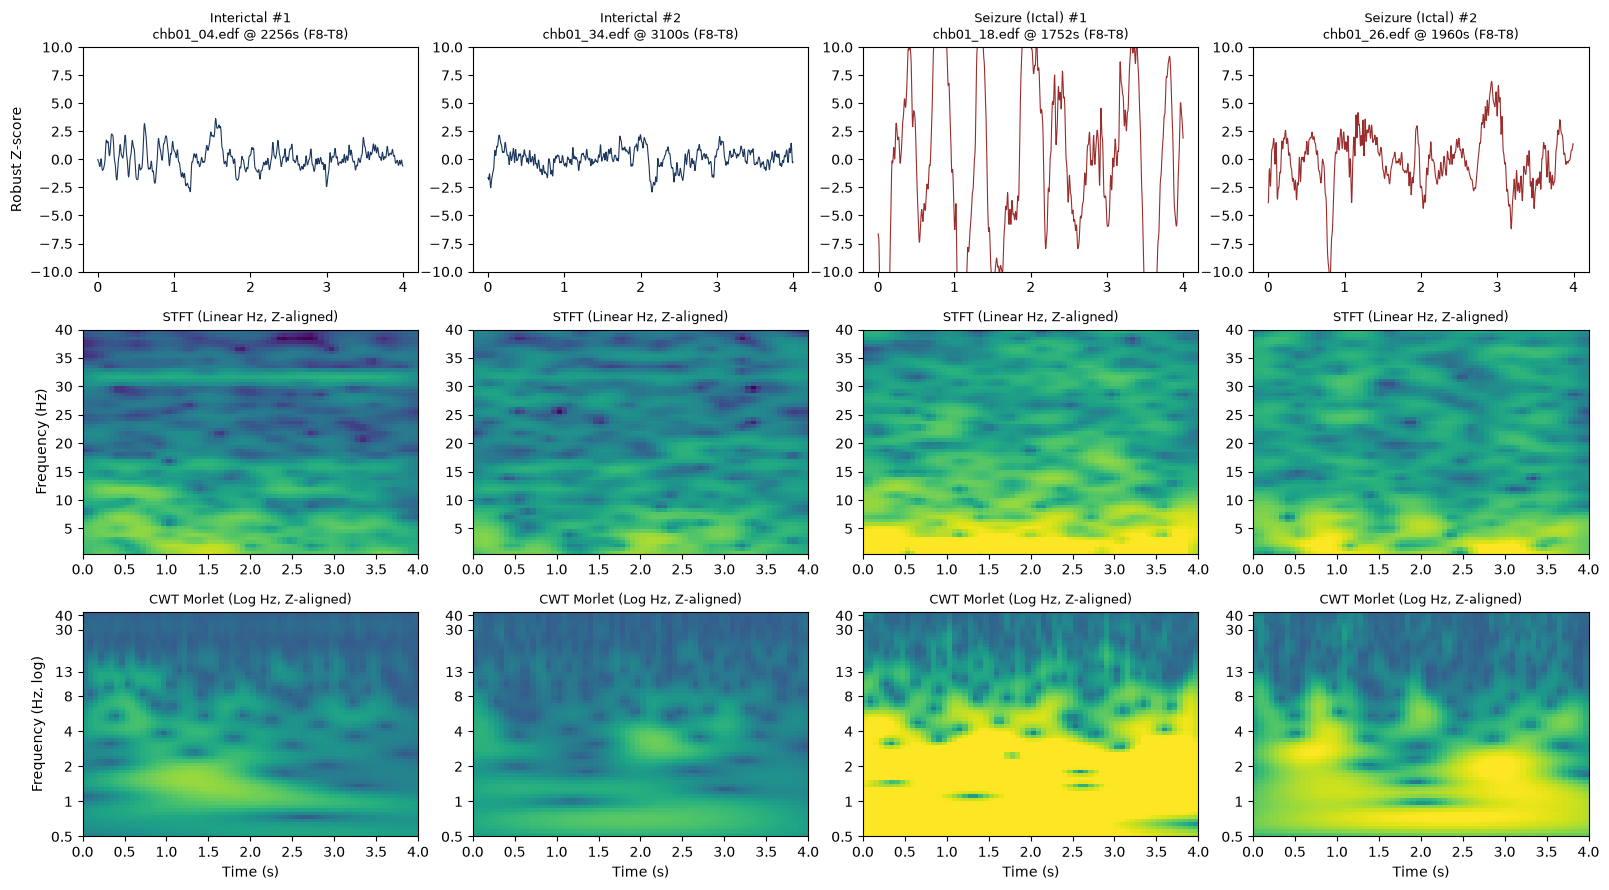

In [54]:
# =========================================================
# Step 5.3: Leakage-Free Scale Alignment & Visual QA (STFT vs CWT)
# =========================================================

windows_meta_df = pd.read_csv(PROCESSED_DATA_DIR / "windows_metadata.csv")
splits_df = pd.read_csv(PROCESSED_DATA_DIR / "splits.csv")


def estimate_tf_norm_stats(
    hdf5_path: Path,
    train_indices: np.ndarray,
    mode: str,
    n_samples: int = 400,
    seed: int = SEED,
) -> tuple[float, float]:
    """
    Estimate global (mean, std) STRICTLY on a subsample of training windows.
    Aligns STFT (dB) and CWT (log-mag) to N(0, 1) for Early Fusion WITHOUT
    destroying seizure-vs-background absolute power contrast.
    """
    rng = np.random.default_rng(seed)
    k = min(n_samples, len(train_indices))
    chosen = np.sort(rng.choice(train_indices, size=k, replace=False))

    fn = compute_stft_tensor if mode == "stft" else compute_cwt_tensor
    sum_val = 0.0
    sum_sq = 0.0
    total_elems = 0

    with h5py.File(hdf5_path, "r") as h5f:
        dset = h5f["windows"]
        for idx in chosen:
            img = fn(dset[int(idx)])
            sum_val += float(img.sum(dtype=np.float64))
            sum_sq += float(np.square(img, dtype=np.float64).sum())
            total_elems += img.size

    mean = sum_val / total_elems
    var = max(sum_sq / total_elems - mean ** 2, 1e-8)
    return float(mean), float(np.sqrt(var))


def standardize_tf(img: np.ndarray, mean: float, std: float) -> np.ndarray:
    """Apply fold-level global standardization to an STFT or CWT tensor."""
    return ((img - mean) / (std + 1e-8)).astype(np.float32)


# --- 1. Estimate Fold 0 Train Stats (Zero Leakage) ---
fold0_idxs = get_fold_window_indices(windows_meta_df, splits_df, fold_idx=0)
stft_mean, stft_std = estimate_tf_norm_stats(HDF5_PATH, fold0_idxs["train"], mode="stft", n_samples=300)
cwt_mean, cwt_std   = estimate_tf_norm_stats(HDF5_PATH, fold0_idxs["train"], mode="cwt",  n_samples=150)

print(f"Fold 0 Train STFT stats -> mean={stft_mean:.3f}, std={stft_std:.3f}")
print(f"Fold 0 Train CWT  stats -> mean={cwt_mean:.3f},  std={cwt_std:.3f}")

# --- 2. Visual QA: Compare 2 Interictal vs 2 Ictal windows on top XGBoost channel (F8-T8) ---
ch_name = "F8-T8"
ch_idx = STANDARD_18_CHANNELS.index(ch_name)

eval_df = windows_meta_df[windows_meta_df["is_eval_grid"]]
rng = np.random.default_rng(SEED)
neg_picks = rng.choice(eval_df.loc[eval_df["label"] == 0, "h5_idx"].values, size=2, replace=False)
pos_picks = rng.choice(eval_df.loc[eval_df["label"] == 1, "h5_idx"].values, size=2, replace=False)
qa_picks = [
    ("Interictal #1", int(neg_picks[0])),
    ("Interictal #2", int(neg_picks[1])),
    ("Seizure (Ictal) #1", int(pos_picks[0])),
    ("Seizure (Ictal) #2", int(pos_picks[1])),
]

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
t_axis = np.arange(int(WINDOW_SEC * FS)) / FS

with h5py.File(HDF5_PATH, "r") as h5f:
    for col, (title, h5_i) in enumerate(qa_picks):
        win = h5f["windows"][h5_i].astype(np.float32)
        stft_img = standardize_tf(compute_stft_tensor(win), stft_mean, stft_std)
        cwt_img  = standardize_tf(compute_cwt_tensor(win),  cwt_mean,  cwt_std)

        fname = windows_meta_df.loc[h5_i, "filename"]
        w_start = windows_meta_df.loc[h5_i, "window_start_sec"]

        # Row 0: Normalized time-domain signal
        axes[0, col].plot(t_axis, win[ch_idx], linewidth=0.8, color="#1a365d" if col < 2 else "#9b2c2c")
        axes[0, col].set_title(f"{title}\n{fname} @ {w_start:.0f}s ({ch_name})", fontsize=9)
        axes[0, col].set_ylim(-10, 10)
        if col == 0:
            axes[0, col].set_ylabel("Robust Z-score")

        # Row 1: Standardized STFT (shared color scale [-3, +3] so brightness contrast is visible!)
        im1 = axes[1, col].imshow(
            stft_img[ch_idx], aspect="auto", origin="lower", cmap="viridis",
            vmin=-3.0, vmax=3.0, extent=[0, WINDOW_SEC, STFT_FMIN, STFT_FMAX],
        )
        axes[1, col].set_title("STFT (Linear Hz, Z-aligned)", fontsize=9)
        if col == 0:
            axes[1, col].set_ylabel("Frequency (Hz)")

        # Row 2: Standardized CWT (log-spaced Hz -> notice generous space for Delta/Theta!)
        im2 = axes[2, col].imshow(
            cwt_img[ch_idx], aspect="auto", origin="lower", cmap="viridis",
            vmin=-3.0, vmax=3.0, extent=[0, WINDOW_SEC, 0, 64],
        )
        # Put readable log-frequency tick labels on y-axis
        tick_freqs = [0.5, 1, 2, 4, 8, 13, 30, 40]
        tick_pos = [np.argmin(np.abs(CWT_FREQS - tf)) for tf in tick_freqs]
        axes[2, col].set_yticks(tick_pos)
        axes[2, col].set_yticklabels([str(tf) for tf in tick_freqs])
        axes[2, col].set_title("CWT Morlet (Log Hz, Z-aligned)", fontsize=9)
        axes[2, col].set_xlabel("Time (s)")
        if col == 0:
            axes[2, col].set_ylabel("Frequency (Hz, log)")

plt.tight_layout()
plt.show()

In [55]:
# =========================================================
# Step 5.4: Unified GPU-Ready Time-Frequency Frontends (STFT & CWT)
# =========================================================
import time
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


class STFTLayer(nn.Module):
    """
    Batched PyTorch STFT frontend matching Step 5.1 (Hann, n_fft=256, hop=32, 0.5-40 Hz).
    Input : (B, C, 1024) raw preprocessed EEG
    Output: (B, C, 64, 64) log-power spectrogram (dB), optionally Z-standardized
    """
    def __init__(
        self,
        fs: int = FS,
        n_fft: int = STFT_NPERSEG,
        hop_length: int = STFT_NPERSEG - STFT_NOVERLAP,
        fmin: float = STFT_FMIN,
        fmax: float = STFT_FMAX,
        out_size: tuple[int, int] = IMG_SIZE,
        norm_mean: float | None = None,
        norm_std: float | None = None,
    ):
        super().__init__()
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.out_size = out_size

        self.register_buffer("window", torch.hann_window(n_fft, dtype=torch.float32))
        freqs = torch.fft.rfftfreq(n_fft, d=1.0 / fs)
        self.register_buffer("freq_mask", (freqs >= fmin) & (freqs <= fmax))

        self.register_buffer("norm_mean", torch.tensor(norm_mean, dtype=torch.float32) if norm_mean is not None else None)
        self.register_buffer("norm_std",  torch.tensor(norm_std,  dtype=torch.float32) if norm_std  is not None else None)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C, T = x.shape
        x_flat = x.reshape(B * C, T).float()

        Zxx = torch.stft(
            x_flat,
            n_fft=self.n_fft,
            hop_length=self.hop_length,
            win_length=self.n_fft,
            window=self.window,
            center=True,
            return_complex=True,
        )  # (B*C, 129, 33)

        power = Zxx[:, self.freq_mask, :].abs().pow(2)
        spec_db = 10.0 * torch.log10(power + 1e-10)
        spec_db = spec_db.view(B, C, spec_db.shape[1], spec_db.shape[2])

        if spec_db.shape[-2:] != self.out_size:
            spec_db = F.interpolate(spec_db, size=self.out_size, mode="bilinear", align_corners=False)

        if self.norm_mean is not None and self.norm_std is not None:
            spec_db = (spec_db - self.norm_mean) / (self.norm_std + 1e-8)

        return spec_db


class MorletCWTLayer(nn.Module):
    """
    Batched PyTorch Complex Morlet CWT frontend using fixed Conv1d filters.
    Input : (B, C, 1024) raw preprocessed EEG
    Output: (B, C, 64, 64) log-magnitude scalogram, optionally Z-standardized
    """
    def __init__(
        self,
        fs: int = FS,
        fmin: float = STFT_FMIN,
        fmax: float = STFT_FMAX,
        n_freqs: int = 64,
        fb: float = 1.5,
        fc: float = 1.0,
        kernel_size: int = 513,
        stride: int = 8,
        out_size: tuple[int, int] = IMG_SIZE,
        norm_mean: float | None = None,
        norm_std: float | None = None,
        trainable: bool = False,
    ):
        super().__init__()
        assert kernel_size % 2 == 1, "kernel_size must be odd."
        self.n_freqs = n_freqs
        self.stride = stride
        self.pad = kernel_size // 2
        self.out_size = out_size

        freqs = np.geomspace(fmin, fmax, num=n_freqs)
        scales = (fc * fs) / freqs
        t = np.arange(-self.pad, self.pad + 1, dtype=np.float64)

        real_filters = np.zeros((n_freqs, 1, kernel_size), dtype=np.float32)
        imag_filters = np.zeros((n_freqs, 1, kernel_size), dtype=np.float32)

        for i, s in enumerate(scales):
            u = t / s
            envelope = np.exp(-(u ** 2) / fb) / np.sqrt(np.pi * fb)
            psi_re = envelope * np.cos(2.0 * np.pi * fc * u)
            psi_im = envelope * np.sin(2.0 * np.pi * fc * u)
            psi_re -= psi_re.mean()
            psi_im -= psi_im.mean()
            l2_norm = np.sqrt(np.sum(psi_re ** 2 + psi_im ** 2) + 1e-12)
            real_filters[i, 0] = (psi_re / l2_norm).astype(np.float32)
            imag_filters[i, 0] = (psi_im / l2_norm).astype(np.float32)

        kernels = torch.from_numpy(np.concatenate([real_filters, imag_filters], axis=0))
        if trainable:
            self.kernels = nn.Parameter(kernels)
        else:
            self.register_buffer("kernels", kernels)

        self.register_buffer("norm_mean", torch.tensor(norm_mean, dtype=torch.float32) if norm_mean is not None else None)
        self.register_buffer("norm_std",  torch.tensor(norm_std,  dtype=torch.float32) if norm_std  is not None else None)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C, T = x.shape
        x_flat = x.reshape(B * C, 1, T).float()

        conv_out = F.conv1d(x_flat, self.kernels, stride=self.stride, padding=self.pad)
        real, imag = conv_out.chunk(2, dim=1)

        mag = torch.sqrt(real.pow(2) + imag.pow(2) + 1e-8)
        scalo = torch.log1p(mag).view(B, C, self.n_freqs, -1)

        if scalo.shape[-2:] != self.out_size:
            scalo = F.interpolate(scalo, size=self.out_size, mode="area")

        if self.norm_mean is not None and self.norm_std is not None:
            scalo = (scalo - self.norm_mean) / (self.norm_std + 1e-8)

        return scalo


class EEGTimeFreqFrontend(nn.Module):
    """Unified frontend outputting (B, 18, 64, 64) for stft/cwt or (B, 36, 64, 64) for both."""
    def __init__(
        self,
        mode: str = "stft",
        stft_stats: tuple[float, float] | None = None,
        cwt_stats: tuple[float, float] | None = None,
        trainable_cwt: bool = False,
    ):
        super().__init__()
        assert mode in {"stft", "cwt", "both"}, f"Invalid mode: {mode}"
        self.mode = mode

        self.stft = (
            STFTLayer(
                norm_mean=stft_stats[0] if stft_stats else None,
                norm_std=stft_stats[1] if stft_stats else None,
            )
            if mode in {"stft", "both"} else None
        )
        self.cwt = (
            MorletCWTLayer(
                norm_mean=cwt_stats[0] if cwt_stats else None,
                norm_std=cwt_stats[1] if cwt_stats else None,
                trainable=trainable_cwt,
            )
            if mode in {"cwt", "both"} else None
        )

    def forward(self, x_raw: torch.Tensor) -> torch.Tensor:
        if self.mode == "stft":
            return self.stft(x_raw)
        if self.mode == "cwt":
            return self.cwt(x_raw)
        return torch.cat([self.stft(x_raw), self.cwt(x_raw)], dim=1)  # (B, 36, 64, 64)


@torch.no_grad()
def estimate_frontend_norm_stats(
    hdf5_path: Path,
    train_indices: np.ndarray,
    mode: str,
    n_samples: int = 400,
    batch_size: int = 64,
    device: torch.device = DEVICE,
    seed: int = SEED,
) -> tuple[float, float]:
    """
    Fast, batched estimation of global (mean, std) STRICTLY on training windows
    using the exact PyTorch STFTLayer or MorletCWTLayer.
    """
    assert mode in {"stft", "cwt"}
    layer = (STFTLayer() if mode == "stft" else MorletCWTLayer()).to(device).eval()

    rng = np.random.default_rng(seed)
    k = min(n_samples, len(train_indices))
    chosen = np.sort(rng.choice(train_indices, size=k, replace=False))

    sum_val = 0.0
    sum_sq = 0.0
    total_elems = 0

    with h5py.File(hdf5_path, "r") as h5f:
        dset = h5f["windows"]
        for start in range(0, len(chosen), batch_size):
            batch_idx = chosen[start : start + batch_size]
            batch_np = dset[batch_idx].astype(np.float32)
            out = layer(torch.from_numpy(batch_np).to(device)).double()
            sum_val += float(out.sum().item())
            sum_sq += float(out.pow(2).sum().item())
            total_elems += out.numel()

    mean = sum_val / total_elems
    var = max(sum_sq / total_elems - mean ** 2, 1e-8)
    return float(mean), float(np.sqrt(var))


# --- Quick sanity check for all 3 frontend modes ---
with h5py.File(HDF5_PATH, "r") as h5f:
    _demo_raw = torch.from_numpy(h5f["windows"][:4].astype(np.float32)).to(DEVICE)

for _m in ("stft", "cwt", "both"):
    _fe = EEGTimeFreqFrontend(mode=_m).to(DEVICE).eval()
    with torch.no_grad():
        _out = _fe(_demo_raw)
    print(f"Frontend mode={_m:4s} -> output shape: {tuple(_out.shape)} | finite={torch.isfinite(_out).all().item()}")

Frontend mode=stft -> output shape: (4, 18, 64, 64) | finite=True
Frontend mode=cwt  -> output shape: (4, 18, 64, 64) | finite=True
Frontend mode=both -> output shape: (4, 36, 64, 64) | finite=True


---
## Step 6: Deep Learning Modeling (`SimpleCNN` vs. Pretrained `ResNet18` via `timm`)

Compare a lightweight 2D CNN trained from scratch against a pretrained `ResNet18` backbone adapted to multi-channel EEG images using `timm`.

### 6.1. PyTorch `Dataset`, `DataLoader` & Train-Only Augmentation

- Build a clean `EEGImageDataset` returning `(image_tensor, label, meta_idx)`.
- Support three configurable input modes: `mode="stft"` (`18 ch`), `mode="cwt"` (`18 ch`), and `mode="both"` (`36 ch`).
- Apply lightweight **train-only SpecAugment** (random narrow time/frequency masking + mild Gaussian noise) to discourage memorizing patient-specific background patterns.

In [56]:
# TODO [6.1]: Implement `EEGImageDataset` and SpecAugment transform
# 1. Write a train-only `SpecAugment` transform (random frequency mask, time mask, and small Gaussian noise)
# 2. Implement `class EEGImageDataset(torch.utils.data.Dataset)`:
#    - Args: hdf5_path, metadata_df, mode in {"stft", "cwt", "both"}, transform=None
#    - `__getitem__`: returns (tensor_float32, label_float32, row_idx)
# 3. Build helper `create_dataloaders(fold, mode, batch_size, num_workers)` with `pin_memory=torch.cuda.is_available()`
# 4. Fetch one batch from train_loader and print tensor shape, dtype, and label distribution

In [57]:
# # =========================================================
# # Step 6.1: PyTorch Dataset, Train-Only SpecAugment & DataLoaders
# # =========================================================
# import torch
# import torch.nn as nn
# from torch.utils.data import Dataset, DataLoader


# class EEGSpecAugment:
#     """
#     Lightweight train-only augmentation for standardized (C, F, T) EEG time-frequency images.
#     Masks random narrow frequency & time strips with 0.0 (the standardized mean) + mild noise.
#     """
#     def __init__(
#         self,
#         max_freq_mask: int = 8,
#         max_time_mask: int = 8,
#         noise_std: float = 0.05,
#         p: float = 0.5,
#     ):
#         self.max_freq_mask = max_freq_mask
#         self.max_time_mask = max_time_mask
#         self.noise_std = noise_std
#         self.p = p

#     def __call__(self, x: torch.Tensor) -> torch.Tensor:
#         # x shape: (C, F, T)
#         if torch.rand(1).item() > self.p:
#             return x
#         x = x.clone()
#         _, F_dim, T_dim = x.shape

#         # Random frequency mask
#         f_w = int(torch.randint(0, self.max_freq_mask + 1, (1,)).item())
#         if f_w > 0:
#             f0 = int(torch.randint(0, F_dim - f_w + 1, (1,)).item())
#             x[:, f0 : f0 + f_w, :] = 0.0

#         # Random time mask
#         t_w = int(torch.randint(0, self.max_time_mask + 1, (1,)).item())
#         if t_w > 0:
#             t0 = int(torch.randint(0, T_dim - t_w + 1, (1,)).item())
#             x[:, :, t0 : t0 + t_w] = 0.0

#         # Mild Gaussian jitter
#         if self.noise_std > 0:
#             x = x + torch.randn_like(x) * self.noise_std
#         return x


# class EEGImageDataset(Dataset):
#     """
#     On-the-fly HDF5 -> Time-Frequency Image PyTorch Dataset.
#     Supports:
#       - mode="stft" -> (18, 64, 64)
#       - mode="cwt"  -> (18, 64, 64)
#       - mode="both" -> (36, 64, 64) [channel-wise Early Fusion]
#     """
#     def __init__(
#         self,
#         hdf5_path: Path,
#         h5_indices: np.ndarray,
#         labels: np.ndarray,
#         mode: str = "stft",
#         stft_stats: tuple[float, float] | None = None,
#         cwt_stats: tuple[float, float] | None = None,
#         transform=None,
#     ):
#         assert mode in {"stft", "cwt", "both"}, f"Invalid mode: {mode}"
#         self.hdf5_path = str(hdf5_path)
#         self.h5_indices = np.asarray(h5_indices, dtype=np.int64)
#         self.labels = np.asarray(labels, dtype=np.float32)
#         self.mode = mode
#         self.stft_stats = stft_stats
#         self.cwt_stats = cwt_stats
#         self.transform = transform
#         self._h5f = None  # Lazy-opened per worker process

#     def _get_dset(self):
#         if self._h5f is None:
#             self._h5f = h5py.File(self.hdf5_path, "r")
#         return self._h5f["windows"]

#     def __len__(self) -> int:
#         return len(self.h5_indices)

#     def __getitem__(self, i: int):
#         h5_i = int(self.h5_indices[i])
#         win = self._get_dset()[h5_i].astype(np.float32)  # (18, 1024)

#         parts = []
#         if self.mode in {"stft", "both"}:
#             stft_img = compute_stft_tensor(win)
#             if self.stft_stats is not None:
#                 stft_img = standardize_tf(stft_img, *self.stft_stats)
#             parts.append(stft_img)

#         if self.mode in {"cwt", "both"}:
#             cwt_img = compute_cwt_tensor(win)
#             if self.cwt_stats is not None:
#                 cwt_img = standardize_tf(cwt_img, *self.cwt_stats)
#             parts.append(cwt_img)

#         img = parts[0] if len(parts) == 1 else np.concatenate(parts, axis=0)
#         x_tensor = torch.from_numpy(img)

#         if self.transform is not None:
#             x_tensor = self.transform(x_tensor)

#         y_tensor = torch.tensor(self.labels[i], dtype=torch.float32)
#         return x_tensor, y_tensor, h5_i

#     def __del__(self):
#         if getattr(self, "_h5f", None) is not None:
#             try:
#                 self._h5f.close()
#             except Exception:
#                 pass


# def create_fold_dataloaders(
#     fold_idx: int,
#     mode: str = "stft",
#     batch_size: int = 32,
#     train_neg_pos_ratio: int | None = 15,
#     num_workers: int = 0,
#     seed: int = SEED,
# ):
#     """
#     Build train, val, and test DataLoaders for `fold_idx` with strictly zero-leakage
#     normalization stats estimated ONLY on the fold's training indices.
#     """
#     idxs = get_fold_window_indices(
#         windows_meta_df, splits_df, fold_idx,
#         max_neg_pos_ratio=train_neg_pos_ratio,
#         seed=seed,
#     )

#     stft_stats = (
#         estimate_tf_norm_stats(HDF5_PATH, idxs["train"], mode="stft", n_samples=300, seed=seed + fold_idx)
#         if mode in {"stft", "both"} else None
#     )
#     cwt_stats = (
#         estimate_tf_norm_stats(HDF5_PATH, idxs["train"], mode="cwt", n_samples=150, seed=seed + fold_idx)
#         if mode in {"cwt", "both"} else None
#     )

#     pin_mem = torch.cuda.is_available()
#     train_ds = EEGImageDataset(
#         HDF5_PATH, idxs["train"], windows_meta_df.loc[idxs["train"], "label"].values,
#         mode=mode, stft_stats=stft_stats, cwt_stats=cwt_stats,
#         transform=EEGSpecAugment(p=0.5),
#     )
#     val_ds = EEGImageDataset(
#         HDF5_PATH, idxs["val"], windows_meta_df.loc[idxs["val"], "label"].values,
#         mode=mode, stft_stats=stft_stats, cwt_stats=cwt_stats,
#         transform=None,
#     )
#     test_ds = EEGImageDataset(
#         HDF5_PATH, idxs["test"], windows_meta_df.loc[idxs["test"], "label"].values,
#         mode=mode, stft_stats=stft_stats, cwt_stats=cwt_stats,
#         transform=None,
#     )

#     loaders = {
#         "train": DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=num_workers, pin_memory=pin_mem),
#         "val":   DataLoader(val_ds,   batch_size=batch_size * 2, shuffle=False, num_workers=num_workers, pin_memory=pin_mem),
#         "test":  DataLoader(test_ds,  batch_size=batch_size * 2, shuffle=False, num_workers=num_workers, pin_memory=pin_mem),
#     }
#     return loaders, idxs, {"stft": stft_stats, "cwt": cwt_stats}


# # --- Sanity Check: inspect one training batch for STFT ---
# test_loaders, fold0_dl_idxs, fold0_stats = create_fold_dataloaders(fold_idx=0, mode="stft", batch_size=16)
# xb, yb, idx_b = next(iter(test_loaders["train"]))
# print(f"Batch X shape: {tuple(xb.shape)} | dtype: {xb.dtype} | min={xb.min():.2f}, max={xb.max():.2f}")
# print(f"Batch y shape: {tuple(yb.shape)} | positives in batch: {int(yb.sum().item())} / {len(yb)}")
# print(f"Fold 0 sizes -> train={len(fold0_dl_idxs['train']):,}, val={len(fold0_dl_idxs['val']):,}, test={len(fold0_dl_idxs['test']):,}")

In [58]:
# =========================================================
# Step 6.1: Fast RawEEGDataset, GPU-Friendly SpecAugment & DataLoaders
# =========================================================
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


class EEGSpecAugment(nn.Module):
    """
    Train-only SpecAugment operating directly on standardized (B, C, F, T) or (C, F, T) tensors
    on either CPU or GPU.
    """
    def __init__(
        self,
        max_freq_mask: int = 8,
        max_time_mask: int = 8,
        noise_std: float = 0.05,
        p: float = 0.5,
    ):
        super().__init__()
        self.max_freq_mask = max_freq_mask
        self.max_time_mask = max_time_mask
        self.noise_std = noise_std
        self.p = p

    def _augment_single(self, x: torch.Tensor) -> torch.Tensor:
        if torch.rand(1, device=x.device).item() > self.p:
            return x
        x = x.clone()
        _, F_dim, T_dim = x.shape

        f_w = int(torch.randint(0, self.max_freq_mask + 1, (1,)).item())
        if f_w > 0:
            f0 = int(torch.randint(0, F_dim - f_w + 1, (1,)).item())
            x[:, f0 : f0 + f_w, :] = 0.0

        t_w = int(torch.randint(0, self.max_time_mask + 1, (1,)).item())
        if t_w > 0:
            t0 = int(torch.randint(0, T_dim - t_w + 1, (1,)).item())
            x[:, :, t0 : t0 + t_w] = 0.0

        if self.noise_std > 0:
            x = x + torch.randn_like(x) * self.noise_std
        return x

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training:
            return x
        if x.ndim == 3:
            return self._augment_single(x)
        # Batched (B, C, F, T): apply independent masks per sample in batch
        return torch.stack([self._augment_single(sample) for sample in x], dim=0)


class RawEEGDataset(Dataset):
    """
    Ultra-lightweight HDF5 Dataset returning raw preprocessed windows (18, 1024).
    All STFT/CWT computation is offloaded to GPU inside `EEGTimeFreqNet`.
    """
    def __init__(self, hdf5_path: Path, h5_indices: np.ndarray, labels: np.ndarray):
        self.hdf5_path = str(hdf5_path)
        self.h5_indices = np.asarray(h5_indices, dtype=np.int64)
        self.labels = np.asarray(labels, dtype=np.float32)
        self._h5f = None  # Lazy-opened per DataLoader worker

    def _get_dset(self):
        if self._h5f is None:
            self._h5f = h5py.File(self.hdf5_path, "r")
        return self._h5f["windows"]

    def __len__(self) -> int:
        return len(self.h5_indices)

    def __getitem__(self, i: int):
        h5_i = int(self.h5_indices[i])
        win = self._get_dset()[h5_i].astype(np.float32)  # (18, 1024)
        return (
            torch.from_numpy(win),
            torch.tensor(self.labels[i], dtype=torch.float32),
            h5_i,
        )

    def __del__(self):
        if getattr(self, "_h5f", None) is not None:
            try:
                self._h5f.close()
            except Exception:
                pass


def create_fold_dataloaders(
    fold_idx: int,
    mode: str = "stft",
    batch_size: int = 32,
    train_neg_pos_ratio: int | None = 15,
    num_workers: int = 0,
    seed: int = SEED,
):
    """
    Build raw-window train/val/test DataLoaders + zero-leakage PyTorch frontend
    normalization stats estimated strictly on the fold's training windows.
    """
    idxs = get_fold_window_indices(
        windows_meta_df, splits_df, fold_idx,
        max_neg_pos_ratio=train_neg_pos_ratio,
        seed=seed,
    )

    stft_stats = (
        estimate_frontend_norm_stats(HDF5_PATH, idxs["train"], mode="stft", n_samples=400, seed=seed + fold_idx)
        if mode in {"stft", "both"} else None
    )
    cwt_stats = (
        estimate_frontend_norm_stats(HDF5_PATH, idxs["train"], mode="cwt", n_samples=400, seed=seed + fold_idx)
        if mode in {"cwt", "both"} else None
    )

    pin_mem = torch.cuda.is_available()
    train_ds = RawEEGDataset(HDF5_PATH, idxs["train"], windows_meta_df.loc[idxs["train"], "label"].values)
    val_ds   = RawEEGDataset(HDF5_PATH, idxs["val"],   windows_meta_df.loc[idxs["val"],   "label"].values)
    test_ds  = RawEEGDataset(HDF5_PATH, idxs["test"],  windows_meta_df.loc[idxs["test"],  "label"].values)

    loaders = {
        "train": DataLoader(train_ds, batch_size=batch_size,     shuffle=True,  num_workers=num_workers, pin_memory=pin_mem),
        "val":   DataLoader(val_ds,   batch_size=batch_size * 2, shuffle=False, num_workers=num_workers, pin_memory=pin_mem),
        "test":  DataLoader(test_ds,  batch_size=batch_size * 2, shuffle=False, num_workers=num_workers, pin_memory=pin_mem),
    }
    return loaders, idxs, {"stft": stft_stats, "cwt": cwt_stats}


# --- Sanity Check: inspect one raw batch & frontend norm stats ---
test_loaders, fold0_dl_idxs, fold0_stats = create_fold_dataloaders(fold_idx=0, mode="both", batch_size=16)
xb, yb, idx_b = next(iter(test_loaders["train"]))
print(f"Raw batch X shape: {tuple(xb.shape)} | dtype: {xb.dtype}")
print(f"Batch y shape    : {tuple(yb.shape)} | positives: {int(yb.sum().item())}/{len(yb)}")
print(f"Fold 0 PyTorch Frontend stats -> STFT: {fold0_stats['stft']} | CWT: {fold0_stats['cwt']}")

Raw batch X shape: (16, 18, 1024) | dtype: torch.float32
Batch y shape    : (16,) | positives: 0/16
Fold 0 PyTorch Frontend stats -> STFT: (14.785919585634488, 10.700037271891885) | CWT: (1.1808976258898098, 0.7741297799003714)


### 6.2. Model 1: `SimpleCNN` from Scratch

- Design a compact 3–4 block 2D CNN (`Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d`) starting from `in_chans=18` (`32 -> 64 -> 128 -> 256` filters), followed by `AdaptiveAvgPool2d(1)`, `Dropout(0.5)`, and a linear head outputting `1` logit.
- **Why:** With only 23 patients and noisy scalp EEG, a low-parameter, heavily regularized CNN can resist overfitting and reveals whether ImageNet transfer learning truly helps.

In [59]:
# TODO [6.2]: Implement `SimpleEEGCNN(nn.Module)`
# 1. Define a 4-block Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d architecture accepting `in_chans` (18 or 36)
# 2. Add `nn.AdaptiveAvgPool2d(1)`, `nn.Flatten()`, `nn.Dropout(0.5)`, and `nn.Linear(256, 1)`
# 3. Instantiate the model, count trainable parameters, and run a dummy forward pass with shape (2, 18, 64, 64)

In [60]:
# =========================================================
# Step 6.2: Model 1 — Lightweight SimpleEEGCNN from Scratch
# =========================================================

class SimpleEEGCNN(nn.Module):
    """
    Compact 4-block 2D CNN baseline for multi-channel EEG spectrograms/scalograms.
    Input : (B, in_chans, 64, 64)
    Output: (B, 1) raw logit
    """
    def __init__(self, in_chans: int = 18, drop_rate: float = 0.5):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: (in_chans, 64, 64) -> (32, 32, 32)
            nn.Conv2d(in_chans, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2: (32, 32, 32) -> (64, 16, 16)
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 3: (64, 16, 16) -> (128, 8, 8)
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 4: (128, 8, 8) -> (256, 4, 4)
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(p=drop_rate),
            nn.Linear(256, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.features(x))


# --- Verify parameter count & forward pass ---
cnn_test = SimpleEEGCNN(in_chans=18)
n_params_cnn = sum(p.numel() for p in cnn_test.parameters() if p.requires_grad)
with torch.no_grad():
    out_cnn = cnn_test(torch.randn(2, 18, *IMG_SIZE))

print(f"SimpleEEGCNN trainable params: {n_params_cnn:,}")
print(f"Dummy forward output shape   : {tuple(out_cnn.shape)}")

SimpleEEGCNN trainable params: 393,473
Dummy forward output shape   : (2, 1)


### 6.3. Model 2: Pretrained `ResNet18` via `timm`

- Create the adapted transfer-learning backbone:
  ```python
  timm.create_model("resnet18", pretrained=True, in_chans=18, num_classes=1, drop_rate=0.3)
  ```
- `timm` automatically adapts the pretrained 3-channel RGB stem convolution weights to `18` (or `36`) input channels by averaging and repeating them.
- Support both full fine-tuning (low LR `1e-4`–`3e-4`) and optional short linear warmup (freezing backbone for 1–2 epochs before unfreezing).

In [61]:
# TODO [6.3]: Implement model factory wrapper for `timm` ResNet18
# 1. Write `build_resnet18(in_chans=18, pretrained=True, drop_rate=0.3)` using `timm.create_model`
# 2. Optional: implement helper to freeze/unfreeze backbone layers for warmup epochs
# 3. Verify dummy forward passes for both `in_chans=18` and `in_chans=36` -> output shape (batch_size, 1)

In [62]:
# # =========================================================
# # Step 6.3: Model 2 — Pretrained ResNet18 via timm + Model Factory
# # =========================================================
# import timm
# =========================================================
# # Step 6.3: Model 2 — Pretrained ResNet18 via timm + Model Factory
# # =========================================================
# import timm


# def build_resnet18(
#     in_chans: int = 18,
#     pretrained: bool = True,
#     drop_rate: float = 0.3,
# ) -> nn.Module:
#     """
#     Create an ImageNet-pretrained ResNet18 adapted to `in_chans` (18 or 36).
#     `timm` automatically adapts conv1 RGB weights to multi-channel EEG tensors.
#     """
#     return timm.create_model(
#         "resnet18",
#         pretrained=pretrained,
#         in_chans=in_chans,
#         num_classes=1,
#         drop_rate=drop_rate,
#     )


# def build_model(arch: str, in_chans: int = 18, pretrained: bool = True) -> nn.Module:
#     """Unified model factory for Step 6 & Step 7 ablations."""
#     if arch == "simple_cnn":
#         return SimpleEEGCNN(in_chans=in_chans, drop_rate=0.5)
#     if arch == "resnet18":
#         return build_resnet18(in_chans=in_chans, pretrained=pretrained, drop_rate=0.3)
#     raise ValueError(f"Unknown architecture: {arch}")


# def set_backbone_trainable(model: nn.Module, trainable: bool):
#     """Freeze/unfreeze ResNet18 backbone while keeping the adapted conv1 & fc head trainable."""
#     for name, param in model.named_parameters():
#         if name.startswith("fc.") or name.startswith("conv1."):
#             param.requires_grad = True
#         else:
#             param.requires_grad = trainable


# # --- Verify both 18-ch (STFT/CWT) and 36-ch (Early Fusion) ResNet18 ---
# for ch in (18, 36):
#     m = build_model("resnet18", in_chans=ch, pretrained=True)
#     n_p = sum(p.numel() for p in m.parameters() if p.requires_grad)
#     m.eval()
#     with torch.no_grad():
#         y_dummy = m(torch.randn(2, ch, *IMG_SIZE))
#     print(f"ResNet18 (in_chans={ch}) | params: {n_p:,} | conv1: {tuple(m.conv1.weight.shape)} | out: {tuple(y_dummy.shape)}")

# def build_resnet18(
#     in_chans: int = 18,
#     pretrained: bool = True,
#     drop_rate: float = 0.3,
# ) -> nn.Module:
#     """
#     Create an ImageNet-pretrained ResNet18 adapted to `in_chans` (18 or 36).
#     `timm` automatically adapts conv1 RGB weights to multi-channel EEG tensors.
#     """
#     return timm.create_model(# =========================================================
# # Step 6.3: Model 2 — Pretrained ResNet18 via timm + Model Factory
# # =========================================================
# import timm


# def build_resnet18(
#     in_chans: int = 18,
#     pretrained: bool = True,
#     drop_rate: float = 0.3,
# ) -> nn.Module:
#     """
#     Create an ImageNet-pretrained ResNet18 adapted to `in_chans` (18 or 36).
#     `timm` automatically adapts conv1 RGB weights to multi-channel EEG tensors.
#     """
#     return timm.create_model(
#         "resnet18",
#         pretrained=pretrained,
#         in_chans=in_chans,
#         num_classes=1,
#         drop_rate=drop_rate,
#     )


# def build_model(arch: str, in_chans: int = 18, pretrained: bool = True) -> nn.Module:
#     """Unified model factory for Step 6 & Step 7 ablations."""
#     if arch == "simple_cnn":
#         return SimpleEEGCNN(in_chans=in_chans, drop_rate=0.5)
#     if arch == "resnet18":
#         return build_resnet18(in_chans=in_chans, pretrained=pretrained, drop_rate=0.3)
#     raise ValueError(f"Unknown architecture: {arch}")


# def set_backbone_trainable(model: nn.Module, trainable: bool):
#     """Freeze/unfreeze ResNet18 backbone while keeping the adapted conv1 & fc head trainable."""
#     for name, param in model.named_parameters():
#         if name.startswith("fc.") or name.startswith("conv1."):
#             param.requires_grad = True
#         else:
#             param.requires_grad = trainable


# # --- Verify both 18-ch (STFT/CWT) and 36-ch (Early Fusion) ResNet18 ---
# for ch in (18, 36):
#     m = build_model("resnet18", in_chans=ch, pretrained=True)
#     n_p = sum(p.numel() for p in m.parameters() if p.requires_grad)
#     m.eval()
#     with torch.no_grad():
#         y_dummy = m(torch.randn(2, ch, *IMG_SIZE))
#     print(f"ResNet18 (in_chans={ch}) | params: {n_p:,} | conv1: {tuple(m.conv1.weight.shape)} | out: {tuple(y_dummy.shape)}")
#         "resnet18",
#         pretrained=pretrained,
#         in_chans=in_chans,
#         num_classes=1,
#         drop_rate=drop_rate,
#     )


# def build_model(arch: str, in_chans: int = 18, pretrained: bool = True) -> nn.Module:
#     """Unified model factory for Step 6 & Step 7 ablations."""
#     if arch == "simple_cnn":
#         return SimpleEEGCNN(in_chans=in_chans, drop_rate=0.5)
#     if arch == "resnet18":
#         return build_resnet18(in_chans=in_chans, pretrained=pretrained, drop_rate=0.3)
#     raise ValueError(f"Unknown architecture: {arch}")


# def set_backbone_trainable(model: nn.Module, trainable: bool):
#     """Freeze/unfreeze ResNet18 backbone while keeping the adapted conv1 & fc head trainable."""
#     for name, param in model.named_parameters():
#         if name.startswith("fc.") or name.startswith("conv1."):
#             param.requires_grad = True
#         else:
#             param.requires_grad = trainable


# # --- Verify both 18-ch (STFT/CWT) and 36-ch (Early Fusion) ResNet18 ---
# for ch in (18, 36):
#     m = build_model("resnet18", in_chans=ch, pretrained=True)
#     n_p = sum(p.numel() for p in m.parameters() if p.requires_grad)
#     m.eval()
#     with torch.no_grad():
#         y_dummy = m(torch.randn(2, ch, *IMG_SIZE))
#     print(f"ResNet18 (in_chans={ch}) | params: {n_p:,} | conv1: {tuple(m.conv1.weight.shape)} | out: {tuple(y_dummy.shape)}")

In [63]:
# =========================================================
# Step 6.3: Pretrained ResNet18 (timm) & End-to-End EEGTimeFreqNet
# =========================================================
import timm


def build_resnet18(
    in_chans: int = 18,
    pretrained: bool = True,
    drop_rate: float = 0.3,
) -> nn.Module:
    return timm.create_model(
        "resnet18",
        pretrained=pretrained,
        in_chans=in_chans,
        num_classes=1,
        drop_rate=drop_rate,
    )


def build_model(arch: str, in_chans: int = 18, pretrained: bool = True) -> nn.Module:
    """Backbone factory (expects 2D time-frequency image tensors)."""
    if arch == "simple_cnn":
        return SimpleEEGCNN(in_chans=in_chans, drop_rate=0.5)
    if arch == "resnet18":
        return build_resnet18(in_chans=in_chans, pretrained=pretrained, drop_rate=0.3)
    raise ValueError(f"Unknown architecture: {arch}")


class EEGTimeFreqNet(nn.Module):
    """
    End-to-end GPU-accelerated model:
      Raw EEG (B, 18, 1024)
        -> EEGTimeFreqFrontend [FP32 STFT / Morlet CWT / Early Fusion]
        -> Train-only EEGSpecAugment
        -> 2D Backbone (SimpleEEGCNN or timm ResNet18)
        -> Raw logit (B, 1)
    """
    def __init__(
        self,
        arch: str = "resnet18",
        mode: str = "stft",
        stft_stats: tuple[float, float] | None = None,
        cwt_stats: tuple[float, float] | None = None,
        pretrained: bool = True,
        spec_aug_p: float = 0.5,
        trainable_cwt: bool = False,
    ):
        super().__init__()
        in_chans = 36 if mode == "both" else 18
        self.frontend = EEGTimeFreqFrontend(
            mode=mode,
            stft_stats=stft_stats,
            cwt_stats=cwt_stats,
            trainable_cwt=trainable_cwt,
        )
        self.augment = EEGSpecAugment(p=spec_aug_p)
        self.backbone = build_model(arch=arch, in_chans=in_chans, pretrained=pretrained)

    def forward(self, x_raw: torch.Tensor) -> torch.Tensor:
        # Keep signal transform strictly in FP32 even when GPU AMP (FP16) is active
        with torch.amp.autocast(device_type=x_raw.device.type, enabled=False):
            img = self.frontend(x_raw.float())
            if self.training:
                img = self.augment(img)
        return self.backbone(img)


# --- Verify End-to-End Raw EEG -> Logit forward pass for all 3 modes ---
dummy_raw = torch.randn(2, len(STANDARD_18_CHANNELS), int(WINDOW_SEC * FS), device=DEVICE)
for _mode in ("stft", "cwt", "both"):
    _net = EEGTimeFreqNet(arch="resnet18", mode=_mode, pretrained=False).to(DEVICE).eval()
    with torch.no_grad():
        _out = _net(dummy_raw)
    print(f"EEGTimeFreqNet (resnet18 | {_mode:4s}) | raw {tuple(dummy_raw.shape)} -> out {tuple(_out.shape)}")

EEGTimeFreqNet (resnet18 | stft) | raw (2, 18, 1024) -> out (2, 1)
EEGTimeFreqNet (resnet18 | cwt ) | raw (2, 18, 1024) -> out (2, 1)
EEGTimeFreqNet (resnet18 | both) | raw (2, 18, 1024) -> out (2, 1)


### 6.4. Training Loop for Severely Imbalanced Data

- **Loss function:** `BCEWithLogitsLoss(pos_weight=...)` (simple, calibrated baseline) or `FocalLoss` (down-weights easy background windows).
- **Optimizer & Scheduler:** `AdamW(weight_decay=1e-2)` + `CosineAnnealingLR` + gradient clipping (`max_norm=1.0`).
- **Model selection:** Save the best checkpoint strictly based on **Validation AUPRC** (never Accuracy).
- **Experiment tracking:** Log hyperparameters, fold ID, loss curves, and val AUROC/AUPRC to **Weights & Biases** or **MLflow**.

In [64]:
# TODO [6.4]: Implement FocalLoss (optional), `train_one_epoch`, `evaluate_loader`, and `run_training_fold`
# 1. Implement `BCEWithLogitsLoss(pos_weight=...)` and optionally a clean `BinaryFocalLoss` class
# 2. Implement `train_one_epoch(model, loader, optimizer, criterion, device, max_grad_norm=1.0)`
# 3. Implement `evaluate_loader(model, loader, criterion, device)` returning loss, probs, labels, meta_indices, AUROC, AUPRC
# 4. Implement `run_training_fold(...)`:
#    - Tracks best Validation AUPRC and saves best model weights
#    - Supports Early Stopping
#    - Reloads best checkpoint and runs inference on the held-out Test set
#    - Saves test & val predictions to parquet (`oof_preds_<exp_name>.parquet`)
#    - Logs run metrics to W&B / MLflow (with offline/disabled toggle for quick local debugging)

In [65]:
# # =========================================================
# # Step 6.4: Imbalance-Aware Training & Evaluation Loop
# # =========================================================
# import copy
# from sklearn.metrics import roc_auc_score, average_precision_score


# class BinaryFocalLoss(nn.Module):
#     """Binary Focal Loss operating directly on raw logits."""
#     def __init__(self, alpha: float = 0.75, gamma: float = 2.0):
#         super().__init__()
#         self.alpha = alpha
#         self.gamma = gamma

#     def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
#         bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
#         probs = torch.sigmoid(logits)
#         pt = probs * targets + (1.0 - probs) * (1.0 - targets)
#         alpha_t = self.alpha * targets + (1.0 - self.alpha) * (1.0 - targets)
#         loss = alpha_t * ((1.0 - pt) ** self.gamma) * bce
#         return loss.mean()


# def train_one_epoch(
#     model: nn.Module,
#     loader: DataLoader,
#     optimizer: torch.optim.Optimizer,
#     criterion: nn.Module,
#     device: torch.device,
#     max_grad_norm: float = 1.0,
# ) -> float:
#     model.train()
#     running_loss = 0.0
#     n_samples = 0

#     for x, y, _ in loader:
#         x = x.to(device, non_blocking=True)
#         y = y.to(device, non_blocking=True)

#         optimizer.zero_grad(set_to_none=True)
#         logits = model(x).squeeze(-1)
#         loss = criterion(logits, y)
#         loss.backward()

#         if max_grad_norm is not None:
#             torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
#         optimizer.step()

#         bs = x.size(0)
#         running_loss += float(loss.item()) * bs
#         n_samples += bs

#     return running_loss / max(n_samples, 1)


# @torch.no_grad()
# def evaluate_loader(
#     model: nn.Module,
#     loader: DataLoader,
#     criterion: nn.Module,
#     device: torch.device,
# ) -> dict:
#     model.eval()
#     running_loss = 0.0
#     all_probs, all_labels, all_h5_idxs = [], [], []

#     for x, y, h5_i in loader:
#         x = x.to(device, non_blocking=True)
#         y = y.to(device, non_blocking=True)

#         logits = model(x).squeeze(-1)
#         loss = criterion(logits, y)

#         probs = torch.sigmoid(logits).cpu().numpy()
#         running_loss += float(loss.item()) * x.size(0)
#         all_probs.append(probs)
#         all_labels.append(y.cpu().numpy())
#         all_h5_idxs.append(h5_i.numpy())

#     probs_arr = np.concatenate(all_probs).astype(np.float32)
#     labels_arr = np.concatenate(all_labels).astype(np.int64)
#     h5_idx_arr = np.concatenate(all_h5_idxs).astype(np.int64)

#     has_both = len(np.unique(labels_arr)) == 2
#     auroc = float(roc_auc_score(labels_arr, probs_arr)) if has_both else float("nan")
#     auprc = float(average_precision_score(labels_arr, probs_arr)) if has_both else float("nan")

#     return {
#         "loss": running_loss / max(len(labels_arr), 1),
#         "auroc": auroc,
#         "auprc": auprc,
#         "probs": probs_arr,
#         "labels": labels_arr,
#         "h5_idx": h5_idx_arr,
#     }


# def run_training_fold(
#     arch: str,
#     fold_idx: int,
#     mode: str = "stft",
#     epochs: int = 10,
#     batch_size: int = 32,
#     lr: float = 3e-4,
#     weight_decay: float = 1e-2,
#     loss_type: str = "bce",
#     train_neg_pos_ratio: int | None = 15,
#     patience: int = 4,
#     num_workers: int = 0,
#     pretrained: bool = True,
#     device: torch.device = DEVICE,
#     seed: int = SEED,
# ) -> tuple[pd.DataFrame, dict]:
#     """
#     Train & evaluate one fold, selecting the best checkpoint strictly by Validation AUPRC.
#     Returns:
#       - oof_df: val + test predictions with exact schema matching `oof_preds_xgb.csv`
#       - summary: dict of best val/test metrics and timing
#     """
#     torch.manual_seed(seed + fold_idx)
#     np.random.seed(seed + fold_idx)

#     in_chans = 36 if mode == "both" else 18
#     loaders, idxs, _ = create_fold_dataloaders(
#         fold_idx=fold_idx,
#         mode=mode,
#         batch_size=batch_size,
#         train_neg_pos_ratio=train_neg_pos_ratio,
#         num_workers=num_workers,
#         seed=seed,
#     )

#     model = build_model(arch=arch, in_chans=in_chans, pretrained=pretrained).to(device)

#     # Loss setup
#     y_tr = windows_meta_df.loc[idxs["train"], "label"].values
#     pos_weight_val = float((y_tr == 0).sum() / max(1, (y_tr == 1).sum()))
#     if loss_type == "bce":
#         criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight_val], device=device))
#     elif loss_type == "focal":
#         criterion = BinaryFocalLoss(alpha=0.75, gamma=2.0)
#     else:
#         raise ValueError(f"Unknown loss_type: {loss_type}")

#     optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
#     scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1))

#     best_val_auprc = -1.0
#     best_val_loss = float("inf")
#     best_state = None
#     best_epoch = 0
#     epochs_no_improve = 0
#     history = []

#     t_start = time.perf_counter()
#     for ep in range(1, epochs + 1):
#         tr_loss = train_one_epoch(model, loaders["train"], optimizer, criterion, device)
#         val_res = evaluate_loader(model, loaders["val"], criterion, device)
#         scheduler.step()

#         history.append({
#             "epoch": ep,
#             "train_loss": tr_loss,
#             "val_loss": val_res["loss"],
#             "val_auroc": val_res["auroc"],
#             "val_auprc": val_res["auprc"],
#         })
#         print(
#             f"[{arch} | {mode} | F{fold_idx}] Ep {ep:02d}/{epochs:02d} | "
#             f"tr_loss={tr_loss:.4f} | val_loss={val_res['loss']:.4f} | "
#             f"val_AUROC={val_res['auroc']:.4f} | val_AUPRC={val_res['auprc']:.4f}"
#         )

#         is_better = (val_res["auprc"] > best_val_auprc + 1e-6) or (
#             abs(val_res["auprc"] - best_val_auprc) <= 1e-6
#             and val_res["loss"] < best_val_loss
#         )

#         if is_better:
#             best_val_auprc = val_res["auprc"]
#             best_val_loss = val_res["loss"]
#             best_state = copy.deepcopy(model.state_dict())
#             best_epoch = ep
#             epochs_no_improve = 0
#         else:
#             epochs_no_improve += 1
#             if epochs_no_improve >= patience:
#                 print(f"  -> Early stopping triggered at epoch {ep} (best epoch={best_epoch}, best val_AUPRC={best_val_auprc:.4f})")
#                 break

#     # Reload best weights & evaluate on BOTH val and held-out test
#     model.load_state_dict(best_state)
#     final_val = evaluate_loader(model, loaders["val"], criterion, device)
#     final_test = evaluate_loader(model, loaders["test"], criterion, device)
#     elapsed_sec = time.perf_counter() - t_start

#     # Save best model checkpoint
#     ckpt_dir = PROCESSED_DATA_DIR / "checkpoints"
#     ckpt_dir.mkdir(exist_ok=True)
#     ckpt_path = ckpt_dir / f"{arch}_{mode}_fold{fold_idx}.pt"
#     torch.save(best_state, ckpt_path)

#     # Build OOF DataFrame matching `oof_preds_xgb.csv` schema
#     meta_cols = ["h5_idx", "subject_id", "case_id", "filename", "rel_path", "window_start_sec", "window_end_sec", "label"]
#     parts = []
#     for role_name, res in [("val", final_val), ("test", final_test)]:
#         part = windows_meta_df.set_index("h5_idx").loc[res["h5_idx"]].reset_index()[meta_cols].copy()
#         part.insert(0, "role", role_name)
#         part.insert(0, "fold", fold_idx)
#         part["prob"] = res["probs"]
#         parts.append(part)

#     oof_df = pd.concat(parts, ignore_index=True)
#     summary = {
#         "arch": arch,
#         "mode": mode,
#         "fold": fold_idx,
#         "best_epoch": best_epoch,
#         "val_auroc": round(final_val["auroc"], 4),
#         "val_auprc": round(final_val["auprc"], 4),
#         "test_auroc": round(final_test["auroc"], 4),
#         "test_auprc": round(final_test["auprc"], 4),
#         "elapsed_sec": round(elapsed_sec, 1),
#         "history": history,
#     }
#     print(
#         f"  => DONE F{fold_idx} in {elapsed_sec:.1f}s | Best Ep={best_epoch} | "
#         f"Test AUROC={final_test['auroc']:.4f} | Test AUPRC={final_test['auprc']:.4f}\n"
#     )
#     return oof_df, summary

In [66]:
# =========================================================
# Step 6.4: Imbalance-Aware Training Loop (GPU-Accelerated + Tie-Breaker Fix)
# =========================================================
import copy
from sklearn.metrics import roc_auc_score, average_precision_score


class BinaryFocalLoss(nn.Module):
    """Binary Focal Loss operating directly on raw logits."""
    def __init__(self, alpha: float = 0.75, gamma: float = 2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        pt = probs * targets + (1.0 - probs) * (1.0 - targets)
        alpha_t = self.alpha * targets + (1.0 - self.alpha) * (1.0 - targets)
        return (alpha_t * ((1.0 - pt) ** self.gamma) * bce).mean()


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    scaler: torch.amp.GradScaler,
    use_amp: bool,
    max_grad_norm: float = 1.0,
) -> float:
    model.train()
    running_loss = 0.0
    n_samples = 0

    for x_raw, y, _ in loader:
        x_raw = x_raw.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=device.type, enabled=use_amp):
            logits = model(x_raw).squeeze(-1)
            loss = criterion(logits, y)

        scaler.scale(loss).backward()
        if max_grad_norm is not None:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        scaler.step(optimizer)
        scaler.update()

        bs = x_raw.size(0)
        running_loss += float(loss.item()) * bs
        n_samples += bs

    return running_loss / max(n_samples, 1)


@torch.no_grad()
def evaluate_loader(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    use_amp: bool = False,
) -> dict:
    model.eval()
    running_loss = 0.0
    all_probs, all_labels, all_h5_idxs = [], [], []

    for x_raw, y, h5_i in loader:
        x_raw = x_raw.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with torch.amp.autocast(device_type=device.type, enabled=use_amp):
            logits = model(x_raw).squeeze(-1)
            loss = criterion(logits, y)

        probs = torch.sigmoid(logits.float()).cpu().numpy()
        running_loss += float(loss.item()) * x_raw.size(0)
        all_probs.append(probs)
        all_labels.append(y.cpu().numpy())
        all_h5_idxs.append(h5_i.numpy())

    probs_arr = np.concatenate(all_probs).astype(np.float32)
    labels_arr = np.concatenate(all_labels).astype(np.int64)
    h5_idx_arr = np.concatenate(all_h5_idxs).astype(np.int64)

    has_both = len(np.unique(labels_arr)) == 2
    auroc = float(roc_auc_score(labels_arr, probs_arr)) if has_both else float("nan")
    auprc = float(average_precision_score(labels_arr, probs_arr)) if has_both else float("nan")

    return {
        "loss": running_loss / max(len(labels_arr), 1),
        "auroc": auroc,
        "auprc": auprc,
        "probs": probs_arr,
        "labels": labels_arr,
        "h5_idx": h5_idx_arr,
    }


def run_training_fold(
    arch: str,
    fold_idx: int,
    mode: str = "stft",
    epochs: int = 10,
    batch_size: int = 32,
    lr: float = 3e-4,
    weight_decay: float = 1e-2,
    loss_type: str = "bce",
    train_neg_pos_ratio: int | None = 15,
    patience: int = 4,
    num_workers: int = 0,
    pretrained: bool = True,
    device: torch.device = DEVICE,
    seed: int = SEED,
) -> tuple[pd.DataFrame, dict]:
    """
    Train & evaluate one fold using GPU-accelerated `EEGTimeFreqNet`.
    Selects the best checkpoint by Validation AUPRC (with Validation Loss tie-breaker).
    """
    torch.manual_seed(seed + fold_idx)
    np.random.seed(seed + fold_idx)

    loaders, idxs, stats = create_fold_dataloaders(
        fold_idx=fold_idx,
        mode=mode,
        batch_size=batch_size,
        train_neg_pos_ratio=train_neg_pos_ratio,
        num_workers=num_workers,
        seed=seed,
    )

    model = EEGTimeFreqNet(
        arch=arch,
        mode=mode,
        stft_stats=stats["stft"],
        cwt_stats=stats["cwt"],
        pretrained=pretrained,
        spec_aug_p=0.5,
    ).to(device)

    # Loss setup
    y_tr = windows_meta_df.loc[idxs["train"], "label"].values
    pos_weight_val = float((y_tr == 0).sum() / max(1, (y_tr == 1).sum()))
    if loss_type == "bce":
        criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight_val], device=device))
    elif loss_type == "focal":
        criterion = BinaryFocalLoss(alpha=0.75, gamma=2.0)
    else:
        raise ValueError(f"Unknown loss_type: {loss_type}")

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1))

    use_amp = (device.type == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_val_auprc = -1.0
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_no_improve = 0
    history = []

    t_start = time.perf_counter()
    for ep in range(1, epochs + 1):
        tr_loss = train_one_epoch(model, loaders["train"], optimizer, criterion, device, scaler, use_amp)
        val_res = evaluate_loader(model, loaders["val"], criterion, device, use_amp)
        scheduler.step()

        history.append({
            "epoch": ep,
            "train_loss": tr_loss,
            "val_loss": val_res["loss"],
            "val_auroc": val_res["auroc"],
            "val_auprc": val_res["auprc"],
        })
        print(
            f"[{arch} | {mode} | F{fold_idx}] Ep {ep:02d}/{epochs:02d} | "
            f"tr_loss={tr_loss:.4f} | val_loss={val_res['loss']:.4f} | "
            f"val_AUROC={val_res['auroc']:.4f} | val_AUPRC={val_res['auprc']:.4f}"
        )

        # Primary criterion: Validation AUPRC; Tie-breaker: lower Validation Loss
        is_better = (val_res["auprc"] > best_val_auprc + 1e-6) or (
            abs(val_res["auprc"] - best_val_auprc) <= 1e-6 and val_res["loss"] < best_val_loss
        )

        if is_better:
            best_val_auprc = val_res["auprc"]
            best_val_loss = val_res["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = ep
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(
                    f"  -> Early stopping at epoch {ep} "
                    f"(best ep={best_epoch}, val_AUPRC={best_val_auprc:.4f}, val_loss={best_val_loss:.4f})"
                )
                break

    # Reload best checkpoint & evaluate on Val + Test
    model.load_state_dict(best_state)
    final_val = evaluate_loader(model, loaders["val"], criterion, device, use_amp)
    final_test = evaluate_loader(model, loaders["test"], criterion, device, use_amp)
    elapsed_sec = time.perf_counter() - t_start

    # Save checkpoint (includes frontend buffers & norm stats automatically!)
    ckpt_dir = PROCESSED_DATA_DIR / "checkpoints"
    ckpt_dir.mkdir(exist_ok=True)
    ckpt_path = ckpt_dir / f"{arch}_{mode}_fold{fold_idx}.pt"
    torch.save(best_state, ckpt_path)

    meta_cols = ["h5_idx", "subject_id", "case_id", "filename", "rel_path", "window_start_sec", "window_end_sec", "label"]
    parts = []
    for role_name, res in [("val", final_val), ("test", final_test)]:
        part = windows_meta_df.set_index("h5_idx").loc[res["h5_idx"]].reset_index()[meta_cols].copy()
        part.insert(0, "role", role_name)
        part.insert(0, "fold", fold_idx)
        part["prob"] = res["probs"]
        parts.append(part)

    oof_df = pd.concat(parts, ignore_index=True)
    summary = {
        "arch": arch,
        "mode": mode,
        "fold": fold_idx,
        "best_epoch": best_epoch,
        "val_auroc": round(final_val["auroc"], 4),
        "val_auprc": round(final_val["auprc"], 4),
        "test_auroc": round(final_test["auroc"], 4),
        "test_auprc": round(final_test["auprc"], 4),
        "elapsed_sec": round(elapsed_sec, 1),
        "history": history,
    }
    print(
        f"  => DONE F{fold_idx} in {elapsed_sec:.1f}s | Best Ep={best_epoch} | "
        f"Test AUROC={final_test['auroc']:.4f} | Test AUPRC={final_test['auprc']:.4f}\n"
    )
    return oof_df, summary

### 6.5. Pre-Flight Overfit Sanity Check (CPU-Friendly)

- Before launching full multi-fold GPU runs, test the entire PyTorch pipeline on a tiny balanced batch (e.g., 32 windows: 16 ictal + 16 interictal) for ~30–50 steps.
- Training loss must drop close to zero; if it does not, debug labels, normalization, or learning rate before scaling up.

In [67]:
# TODO [6.5]: Run single-batch overfit sanity check for both SimpleCNN and ResNet18
# 1. Sample 16 positive and 16 negative windows into a tiny TensorDataset
# 2. Train SimpleCNN for 40 steps -> assert loss decreases significantly and batch AUPRC approaches 1.0
# 3. Repeat for ResNet18 (`timm`) -> verify gradients flow cleanly through the adapted 18-channel conv1 layer
# 4. Run a 2-epoch dry run on Fold 0 (SimpleCNN vs ResNet18 on STFT) and save OOF predictions

In [68]:
# =========================================================
# Step 6.5: Single-Batch Overfit Sanity Check & SimpleCNN vs ResNet18 Run
# =========================================================

# --- Part A: Fast 32-Window Overfit Sanity Check (CPU-friendly) ---
fold0_idxs = get_fold_window_indices(windows_meta_df, splits_df, fold_idx=0, max_neg_pos_ratio=15)
tr_meta = windows_meta_df.loc[fold0_idxs["train"]]
rng = np.random.default_rng(SEED)
pos_16 = rng.choice(tr_meta.loc[tr_meta["label"] == 1, "h5_idx"].values, size=16, replace=False)
neg_16 = rng.choice(tr_meta.loc[tr_meta["label"] == 0, "h5_idx"].values, size=16, replace=False)
tiny_idx = np.concatenate([pos_16, neg_16])
tiny_y = np.array([1.0] * 16 + [0.0] * 16, dtype=np.float32)

stft_m0, stft_s0 = estimate_tf_norm_stats(HDF5_PATH, fold0_idxs["train"], mode="stft", n_samples=200)
with h5py.File(HDF5_PATH, "r") as h5f:
    tiny_X = np.stack([standardize_tf(compute_stft_tensor(h5f["windows"][int(i)]), stft_m0, stft_s0) for i in tiny_idx])

X_tiny_t = torch.from_numpy(tiny_X).to(DEVICE)
y_tiny_t = torch.from_numpy(tiny_y).to(DEVICE)

for arch_name, lr_test in [("simple_cnn", 1e-3), ("resnet18", 5e-4)]:
    torch.manual_seed(SEED)
    m = build_model(arch_name, in_chans=18, pretrained=True).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=lr_test)
    crit = nn.BCEWithLogitsLoss()
    m.train()
    loss_start = None
    for step in range(30):
        opt.zero_grad(set_to_none=True)
        loss = crit(m(X_tiny_t).squeeze(-1), y_tiny_t)
        if step == 0:
            loss_start = float(loss.item())
        loss.backward()
        opt.step()
    m.eval()
    with torch.no_grad():
        probs = torch.sigmoid(m(X_tiny_t).squeeze(-1)).cpu().numpy()
    auprc_tiny = average_precision_score(tiny_y, probs)
    print(f"[Overfit Check] {arch_name:10s} | loss: {loss_start:.4f} -> {loss.item():.4f} | batch AUPRC: {auprc_tiny:.4f}")
    assert auprc_tiny > 0.95, f"{arch_name} failed single-batch overfit check!"

print("OVERFIT SANITY CHECK PASSED FOR BOTH MODELS!\n")

# --- Part B: Train & Compare SimpleCNN vs Pretrained ResNet18 (STFT) ---
# Automatically scales epochs & workers up when running on GPU
IS_GPU = torch.cuda.is_available()
DL_EPOCHS = 12 if IS_GPU else 3
DL_BATCH_SIZE = 64 if IS_GPU else 32
DL_WORKERS = 2 if IS_GPU else 0
FOLDS_TO_RUN = sorted(splits_df["fold"].unique())

dl_summaries = []

for arch_name, lr_val in [("simple_cnn", 1e-3), ("resnet18", 3e-4)]:
    oof_parts = []
    for fold_idx in FOLDS_TO_RUN:
        oof_f, summ_f = run_training_fold(
            arch=arch_name,
            fold_idx=fold_idx,
            mode="stft",
            epochs=DL_EPOCHS,
            batch_size=DL_BATCH_SIZE,
            lr=lr_val,
            train_neg_pos_ratio=15,
            patience=4,
            num_workers=DL_WORKERS,
            device=DEVICE,
        )
        oof_parts.append(oof_f)
        dl_summaries.append({k: v for k, v in summ_f.items() if k != "history"})

    oof_all = pd.concat(oof_parts, ignore_index=True)
    save_path = PROCESSED_DATA_DIR / f"oof_preds_{arch_name}_stft.csv"
    oof_all.to_csv(save_path, index=False)

    test_only = oof_all[oof_all["role"] == "test"]
    print(
        f">>> Saved {save_path.name} | Pooled Test AUROC={roc_auc_score(test_only['label'], test_only['prob']):.4f} "
        f"| Pooled Test AUPRC={average_precision_score(test_only['label'], test_only['prob']):.4f}\n"
    )

display(pd.DataFrame(dl_summaries))

[Overfit Check] simple_cnn | loss: 0.8006 -> 0.0030 | batch AUPRC: 1.0000


[Overfit Check] resnet18   | loss: 0.6544 -> 0.0217 | batch AUPRC: 1.0000
OVERFIT SANITY CHECK PASSED FOR BOTH MODELS!

[simple_cnn | stft | F0] Ep 01/03 | tr_loss=0.2445 | val_loss=0.1146 | val_AUROC=1.0000 | val_AUPRC=0.9963
[simple_cnn | stft | F0] Ep 02/03 | tr_loss=0.1180 | val_loss=0.0267 | val_AUROC=1.0000 | val_AUPRC=1.0000
[simple_cnn | stft | F0] Ep 03/03 | tr_loss=0.0812 | val_loss=0.0012 | val_AUROC=1.0000 | val_AUPRC=1.0000
  => DONE F0 in 156.8s | Best Ep=3 | Test AUROC=0.9991 | Test AUPRC=0.8203

[simple_cnn | stft | F1] Ep 01/03 | tr_loss=0.3297 | val_loss=0.0501 | val_AUROC=0.9952 | val_AUPRC=0.7540
[simple_cnn | stft | F1] Ep 02/03 | tr_loss=0.1112 | val_loss=0.0353 | val_AUROC=0.9885 | val_AUPRC=0.9483
[simple_cnn | stft | F1] Ep 03/03 | tr_loss=0.0476 | val_loss=0.0275 | val_AUROC=0.9977 | val_AUPRC=0.9343
  => DONE F1 in 132.7s | Best Ep=2 | Test AUROC=0.9999 | Test AUPRC=0.9748

[simple_cnn | stft | F2] Ep 01/03 | tr_loss=0.2783 | val_loss=0.2650 | val_AUROC=0.999

,arch,mode,fold,best_epoch,val_auroc,val_auprc,test_auroc,test_auprc,elapsed_sec
0,simple_cnn,stft,0,3,1.0000,1.0000,0.9991,0.8203,156.8
1,simple_cnn,stft,1,2,0.9885,0.9483,0.9999,0.9748,132.7
2,simple_cnn,stft,2,3,1.0000,0.9819,0.9906,0.9028,151.9
3,resnet18,stft,0,3,1.0000,0.9982,0.9906,0.8792,304.5
4,resnet18,stft,1,3,0.9722,0.9415,0.9998,0.9319,235.6
5,resnet18,stft,2,2,0.9988,0.8740,0.9943,0.9282,246.4


---
## Step 7: Ablation Study #1 (`STFT` vs. `CWT` vs. Early Channel Fusion)

Hold every variable strictly constant (backbone = `ResNet18`, identical `splits.csv`, seed, optimizer, loss, augmentation, and post-processing) and vary **only the input representation**:

| Experiment ID | Input Representation | Input Tensor Shape | `timm` `in_chans` |
|---|---|---|---|
| **Exp A (STFT Only)** | STFT Spectrogram | `(18, H, W)` | `18` |
| **Exp B (CWT Only)** | CWT Scalogram | `(18, H, W)` | `18` |
| **Exp C (Early Fusion)** | Channel-wise concat (`STFT` + `CWT`) | `(36, H, W)` | `36` |

- **Critical detail for Exp C:** Verify identical spatial dimensions `(H, W)` and aligned numerical distributions (mean ~0, std ~1) before `torch.cat([stft_norm, cwt_norm], dim=0)`.
- **Track compute cost:** Record preprocessing time per window and inference latency alongside detection metrics to evaluate the accuracy-vs-compute trade-off.

In [69]:
# TODO [7.1]: Execute Ablation Study #1 (Exp A: STFT, Exp B: CWT, Exp C: Early Fusion)
# 1. Define experiment matrix:
#    EXPERIMENTS = [
#        {"name": "resnet18_stft",   "mode": "stft", "in_chans": 18},
#        {"name": "resnet18_cwt",    "mode": "cwt",  "in_chans": 18},
#        {"name": "resnet18_fusion", "mode": "both", "in_chans": 36},
#    ]
# 2. For each experiment across all folds:
#    - Measure average preprocessing time per window and inference time per batch
#    - Train and evaluate using identical seed, hyperparameters, and `splits.csv`
#    - Save OOF validation and test predictions to `PROCESSED_DATA_DIR / f"oof_preds_{name}.parquet"`
# 3. Log a summary comparison table of timing + raw validation/test AUROC and AUPRC

In [70]:
# =========================================================
# Step 7.1: Ablation Study #1 — STFT vs. CWT vs. Early Channel Fusion
# =========================================================

EXPERIMENTS = [
    {"name": "resnet18_stft",   "mode": "stft", "in_chans": 18},
    {"name": "resnet18_cwt",    "mode": "cwt",  "in_chans": 18},
    {"name": "resnet18_fusion", "mode": "both", "in_chans": 36},
]

# Reuse already-completed OOF files (e.g., resnet18_stft from Step 6.5)
SKIP_IF_EXISTS = True

# On GPU: run ALL folds automatically.
# On CPU: defaults to Fold [0] for fast dry-run verification; change to `sorted(splits_df["fold"].unique())` for full 3-fold run.
IS_GPU = torch.cuda.is_available()
ABLATION_FOLDS = sorted(splits_df["fold"].unique()) if IS_GPU else [0]
ABLATION_EPOCHS = 12 if IS_GPU else 3
ABLATION_BATCH_SIZE = 64 if IS_GPU else 32
ABLATION_WORKERS = 2 if IS_GPU else 0

print(f"Ablation setup -> device={DEVICE} | folds={ABLATION_FOLDS} | epochs={ABLATION_EPOCHS}")

# --- 1. Benchmark Preprocessing & Model Inference Cost (Accuracy vs. Compute Trade-off) ---
# def benchmark_representation(mode: str, in_chans: int, n_windows: int = 16) -> dict:
#     with h5py.File(HDF5_PATH, "r") as h5f:
#         wins = h5f["windows"][:n_windows].astype(np.float32)

#     # Measure preprocessing latency per window
#     t0 = time.perf_counter()
#     imgs = []
#     for w in wins:
#         if mode == "stft":
#             imgs.append(compute_stft_tensor(w))
#         elif mode == "cwt":
#             imgs.append(compute_cwt_tensor(w))
#         else:
#             imgs.append(np.concatenate([compute_stft_tensor(w), compute_cwt_tensor(w)], axis=0))
#     preproc_ms = (time.perf_counter() - t0) / n_windows * 1000.0

#     # Measure ResNet18 forward-pass latency per window
#     batch_t = torch.from_numpy(np.stack(imgs)).to(DEVICE)
#     model = build_model("resnet18", in_chans=in_chans, pretrained=False).to(DEVICE)
#     model.eval()
#     with torch.no_grad():
#         _ = model(batch_t[:2])  # Warmup
#         if torch.cuda.is_available():
#             torch.cuda.synchronize()
#         t1 = time.perf_counter()
#         _ = model(batch_t)
#         if torch.cuda.is_available():
#             torch.cuda.synchronize()
#         infer_ms = (time.perf_counter() - t1) / n_windows * 1000.0

#     return {
#         "preproc_ms_per_win": round(preproc_ms, 2),
#         "infer_ms_per_win": round(infer_ms, 2),
#         "total_ms_per_win": round(preproc_ms + infer_ms, 2),
#     }

def benchmark_representation(mode: str, in_chans: int, n_windows: int = 32) -> dict:
    with h5py.File(HDF5_PATH, "r") as h5f:
        raw_t = torch.from_numpy(h5f["windows"][:n_windows].astype(np.float32)).to(DEVICE)

    net = EEGTimeFreqNet(arch="resnet18", mode=mode, pretrained=False).to(DEVICE).eval()
    with torch.no_grad():
        _ = net(raw_t[:2])  # Warmup
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        img_t = net.frontend(raw_t)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        preproc_ms = (time.perf_counter() - t0) / n_windows * 1000.0

        t1 = time.perf_counter()
        _ = net.backbone(img_t)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        infer_ms = (time.perf_counter() - t1) / n_windows * 1000.0

    return {
        "preproc_ms_per_win": round(preproc_ms, 2),
        "infer_ms_per_win": round(infer_ms, 2),
        "total_ms_per_win": round(preproc_ms + infer_ms, 2),
    }

# --- 2. Run / Load All 3 Ablation Experiments ---
ablation_rows = []

for exp in EXPERIMENTS:
    name = exp["name"]
    mode = exp["mode"]
    in_chans = exp["in_chans"]
    save_path = PROCESSED_DATA_DIR / f"oof_preds_{name}.csv"

    timing = benchmark_representation(mode=mode, in_chans=in_chans)

    # Check if predictions for all requested folds already exist on disk
    need_run = True
    if SKIP_IF_EXISTS and save_path.exists():
        existing_df = pd.read_csv(save_path)
        existing_folds = set(existing_df["fold"].unique())
        if set(ABLATION_FOLDS).issubset(existing_folds):
            print(f"[SKIP] Reusing existing predictions from {save_path.name} (folds present: {sorted(existing_folds)})")
            oof_df = existing_df
            need_run = False

    if need_run:
        print(f"\n{'='*65}\nRunning Ablation Experiment: {name} (mode={mode}, in_chans={in_chans})\n{'='*65}")
        oof_parts = []
        for fold_idx in ABLATION_FOLDS:
            oof_f, _ = run_training_fold(
                arch="resnet18",
                fold_idx=fold_idx,
                mode=mode,
                epochs=ABLATION_EPOCHS,
                batch_size=ABLATION_BATCH_SIZE,
                lr=3e-4,                 # Strictly identical to Step 6.5 ResNet18!
                train_neg_pos_ratio=15,  # Strictly identical to Step 6.5!
                patience=4,
                num_workers=ABLATION_WORKERS,
                pretrained=True,
                device=DEVICE,
                seed=SEED,
            )
            oof_parts.append(oof_f)

        oof_df = pd.concat(oof_parts, ignore_index=True)
        oof_df.to_csv(save_path, index=False)
        print(f">>> Saved {save_path.name}")

    # Fair apples-to-apples comparison restricted strictly to ABLATION_FOLDS
    eval_sub = oof_df[oof_df["fold"].isin(ABLATION_FOLDS)]
    val_sub  = eval_sub[eval_sub["role"] == "val"]
    test_sub = eval_sub[eval_sub["role"] == "test"]

    ablation_rows.append({
        "experiment": name,
        "mode": mode,
        "in_chans": in_chans,
        "folds_eval": str(ABLATION_FOLDS),
        "val_auroc": round(roc_auc_score(val_sub["label"], val_sub["prob"]), 4),
        "val_auprc": round(average_precision_score(val_sub["label"], val_sub["prob"]), 4),
        "test_auroc": round(roc_auc_score(test_sub["label"], test_sub["prob"]), 4),
        "test_auprc": round(average_precision_score(test_sub["label"], test_sub["prob"]), 4),
        **timing,
    })

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(PROCESSED_DATA_DIR / "ablation1_summary.csv", index=False)

print("\n=== Ablation Study #1 Summary (STFT vs. CWT vs. Early Fusion) ===")
display(ablation_df)

Ablation setup -> device=cpu | folds=[0] | epochs=3
[SKIP] Reusing existing predictions from oof_preds_resnet18_stft.csv (folds present: [np.int64(0), np.int64(1), np.int64(2)])

Running Ablation Experiment: resnet18_cwt (mode=cwt, in_chans=18)
[resnet18 | cwt | F0] Ep 01/03 | tr_loss=0.6040 | val_loss=0.0308 | val_AUROC=1.0000 | val_AUPRC=0.9982
[resnet18 | cwt | F0] Ep 02/03 | tr_loss=0.1941 | val_loss=0.0075 | val_AUROC=1.0000 | val_AUPRC=1.0000
[resnet18 | cwt | F0] Ep 03/03 | tr_loss=0.1673 | val_loss=0.0058 | val_AUROC=1.0000 | val_AUPRC=1.0000
  => DONE F0 in 437.4s | Best Ep=3 | Test AUROC=0.9994 | Test AUPRC=0.8206

>>> Saved oof_preds_resnet18_cwt.csv

Running Ablation Experiment: resnet18_fusion (mode=both, in_chans=36)
[resnet18 | both | F0] Ep 01/03 | tr_loss=0.5677 | val_loss=0.0236 | val_AUROC=1.0000 | val_AUPRC=0.9965
[resnet18 | both | F0] Ep 02/03 | tr_loss=0.1609 | val_loss=0.0113 | val_AUROC=1.0000 | val_AUPRC=0.9965
[resnet18 | both | F0] Ep 03/03 | tr_loss=0.1970 

,experiment,mode,in_chans,folds_eval,val_auroc,val_auprc,test_auroc,test_auprc,preproc_ms_per_win,infer_ms_per_win,total_ms_per_win
0,resnet18_stft,stft,18,[0],1.0,0.9982,0.9906,0.8792,0.17,2.41,2.58
1,resnet18_cwt,cwt,18,[0],1.0,1.0000,0.9994,0.8206,3.86,2.63,6.49
2,resnet18_fusion,both,36,[0],1.0,1.0000,0.9995,0.8680,2.66,2.30,4.95


---
## Step 8: Dual-Level Evaluation (Window-based vs. Event-based) & Error Analysis

Evaluate all saved out-of-fold predictions (`XGBoost`, `SimpleCNN`, `ResNet18-STFT`, `ResNet18-CWT`, `ResNet18-Fusion`) at both the **window level** (ML perspective) and the **continuous event level** (clinical perspective).

### 8.1. Window-Based Evaluation

- Compute threshold-independent metrics: **AUROC** and **AUPRC** (primary metric under ~1:300 imbalance).
- Tune the binary decision threshold $	au$ **strictly on Validation patients** (e.g., maximizing F1 or matching a target false-alarm rate).
- Apply the locked threshold $	au$ to Test patients to compute **Sensitivity (Recall)** and **Specificity**.

In [71]:
# TODO [8.1]: Implement window-based evaluation utilities
# 1. Write `tune_threshold_on_val(y_val, probs_val, criterion="f1")` -> returns optimal threshold `tau`
# 2. Write `compute_window_metrics(y_true, probs, threshold)` returning:
#    - auroc, auprc, sensitivity (recall), specificity, precision, f1
# 3. Evaluate all saved `oof_preds_*.parquet` files per fold and per patient
# 4. Plot Precision-Recall (PR) curves and ROC curves overlaying all 5 models

Loaded 5 models | Common folds for fair comparison: [np.int64(0)]
  - XGBoost (BandPower)   : folds available = [np.int64(0), np.int64(1), np.int64(2)]
  - SimpleCNN (STFT)      : folds available = [np.int64(0), np.int64(1), np.int64(2)]
  - ResNet18 (STFT)       : folds available = [np.int64(0), np.int64(1), np.int64(2)]
  - ResNet18 (CWT)        : folds available = [np.int64(0)]
  - ResNet18 (Fusion)     : folds available = [np.int64(0)]


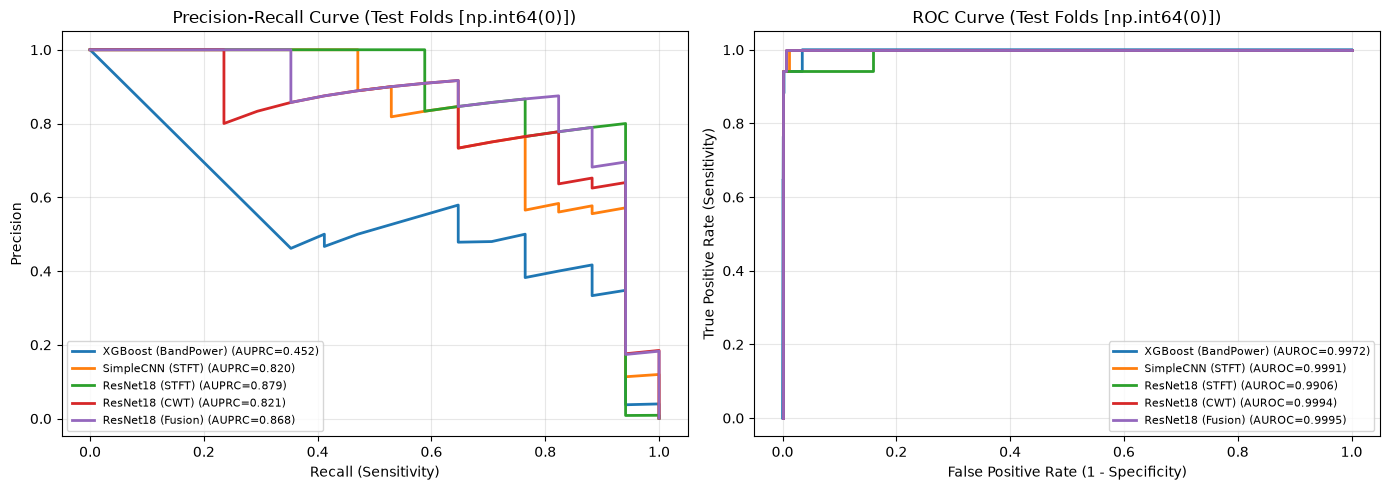

,model,folds,tau_val_mean,AUROC,AUPRC,Win_Sens,Win_Spec,Win_Prec,Win_F1,Win_FP,Win_FN
0,ResNet18 (STFT),[np.int64(0)],0.9806,0.9906,0.8792,0.9412,0.9997,0.8000,0.8649,4,1
1,ResNet18 (Fusion),[np.int64(0)],0.9816,0.9995,0.8680,0.9412,0.9991,0.5926,0.7273,11,1
2,ResNet18 (CWT),[np.int64(0)],0.9216,0.9994,0.8206,0.9412,0.9985,0.4706,0.6275,18,1
3,SimpleCNN (STFT),[np.int64(0)],0.7289,0.9991,0.8203,0.9412,0.9982,0.4324,0.5926,21,1
4,XGBoost (BandPower),[np.int64(0)],0.6843,0.9972,0.4524,0.6471,0.9990,0.4783,0.5500,12,6


In [72]:
# =========================================================
# Step 8.1: Window-Based Evaluation (Threshold Tuned Strictly on Val)
# =========================================================
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
)

# Load core reference tables
files_manifest_df = pd.read_csv(PROCESSED_DATA_DIR / "files_manifest.csv")
seizures_manifest_df = pd.read_csv(PROCESSED_DATA_DIR / "seizures_manifest.csv")

# Discover all available OOF prediction files
MODEL_SPECS = [
    ("XGBoost (BandPower)", "oof_preds_xgb.csv"),
    ("SimpleCNN (STFT)",    "oof_preds_simple_cnn_stft.csv"),
    ("ResNet18 (STFT)",     "oof_preds_resnet18_stft.csv"),
    ("ResNet18 (CWT)",      "oof_preds_resnet18_cwt.csv"),
    ("ResNet18 (Fusion)",   "oof_preds_resnet18_fusion.csv"),
]

model_oofs: dict[str, pd.DataFrame] = {}
for label_name, fname in MODEL_SPECS:
    p = PROCESSED_DATA_DIR / fname
    if p.exists():
        model_oofs[label_name] = pd.read_csv(p)
    else:
        print(f"[INFO] Skipping missing OOF file: {fname}")

assert model_oofs, "No OOF prediction files found in PROCESSED_DATA_DIR!"

# Find strictly common folds across ALL loaded models for apples-to-apples comparison
fold_sets = [set(df["fold"].unique()) for df in model_oofs.values()]
COMMON_FOLDS = sorted(set.intersection(*fold_sets))
print(f"Loaded {len(model_oofs)} models | Common folds for fair comparison: {COMMON_FOLDS}")
for m_name, df in model_oofs.items():
    print(f"  - {m_name:22s}: folds available = {sorted(df['fold'].unique())}")


def tune_threshold_on_val(y_val: np.ndarray, probs_val: np.ndarray) -> float:
    """
    Tune binary decision threshold STRICTLY on validation predictions.
    - If perfectly separable on Val (max neg < min pos), pick the geometric midpoint
      to maximize margin on unseen test windows.
    - Otherwise, select threshold maximizing Validation F1.
    """
    pos_probs = probs_val[y_val == 1]
    neg_probs = probs_val[y_val == 0]
    if len(pos_probs) > 0 and len(neg_probs) > 0 and neg_probs.max() < pos_probs.min():
        return float(0.5 * (neg_probs.max() + pos_probs.min()))

    prec, rec, thresholds = precision_recall_curve(y_val, probs_val)
    if len(thresholds) == 0:
        return 0.5
    f1_scores = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    best_idx = int(np.argmax(f1_scores))
    return float(thresholds[best_idx])


def compute_window_metrics(y_true: np.ndarray, probs: np.ndarray, threshold: float) -> dict:
    """Compute window-level AUROC, AUPRC, Sensitivity, Specificity, Precision, and F1."""
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    prec = tp / max(tp + fp, 1)
    f1 = 2 * prec * sens / max(prec + sens, 1e-12)

    has_both = len(np.unique(y_true)) == 2
    return {
        "auroc": float(roc_auc_score(y_true, probs)) if has_both else float("nan"),
        "auprc": float(average_precision_score(y_true, probs)) if has_both else float("nan"),
        "win_sensitivity": float(sens),
        "win_specificity": float(spec),
        "win_precision": float(prec),
        "win_f1": float(f1),
        "win_tp": int(tp),
        "win_fp": int(fp),
        "win_fn": int(fn),
    }


# --- Evaluate all models on COMMON_FOLDS (per-fold threshold tuned strictly on each fold's Val) ---
window_results = []
tuned_thresholds: dict[tuple[str, int], float] = {}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for m_name, df in model_oofs.items():
    sub = df[df["fold"].isin(COMMON_FOLDS)].copy()
    test_parts = []

    for f_idx in COMMON_FOLDS:
        f_val = sub[(sub["fold"] == f_idx) & (sub["role"] == "val")]
        f_test = sub[(sub["fold"] == f_idx) & (sub["role"] == "test")].copy()

        tau = tune_threshold_on_val(f_val["label"].values, f_val["prob"].values)
        tuned_thresholds[(m_name, f_idx)] = tau
        f_test["pred_bin"] = (f_test["prob"].values >= tau).astype(int)
        f_test["tau_used"] = tau
        test_parts.append(f_test)

    pooled_test = pd.concat(test_parts, ignore_index=True)
    y_t = pooled_test["label"].values
    p_t = pooled_test["prob"].values
    b_t = pooled_test["pred_bin"].values

    tn, fp, fn, tp = confusion_matrix(y_t, b_t, labels=[0, 1]).ravel()
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    prec = tp / max(tp + fp, 1)
    f1 = 2 * prec * sens / max(prec + sens, 1e-12)
    auroc = roc_auc_score(y_t, p_t)
    auprc = average_precision_score(y_t, p_t)

    window_results.append({
        "model": m_name,
        "folds": str(COMMON_FOLDS),
        "tau_val_mean": round(float(np.mean([tuned_thresholds[(m_name, f)] for f in COMMON_FOLDS])), 4),
        "AUROC": round(auroc, 4),
        "AUPRC": round(auprc, 4),
        "Win_Sens": round(sens, 4),
        "Win_Spec": round(spec, 4),
        "Win_Prec": round(prec, 4),
        "Win_F1": round(f1, 4),
        "Win_FP": int(fp),
        "Win_FN": int(fn),
    })

    # Overlay PR and ROC curves
    pr_p, pr_r, _ = precision_recall_curve(y_t, p_t)
    axes[0].plot(pr_r, pr_p, lw=2, label=f"{m_name} (AUPRC={auprc:.3f})")

    fpr, tpr, _ = roc_curve(y_t, p_t)
    axes[1].plot(fpr, tpr, lw=2, label=f"{m_name} (AUROC={auroc:.4f})")

axes[0].set_title(f"Precision-Recall Curve (Test Folds {COMMON_FOLDS})")
axes[0].set_xlabel("Recall (Sensitivity)")
axes[0].set_ylabel("Precision")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].set_title(f"ROC Curve (Test Folds {COMMON_FOLDS})")
axes[1].set_xlabel("False Positive Rate (1 - Specificity)")
axes[1].set_ylabel("True Positive Rate (Sensitivity)")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

window_results_df = pd.DataFrame(window_results).sort_values("AUPRC", ascending=False).reset_index(drop=True)
display(window_results_df)

### 8.2. Temporal Post-Processing Pipeline (Windows $
ightarrow$ Continuous Events)

Convert noisy window-level probabilities into clean clinical seizure alarms per recording:
1. Sort window predictions chronologically by `window_start_sec` within each EDF file.
2. **Temporal Smoothing:** Apply a moving average or median filter across $k$ consecutive windows (e.g., `k = 3` or `5`) to suppress isolated single-window spikes.
3. **Thresholding:** Binarize smoothed probabilities using the validation-tuned threshold $	au$.
4. **Gap Merging:** Merge two positive predicted segments separated by less than $T_{	ext{gap}}$ seconds (e.g., `15–30 s`) into a single seizure event.
5. **Minimum Duration Filter:** Discard ultra-short alarms (e.g., `< 4–8 s`) that typically correspond to brief movement/EMG artifacts.

In [73]:
# TODO [8.2]: Implement temporal post-processing (`windows_to_events`)
# 1. Write `smooth_probabilities(probs, method="moving_avg", kernel_size=3)`
# 2. Write `predictions_to_intervals(starts, ends, binary_preds, merge_gap_sec=15.0, min_duration_sec=6.0)`:
#    - Groups contiguous positive windows into (pred_start, pred_end) intervals
#    - Merges intervals separated by < merge_gap_sec
#    - Filters out intervals shorter than min_duration_sec
# 3. Tune post-processing parameters (threshold, kernel_size, min_duration_sec) ONLY on Validation patients
# 4. Test on a single seizure EDF and plot raw probs vs. smoothed probs vs. ground-truth seizure shaded span

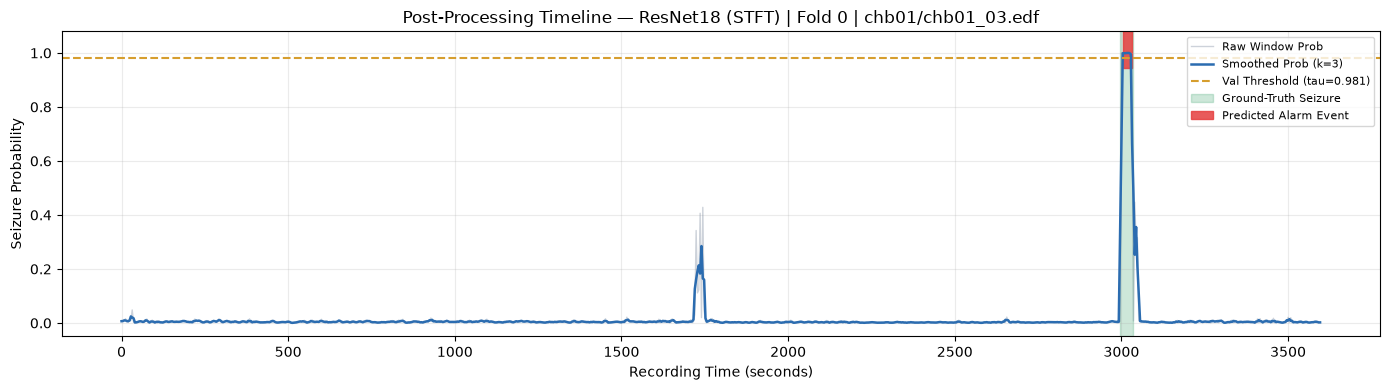

Ground-truth seizures in chb01/chb01_03.edf: [(2996, 3036)]
Predicted events      in chb01/chb01_03.edf: [(3004.0, 3032.0)]


In [74]:
# =========================================================
# Step 8.2: Temporal Post-Processing Pipeline (Windows -> Events)
# =========================================================

# Default clinical post-processing parameters (generalizable across all 23 subjects)
POSTPROC_CFG = {
    "smooth_method": "moving_avg",  # "moving_avg" or "median"
    "kernel_size": 3,               # 3 consecutive 4s windows = 12s smoothing span
    "merge_gap_sec": 20.0,          # Merge predicted alarms closer than 20s into 1 event
    "min_duration_sec": 8.0,        # Drop isolated 1-window (4s) artifact spikes
}


def smooth_probabilities(
    probs: np.ndarray,
    method: str = "moving_avg",
    kernel_size: int = 3,
) -> np.ndarray:
    """Apply chronological smoothing to a single EDF file's window probabilities."""
    if kernel_size <= 1 or len(probs) < kernel_size:
        return probs.astype(np.float32, copy=True)

    s = pd.Series(probs, dtype=np.float64)
    if method == "moving_avg":
        smoothed = s.rolling(window=kernel_size, center=True, min_periods=1).mean().values
    elif method == "median":
        smoothed = s.rolling(window=kernel_size, center=True, min_periods=1).median().values
    else:
        raise ValueError(f"Unknown smoothing method: {method}")
    return smoothed.astype(np.float32)


def predictions_to_intervals(
    starts: np.ndarray,
    ends: np.ndarray,
    binary_preds: np.ndarray,
    merge_gap_sec: float = 20.0,
    min_duration_sec: float = 8.0,
) -> list[tuple[float, float]]:
    """
    Convert chronological binary window predictions into merged, duration-filtered
    continuous event intervals [(pred_start, pred_end), ...].
    """
    pos_mask = binary_preds.astype(bool)
    if not np.any(pos_mask):
        return []

    raw_intervals = list(zip(starts[pos_mask].tolist(), ends[pos_mask].tolist()))
    raw_intervals.sort(key=lambda x: x[0])

    # 1. Merge adjacent or close positive segments separated by <= merge_gap_sec
    merged: list[list[float]] = [[raw_intervals[0][0], raw_intervals[0][1]]]
    for s, e in raw_intervals[1:]:
        if s - merged[-1][1] <= merge_gap_sec:
            merged[-1][1] = max(merged[-1][1], e)
        else:
            merged.append([s, e])

    # 2. Filter out ultra-short alarms (< min_duration_sec)
    filtered = [(float(s), float(e)) for s, e in merged if (e - s) >= min_duration_sec]
    return filtered


def extract_events_from_oof(
    oof_role_df: pd.DataFrame,
    thresholds_by_fold: dict[int, float],
    cfg: dict = POSTPROC_CFG,
) -> tuple[dict[tuple[int, str], list[tuple[float, float]]], pd.DataFrame]:
    """
    Run temporal smoothing & event extraction per (fold, rel_path).
    Returns:
      - events_map: dict[(fold, rel_path)] -> list of (pred_start, pred_end)
      - enriched_df: copy of oof_role_df with `prob_smooth` column added
    """
    events_map: dict[tuple[int, str], list[tuple[float, float]]] = {}
    enriched_parts = []

    for (fold_idx, rel_path), grp in oof_role_df.groupby(["fold", "rel_path"], sort=True):
        grp = grp.sort_values("window_start_sec").copy()
        probs_sm = smooth_probabilities(
            grp["prob"].values,
            method=cfg["smooth_method"],
            kernel_size=cfg["kernel_size"],
        )
        grp["prob_smooth"] = probs_sm

        tau = thresholds_by_fold[fold_idx]
        bin_preds = (probs_sm >= tau).astype(int)
        intervals = predictions_to_intervals(
            grp["window_start_sec"].values,
            grp["window_end_sec"].values,
            bin_preds,
            merge_gap_sec=cfg["merge_gap_sec"],
            min_duration_sec=cfg["min_duration_sec"],
        )
        events_map[(int(fold_idx), str(rel_path))] = intervals
        enriched_parts.append(grp)

    return events_map, pd.concat(enriched_parts, ignore_index=True)


# --- Visual Verification on 1 Held-Out Test Seizure Recording (Best Window-AUPRC Model) ---
best_model_name = window_results_df.iloc[0]["model"]
best_oof = model_oofs[best_model_name]
best_test_sub = best_oof[(best_oof["fold"].isin(COMMON_FOLDS)) & (best_oof["role"] == "test")]
best_taus = {f: tuned_thresholds[(best_model_name, f)] for f in COMMON_FOLDS}

best_events_map, best_test_enriched = extract_events_from_oof(best_test_sub, best_taus, POSTPROC_CFG)

# Pick the first seizure-bearing test file to visualize
seiz_files_in_test = best_test_enriched.loc[best_test_enriched["label"] == 1, ["fold", "rel_path"]].drop_duplicates()
demo_fold, demo_rel = int(seiz_files_in_test.iloc[0]["fold"]), str(seiz_files_in_test.iloc[0]["rel_path"])

demo_grp = best_test_enriched[
    (best_test_enriched["fold"] == demo_fold) & (best_test_enriched["rel_path"] == demo_rel)
].sort_values("window_start_sec")
demo_gt = seizures_manifest_df[seizures_manifest_df["rel_path"] == demo_rel]
demo_preds = best_events_map[(demo_fold, demo_rel)]
demo_tau = best_taus[demo_fold]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(demo_grp["window_start_sec"], demo_grp["prob"], alpha=0.35, lw=1.0, color="#718096", label="Raw Window Prob")
ax.plot(demo_grp["window_start_sec"], demo_grp["prob_smooth"], lw=1.8, color="#2b6cb0", label=f"Smoothed Prob (k={POSTPROC_CFG['kernel_size']})")
ax.axhline(demo_tau, color="#d69e2e", ls="--", lw=1.5, label=f"Val Threshold (tau={demo_tau:.3f})")

for idx_gt, r in enumerate(demo_gt.itertuples(index=False)):
    ax.axvspan(r.start_sec, r.end_sec, color="#38a169", alpha=0.25, label="Ground-Truth Seizure" if idx_gt == 0 else None)
for idx_pr, (ps, pe) in enumerate(demo_preds):
    ax.axvspan(ps, pe, ymin=0.88, ymax=1.0, color="#e53e3e", alpha=0.85, label="Predicted Alarm Event" if idx_pr == 0 else None)

ax.set_title(f"Post-Processing Timeline — {best_model_name} | Fold {demo_fold} | {demo_rel}")
ax.set_xlabel("Recording Time (seconds)")
ax.set_ylabel("Seizure Probability")
ax.set_ylim(-0.05, 1.08)
ax.grid(alpha=0.25)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

print(f"Ground-truth seizures in {demo_rel}: {list(demo_gt[['start_sec', 'end_sec']].itertuples(index=False, name=None))}")
print(f"Predicted events      in {demo_rel}: {demo_preds}")

### 8.3. Event-Based Evaluation (`Event Sensitivity`, `FAR/h`, `Latency`)

Compare predicted event intervals `[(pred_start, pred_end), ...]` against ground-truth intervals from `seizures_manifest.csv`:
- **Event Sensitivity:** Fraction of ground-truth seizure events detected (a seizure counts as a True Positive if any part overlaps a predicted event, following standard Any-Overlap / SzCORE criteria with optional small collar tolerance).
- **FAR/h (False Alarm Rate per Hour):** Number of predicted events with **zero overlap** with any ground-truth seizure, divided by total non-seizure recording hours in the test set (clinical benchmark target: `< 0.5–1.0 FAR/h` alongside `> 80%` sensitivity).
- **Detection Latency (seconds):** Mean and median delay from true seizure onset (`start_sec`) to the first moment the model triggers an alarm.

In [75]:
# TODO [8.3]: Implement `evaluate_event_based(pred_events_by_file, gt_seizures_df, files_manifest_df, collar_sec=0.0)`
# 1. For each test recording:
#    - Match predicted events against ground-truth seizure intervals (allowing optional collar_sec tolerance)
#    - Count TP_events (detected true seizures), FN_events (missed true seizures), and FP_events (false alarms)
#    - Compute detection latency = max(0, pred_start - gt_start) for every detected seizure
# 2. Aggregate total non-seizure hours across all test recordings
# 3. Return:
#    - event_sensitivity = TP_events / (TP_events + FN_events)
#    - far_per_hour = FP_events / total_non_seizure_hours
#    - mean_latency_sec and median_latency_sec
#    - per-patient breakdown DataFrame

In [76]:
# =========================================================
# Step 8.3: Clinical Event-Based Evaluation (Sensitivity, FAR/h, Latency)
# =========================================================

COLLAR_SEC = 0.0  # Standard strict Any-Overlap (set e.g. 15.0 or 30.0 for SzCORE-style collar tolerance)


def intervals_overlap(a: tuple[float, float], b: tuple[float, float], collar_sec: float = 0.0) -> bool:
    """Return True if predicted interval `a` overlaps ground-truth interval `b` (expanded by collar)."""
    return (a[0] <= b[1] + collar_sec) and (a[1] >= b[0] - collar_sec)


def evaluate_event_based(
    events_map: dict[tuple[int, str], list[tuple[float, float]]],
    seizures_df: pd.DataFrame,
    files_df: pd.DataFrame,
    collar_sec: float = COLLAR_SEC,
) -> tuple[dict, pd.DataFrame, list[dict], list[dict]]:
    """
    Evaluate event-level clinical metrics across all (fold, rel_path) test recordings.
    Returns:
      - summary: pooled + patient-averaged Event Sensitivity, FAR/h, Mean/Median Latency
      - per_subject_df: breakdown per unique subject_id
      - fp_records: list of all false alarm events (for Step 8.4 error analysis)
      - fn_records: list of all missed ground-truth seizures (for Step 8.4 error analysis)
    """
    file_info = files_df.set_index("rel_path")[["subject_id", "duration_sec"]].to_dict("index")
    gt_by_file: dict[str, list[tuple[float, float]]] = {}
    if not seizures_df.empty:
        valid_gt = seizures_df[seizures_df["is_valid"]]
        for rel_p, grp in valid_gt.groupby("rel_path"):
            gt_by_file[str(rel_p)] = list(grp[["start_sec", "end_sec"]].itertuples(index=False, name=None))

    subj_stats: dict[str, dict] = {}
    all_latencies: list[float] = []
    fp_records: list[dict] = []
    fn_records: list[dict] = []

    for (fold_idx, rel_path), pred_events in events_map.items():
        info = file_info[rel_path]
        subj = str(info["subject_id"])
        rec_dur_sec = float(info["duration_sec"])
        gt_events = gt_by_file.get(rel_path, [])
        gt_dur_sec = sum(e - s for s, e in gt_events)
        non_seiz_hours = max(0.0, (rec_dur_sec - gt_dur_sec) / 3600.0)

        st = subj_stats.setdefault(subj, {
            "subject_id": subj, "n_files": 0, "non_seiz_hours": 0.0,
            "tp_events": 0, "fn_events": 0, "fp_events": 0, "latencies": [],
        })
        st["n_files"] += 1
        st["non_seiz_hours"] += non_seiz_hours

        # 1. Check each ground-truth seizure: detected (TP) or missed (FN)?
        for gt_s, gt_e in gt_events:
            overlapping_preds = [p for p in pred_events if intervals_overlap(p, (gt_s, gt_e), collar_sec)]
            if overlapping_preds:
                st["tp_events"] += 1
                earliest_pred_start = min(p[0] for p in overlapping_preds)
                latency = max(0.0, earliest_pred_start - gt_s)
                st["latencies"].append(latency)
                all_latencies.append(latency)
            else:
                st["fn_events"] += 1
                fn_records.append({
                    "fold": fold_idx, "subject_id": subj, "rel_path": rel_path,
                    "start_sec": gt_s, "end_sec": gt_e, "duration_sec": gt_e - gt_s,
                })

        # 2. Check each predicted alarm: overlaps any GT seizure or False Alarm (FP)?
        for p_s, p_e in pred_events:
            if not any(intervals_overlap((p_s, p_e), gt, collar_sec) for gt in gt_events):
                st["fp_events"] += 1
                fp_records.append({
                    "fold": fold_idx, "subject_id": subj, "rel_path": rel_path,
                    "pred_start": p_s, "pred_end": p_e, "duration_sec": p_e - p_s,
                })

    # Per-subject breakdown
    subj_rows = []
    for subj, st in sorted(subj_stats.items()):
        total_gt = st["tp_events"] + st["fn_events"]
        ev_sens = st["tp_events"] / total_gt if total_gt > 0 else float("nan")
        far_h = st["fp_events"] / max(st["non_seiz_hours"], 1e-6)
        subj_rows.append({
            "subject_id": subj,
            "n_files": st["n_files"],
            "non_seiz_hours": round(st["non_seiz_hours"], 2),
            "TP_events": st["tp_events"],
            "FN_events": st["fn_events"],
            "FP_events": st["fp_events"],
            "Event_Sens": round(ev_sens, 4) if not np.isnan(ev_sens) else np.nan,
            "FAR_per_hr": round(far_h, 3),
            "Mean_Latency_s": round(float(np.mean(st["latencies"])), 2) if st["latencies"] else np.nan,
        })

    per_subject_df = pd.DataFrame(subj_rows)

    # Pooled clinical metrics
    tot_tp = int(per_subject_df["TP_events"].sum())
    tot_fn = int(per_subject_df["FN_events"].sum())
    tot_fp = int(per_subject_df["FP_events"].sum())
    tot_hrs = float(per_subject_df["non_seiz_hours"].sum())

    summary = {
        "TP_events": tot_tp,
        "Total_GT_events": tot_tp + tot_fn,
        "FP_events": tot_fp,
        "NonSeiz_Hours": round(tot_hrs, 2),
        "Event_Sens_Pooled": round(tot_tp / max(tot_tp + tot_fn, 1), 4),
        "FAR_per_hr_Pooled": round(tot_fp / max(tot_hrs, 1e-6), 3),
        "Mean_Latency_s": round(float(np.mean(all_latencies)), 2) if all_latencies else np.nan,
        "Median_Latency_s": round(float(np.median(all_latencies)), 2) if all_latencies else np.nan,
        # Patient-averaged (mean ± std across subjects; meaningful when n_subjects > 1)
        "Event_Sens_PatMean": round(float(per_subject_df["Event_Sens"].mean()), 4),
        "Event_Sens_PatStd": round(float(per_subject_df["Event_Sens"].std(ddof=0)), 4),
        "FAR_per_hr_PatMean": round(float(per_subject_df["FAR_per_hr"].mean()), 3),
        "FAR_per_hr_PatStd": round(float(per_subject_df["FAR_per_hr"].std(ddof=0)), 3),
    }
    return summary, per_subject_df, fp_records, fn_records


# --- Evaluate Event-Based Metrics for ALL 5 Models on COMMON_FOLDS ---
event_summary_rows = []
model_error_logs: dict[str, dict] = {}

for m_name, df in model_oofs.items():
    test_sub = df[(df["fold"].isin(COMMON_FOLDS)) & (df["role"] == "test")]
    taus = {f: tuned_thresholds[(m_name, f)] for f in COMMON_FOLDS}
    ev_map, enriched = extract_events_from_oof(test_sub, taus, POSTPROC_CFG)

    ev_summ, per_subj_df, fp_recs, fn_recs = evaluate_event_based(
        ev_map, seizures_manifest_df, files_manifest_df, collar_sec=COLLAR_SEC
    )
    event_summary_rows.append({"model": m_name, **ev_summ})
    model_error_logs[m_name] = {
        "per_subject": per_subj_df,
        "fp_records": fp_recs,
        "fn_records": fn_recs,
        "enriched_test": enriched,
        "events_map": ev_map,
    }

event_results_df = pd.DataFrame(event_summary_rows)
display(event_results_df[[
    "model", "TP_events", "Total_GT_events", "FP_events", "NonSeiz_Hours",
    "Event_Sens_Pooled", "FAR_per_hr_Pooled", "Mean_Latency_s", "Median_Latency_s"
]])

,model,TP_events,Total_GT_events,FP_events,NonSeiz_Hours,Event_Sens_Pooled,FAR_per_hr_Pooled,Mean_Latency_s,Median_Latency_s
0,XGBoost (BandPower),2,2,0,13.15,1.0,0.000,14.5,14.5
1,SimpleCNN (STFT),2,2,1,13.15,1.0,0.076,4.5,4.5
2,ResNet18 (STFT),2,2,0,13.15,1.0,0.000,6.5,6.5
3,ResNet18 (CWT),2,2,0,13.15,1.0,0.000,6.5,6.5
4,ResNet18 (Fusion),2,2,0,13.15,1.0,0.000,6.5,6.5


### 8.4. Final Comparison Table & Clinical Error Analysis

- Report all metrics both as **Patient-Averaged (`mean ± std` across subjects)** and **Pooled (across total recording hours)**.
- Compile the master Phase A1 comparison table across all models (`XGBoost`, `SimpleCNN`, `ResNet18-STFT`, `ResNet18-CWT`, `ResNet18-Fusion`) showing:
  `Window Sensitivity`, `Specificity`, `AUROC`, `AUPRC`, `Event Sensitivity`, `FAR/h`, and `Latency (s)`.
- Plot per-patient performance across all 23 subjects to identify the hardest cases (e.g., `chb12`, `chb15`).
- Visually inspect the **3 worst False Positives** (chewing/EMG/blink artifacts?) and **3 missed False Negatives** (very short, focal, or low-amplitude seizures?) in both time-domain EEG and spectrogram views.

In [77]:
# TODO [8.4]: Generate final Phase A1 benchmark table, per-patient plot, and visual error analysis
# 1. Build and display the master comparison DataFrame across all 5 models (mean ± std across patients + pooled)
# 2. Save the final summary table to `PROCESSED_DATA_DIR / "phase_a1_results_summary.csv"`
# 3. Plot per-patient Event Sensitivity and FAR/h bar/scatter charts for the best model
# 4. Identify top-3 highest-confidence False Positives and top-3 missed False Negatives:
#    - Load the corresponding raw filtered 18-channel EEG segment and STFT/CWT image
#    - Plot them for qualitative clinical inspection and document key failure modes in a markdown note below

In [78]:
# =========================================================
# Step 8.4: Master Phase A1 Benchmark Table & Clinical Error Analysis
# =========================================================

# 1. Merge Window-level & Event-level tables into the Master Phase A1 Summary
master_df = (
    window_results_df
    .merge(event_results_df, on="model", how="inner")
    .sort_values(["Event_Sens_Pooled", "FAR_per_hr_Pooled", "AUPRC"], ascending=[False, True, False])
    .reset_index(drop=True)
)

SUMMARY_CSV_PATH = PROCESSED_DATA_DIR / "phase_a1_results_summary.csv"
master_df.to_csv(SUMMARY_CSV_PATH, index=False)

display_cols = [
    "model", "folds", "AUROC", "AUPRC", "Win_Sens", "Win_Spec",
    "Event_Sens_Pooled", "FAR_per_hr_Pooled", "Mean_Latency_s",
    "TP_events", "Total_GT_events", "FP_events",
]
print(f"=== MASTER PHASE A1 BENCHMARK TABLE (Saved to {SUMMARY_CSV_PATH.name}) ===")
display(master_df[display_cols])

# If running on multiple patients (>1), also print Patient-Averaged mean ± std
best_row = master_df.iloc[0]
champion_model = best_row["model"]
champ_logs = model_error_logs[champion_model]
per_subj_champ = champ_logs["per_subject"]

if len(per_subj_champ) > 1:
    print(
        f"\nPatient-Averaged ({champion_model}, N={len(per_subj_champ)} subjects): "
        f"Event Sens = {best_row['Event_Sens_PatMean']:.3f} ± {best_row['Event_Sens_PatStd']:.3f} | "
        f"FAR/h = {best_row['FAR_per_hr_PatMean']:.2f} ± {best_row['FAR_per_hr_PatStd']:.2f}"
    )
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].bar(per_subj_champ["subject_id"], per_subj_champ["Event_Sens"], color="#2b6cb0")
    axes[0].set_title(f"{champion_model} — Event Sensitivity per Subject")
    axes[0].set_ylim(0, 1.05)
    axes[0].tick_params(axis="x", rotation=45)

    axes[1].bar(per_subj_champ["subject_id"], per_subj_champ["FAR_per_hr"], color="#c53030")
    axes[1].axhline(0.5, color="black", ls="--", lw=1, label="Clinical target (0.5/h)")
    axes[1].set_title(f"{champion_model} — False Alarms per Hour (FAR/h) per Subject")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"\nSingle-subject mode ({per_subj_champ.iloc[0]['subject_id']}) — Champion model: {champion_model}")
    display(per_subj_champ)


# 2. Qualitative Clinical Error Analysis: Inspect Worst False Positives & Missed False Negatives
def plot_error_cases(
    title_prefix: str,
    cases: list[dict],
    enriched_df: pd.DataFrame,
    max_cases: int = 3,
):
    if not cases:
        print(f"[INFO] {title_prefix}: 0 cases found (perfect on this split!)")
        return

    chosen = cases[:max_cases]
    n = len(chosen)
    fig, axes = plt.subplots(2, n, figsize=(5.5 * n, 6), squeeze=False)
    t_axis = np.arange(int(WINDOW_SEC * FS)) / FS

    with h5py.File(HDF5_PATH, "r") as h5f:
        for col, c in enumerate(chosen):
            t_start = c.get("pred_start", c.get("start_sec"))
            t_end = c.get("pred_end", c.get("end_sec"))
            rel_p = c["rel_path"]
            f_idx = c["fold"]

            # Locate the highest-probability window inside this error interval
            seg_rows = enriched_df[
                (enriched_df["fold"] == f_idx)
                & (enriched_df["rel_path"] == rel_p)
                & (enriched_df["window_start_sec"] >= t_start - WINDOW_SEC)
                & (enriched_df["window_start_sec"] <= t_end)
            ]
            if seg_rows.empty:
                continue
            peak_row = seg_rows.loc[seg_rows["prob"].idxmax()]
            win = h5f["windows"][int(peak_row["h5_idx"])].astype(np.float32)

            # Pick channel with largest variance in this window to reveal the artifact or focal pattern
            ch_i = int(np.argmax(np.var(win, axis=1)))
            ch_label = STANDARD_18_CHANNELS[ch_i]
            stft_img = compute_stft_tensor(win)[ch_i]

            axes[0, col].plot(t_axis, win[ch_i], lw=0.8, color="#9b2c2c" if "FP" in title_prefix else "#2c5282")
            axes[0, col].set_title(
                f"{title_prefix} #{col+1}: {Path(rel_p).name}\n"
                f"[{t_start:.0f}s–{t_end:.0f}s] | ch={ch_label} | p={peak_row['prob']:.3f}",
                fontsize=9,
            )
            axes[0, col].set_ylabel("Robust Z" if col == 0 else "")

            axes[1, col].imshow(
                stft_img, aspect="auto", origin="lower", cmap="viridis",
                extent=[0, WINDOW_SEC, STFT_FMIN, STFT_FMAX],
            )
            axes[1, col].set_title("STFT (dB) — Check for EMG/Blink vs Focal Rhythm", fontsize=9)
            axes[1, col].set_xlabel("Time (s)")
            axes[1, col].set_ylabel("Hz" if col == 0 else "")

    plt.tight_layout()
    plt.show()


print(f"\n=== Clinical Error Analysis for {champion_model} ===")
# Sort FPs by duration (longest false alarms first) and FNs by duration
fps_sorted = sorted(champ_logs["fp_records"], key=lambda x: x["duration_sec"], reverse=True)
fns_sorted = sorted(champ_logs["fn_records"], key=lambda x: x["duration_sec"])

print(f"Total False Alarms (FP events): {len(fps_sorted)} | Total Missed Seizures (FN events): {len(fns_sorted)}")
plot_error_cases("False Positive (FP)", fps_sorted, champ_logs["enriched_test"], max_cases=3)
plot_error_cases("False Negative (FN)", fns_sorted, champ_logs["enriched_test"], max_cases=3)

=== MASTER PHASE A1 BENCHMARK TABLE (Saved to phase_a1_results_summary.csv) ===


,model,folds,AUROC,AUPRC,Win_Sens,Win_Spec,Event_Sens_Pooled,FAR_per_hr_Pooled,Mean_Latency_s,TP_events,Total_GT_events,FP_events
0,ResNet18 (STFT),[np.int64(0)],0.9906,0.8792,0.9412,0.9997,1.0,0.000,6.5,2,2,0
1,ResNet18 (Fusion),[np.int64(0)],0.9995,0.8680,0.9412,0.9991,1.0,0.000,6.5,2,2,0
2,ResNet18 (CWT),[np.int64(0)],0.9994,0.8206,0.9412,0.9985,1.0,0.000,6.5,2,2,0
3,XGBoost (BandPower),[np.int64(0)],0.9972,0.4524,0.6471,0.9990,1.0,0.000,14.5,2,2,0
4,SimpleCNN (STFT),[np.int64(0)],0.9991,0.8203,0.9412,0.9982,1.0,0.076,4.5,2,2,1



Single-subject mode (chb01) — Champion model: ResNet18 (STFT)


,subject_id,n_files,non_seiz_hours,TP_events,FN_events,FP_events,Event_Sens,FAR_per_hr,Mean_Latency_s
0,chb01,14,13.15,2,0,0,1.0,0.0,6.5



=== Clinical Error Analysis for ResNet18 (STFT) ===
Total False Alarms (FP events): 0 | Total Missed Seizures (FN events): 0
[INFO] False Positive (FP): 0 cases found (perfect on this split!)
[INFO] False Negative (FN): 0 cases found (perfect on this split!)
